# INFO-F422 Statistical Foundations of Machine Learning
**Project 2025-2026 : MIMO NARX System Identification**

**Team Membres - id: 0002 - Team 10-1**
| Name | GitHub User |
|-------|-------|
 Kamila Obregon    | kmor8 
 Guillame Poth     | GuillaumePoth
 Hamza Raoui       | hamza-RAOUI

Introduction

This work addresses the challenge of system identification for discrete-time Multi-Input Multi-Output (MIMO) Nonlinear AutoRegressive eXogenous (NARX) models. The objective is to develop a comprehensive machine learning pipeline that can infer the input-output dynamics of an unknown nonlinear system solely from observed data.

Given a training dataset comprising two input series $u_1, u_2$ and two output series $y_1, y_2$, the pipeline is required to learn the functions $f_1$ and $f_2$ that govern the system dynamics:

$$
y_1(k+1) = f_1\Big(
y_1(k-d),, y_1(k-d-1),, \ldots,, y_1(k-d-n_a), \
y_2(k-d),, y_2(k-d-1),, \ldots,, y_2(k-d-n_a), \
u_1(k),, \ldots,, u_1(k-n_b),,
u_2(k),, \ldots,, u_2(k-n_b)
\Big) + w_1(k+1)
$$

$$
y_2(k+1) = f_2\Big(
y_1(k-d),, y_1(k-d-1),, \ldots,, y_1(k-d-n_a), \
y_2(k-d),, y_2(k-d-1),, \ldots,, y_2(k-d-n_a), \
u_1(k),, \ldots,, u_1(k-n_b),,
u_2(k),, \ldots,, u_2(k-n_b)
\Big) + w_2(k+1)
$$

In addition, the pipeline must estimate the structural parameters, including the delay $d$, the output lag $n_a$, and the input lag $n_b$.

where:

* The non-negative integer $k \in \mathbb{Z}_{\geq 0}$ denotes the discrete-time index,
* The non-negative integer $d \in \mathbb{Z}_{\geq 0}$ represents the system delay,
* The non-negative integer $n_a \in \mathbb{Z}_{\geq 0}$ denotes the output lag,
* The non-negative integer $n_b \in \mathbb{Z}_{\geq 0}$ denotes the input lag,
* The noise signals $\mathbf{w}_1 \sim \mathcal{N}(0, \sigma^2)$ and $\mathbf{w}_2 \sim \mathcal{N}(0, \sigma^2)$ are independent and identically distributed (i.i.d.) and follow a normal distribution with zero mean.

Dataset

Column 1	Column 2	Column 3	Column 4
Split	Array	Shape	Description
Train	Utr	(1000, 2)	Training inputs $u_1, u_2$
Train	Ytr	(1000, 2)	Training outputs $y_1, y_2$
Test	Uts1	(1000, 2)	First test input series
Test	Uts2	(1000, 2)	Second test input series


All values prior to $k=0$ are assumed to be zero, that is, $y_1(0) = y_2(0) = u_1(0) = u_2(0) = 0$.

## Project Pipeline Overview

**Pre-Development**
- Imports and Global Utilities
    -  Global Values
- Evaluation Metrics
    - Root Mean Squared Error (RMSE)
    - Normalized Mean Squared Error (NMSE)
- Plotting Utilities
- References

**Development Phase**

- Task 1: Pilot Simulation
    Two known NARX systems (NARX2 with one input and NARX2 with two inputs) are simulated to validate the methodology prior to its application on the unknown real NARX system.

- Task 2: Machine Learning Strategy
    A review of strategies for simulating the NARX system is conducted, followed by the selection of parameter tuning methods for both systems. The optimal delay (d), output lag (n_a), and input lag (n_b) are identified.

    The most effective strategy for long-horizon prediction is determined and implemented.

- Task 3: Baseline Approach
    The previously implemented strategy is compared with four classical regressors using consistent feature representations.

- Task 4: Deep Learning Approach
    A feedforward multilayer perceptron (MLP) and a sequential long short-term memory (LSTM) network are implemented, both adapted to the previously used strategies.

- Task 5: Methodology Deployment
    The complete pipeline is tested on the real dataset ‘StudentdataNARXK.npz’ using model selection based on hold-out Normalized Mean Squared Error (NMSE).

- Task 6: Submission
    Finally, the output is prepared according to the submission requirements.

# Pre-Development Stage

## Library Imports and Global Utilities

The subsequent cells import the required libraries for this notebook. NumPy, Pandas, and scikit-learn are used for data processing, PyTorch for deep learning models, and matplotlib for data visualization.

In [1]:
%pip install numpy
%pip install matplotlib
%pip install pandas
%pip install scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import sys 

from pathlib import Path
from copy import deepcopy

from sklearn.model_selection import ParameterGrid, TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge, LinearRegression, RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import make_scorer
from sklearn.multioutput import MultiOutputRegressor

import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from typing import Any, Dict, Iterable, List, Optional, Tuple


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Global Values
In this section, the most global values for the entire code were assigned, including the alphas for RidgeCV, the random seed for reproducibility, and the parameters for training data generation.

In [ ]:
ALPHAS = np.logspace(-3,3,7) # for the alpha for RidgeCV
np.random.seed(8) # for reproducibility

## This is for the train data
N_narx1 = 1000
N_narx2 = 1000
split1 = int(N_narx1*0.7)
split2 = int(N_narx2*0.7)
sigma = 0.01

## Evaluation Metrics
### Root Mean Squared Error (RMSE)
The predictions $\hat{y}_1(k)$ and $\hat{y}_2(k)$ are evaluated jointly across both outputs using two quantitative metrics:

$$\text{RMSE} = \sqrt{\frac{1}{2N_{ts}}\sum_{k=1}^{N_{ts}}\sum_{j=1}^{2}\bigl(y_j^{ts}(k) - \hat{y}_j(k)\bigr)^2}$$

In [3]:
def rmse(y_t, y_p):
    assert  y_t.shape[1] == 2, "Expected y_t to have shape (N, 2)"
    N_ts= y_t.shape[0]

    total_e= np.sum((y_t - y_p)**2)
    return np.sqrt(total_e / (2 * N_ts))

### NMSE
$$\text{NMSE} = \frac{\sum_{k=1}^{N_{ts}}\sum_{j=1}^{2}\bigl(y_j^{ts}(k) - \hat{y}_j(k)\bigr)^2}{\sum_{k=1}^{N_{ts}}\sum_{j=1}^{2}\bigl(y_j^{ts}(k) - \bar{y}_j\bigr)^2}$$

Here, $\bar{y}_j$ denotes the mean of the $j$-th output over the test set. An NMSE value close to zero indicates a highly accurate model, while an NMSE of one corresponds to predicting the mean.

In [4]:
def nmse(y_t, y_p):
    yt_bar = y_t.mean(axis=0)
    num = np.sum((y_t - y_p)**2)
    den = np.sum((y_t - yt_bar)**2)
    return num/den

In this context,

* $N_{ts}$ denotes the total number of time steps in the validation/test sequence.
* $y_{j}^{ts}(k)$  indicates the ground-truth value for the $j$-th output at time $k$.
* $\hat{y}_{j}(k)$ denotes the model prediction for the $j$-th output at time $k$.
* $\bar{y}_{j}$ denotes the mean value of the $j$-th ground-truth output across the sequence.

## Plotting Utilities

These functions are used throughout the notebook to generate graphs.

* plot_1: Generates plots for single-channel time series data.
* plot_comparison: Overlays forecast data with actual observations for comparison.

In [5]:
def plot_1(array, title="Signal Plot", label="Data"): 
    plt.figure(figsize=(20, 4))
    plt.plot(array, label=label, color='blue')
    plt.title(title)
    plt.xlabel("Time (k)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [6]:
def plot_comparison (y_true, y_pred, title=""):
    t = np.arange(len(y_true))
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    axes[0].plot(t, y_true[:, 0], color='#1f77b4', linewidth=1.6, label='True output')
    axes[0].plot(t, y_pred[:, 0], color='#17becf', linewidth=1.6, linestyle='--', label='Recursive prediction')
    axes[0].set_ylabel('y1')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='upper right')

    axes[1].plot(t, y_true[:, 1], color='#007FFF', linewidth=1.6, label='True output')
    axes[1].plot(t, y_pred[:, 1], color='#0038A8', linewidth=1.6, linestyle='--', label='Recursive prediction')
    axes[1].set_ylabel('y2')
    axes[1].set_xlabel('Time step k')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(loc='upper right')

    fig.suptitle(title)
    plt.tight_layout()

## References
[1] S. Ben Taieb, G. Bontempi, A. Sorjamaa, and A. Lendasse, "Long-term prediction of time series by combining Direct and MIMO strategies," in *Proc. Int. Joint Conf. Neural Networks (IJCNN)*, Atlanta, GA, USA, Jun. 2009, pp. 3054–3061, doi: 10.1109/IJCNN.2009.5178802.

# Development 
## Task 1 - Pilot Simulation

Prior to tracking the unknown real system, the two pilot NARX models specified in the project statement are implemented and simulated.

A Python-based simulation is implemented for the two-pilot scheme to generate training and testing datasets. This environment facilitates methodology development and evaluation by enabling configuration of series lengths and specification of noise variance levels.

### NARX1: System with one input, two outputs

$$y_1(k+1) = 0.5\,y_2(k-1) + \sin(y_2(k)) + 0.3\,u(k-1) + w_1(k+1)$$
$$y_2(k+1) = 0.5\,y_1(k-1) + \sin(y_1(k)) + 0.2\,u(k) + w_2(k+1)$$

A noise variance of $\sigma = 0.01$ is selected. The value of sigma can be modified in the Global Values to test different scenarios.

In [7]:
def NARX1 (u,sigma= 0.01): # one input = u1 , two oputs = y1 and y2
    ## Starting variables
    N = len(u)
    w1 = np.random.normal(0, sigma, N) # noise for y1
    w2 = np.random.normal(0, sigma, N) # noise for y2
    y1 , y2 = np.zeros(N), np.zeros(N)
    
    def y(arr, idx):
        # past values before the start of the array are zero
        return arr[idx] if idx >= 0 else 0.0

    def uu(idx):
        return u[idx, 0] if idx >= 0 else 0.0

    # write y[k+1] for k = 0 .. N-2
    for k in range(N - 1):
        y1[k + 1] = (0.5 * y(y2, k - 1)
                     + np.sin(y(y2, k))
                     + 0.3 * uu(k - 1)
                     + w1[k + 1])
        y2[k + 1] = (0.5 * y(y1, k - 1)
                     + np.sin(y(y1, k))
                     + 0.2 * uu(k)
                     + w2[k + 1])
        
    
    return np.column_stack([y1,y2])
    # Return of this function 
    # is a 2D array of shape (N, 2)

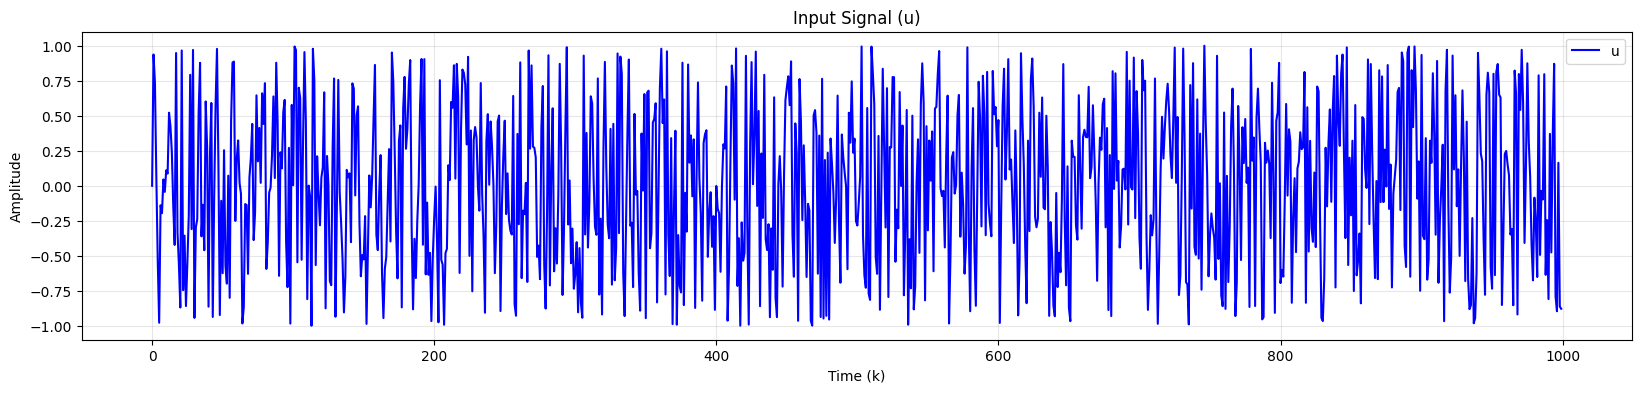

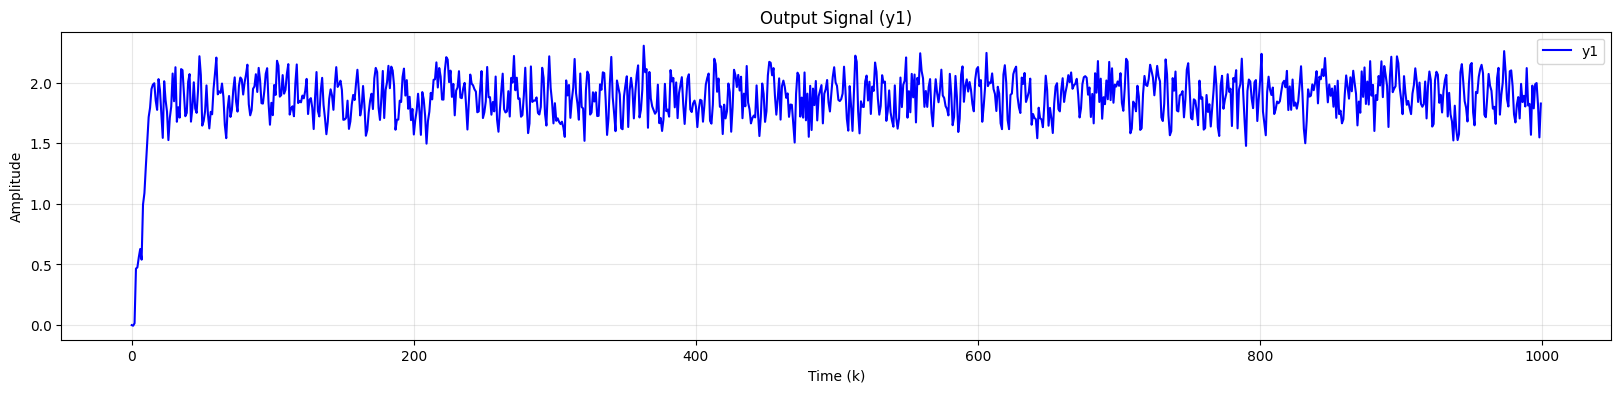

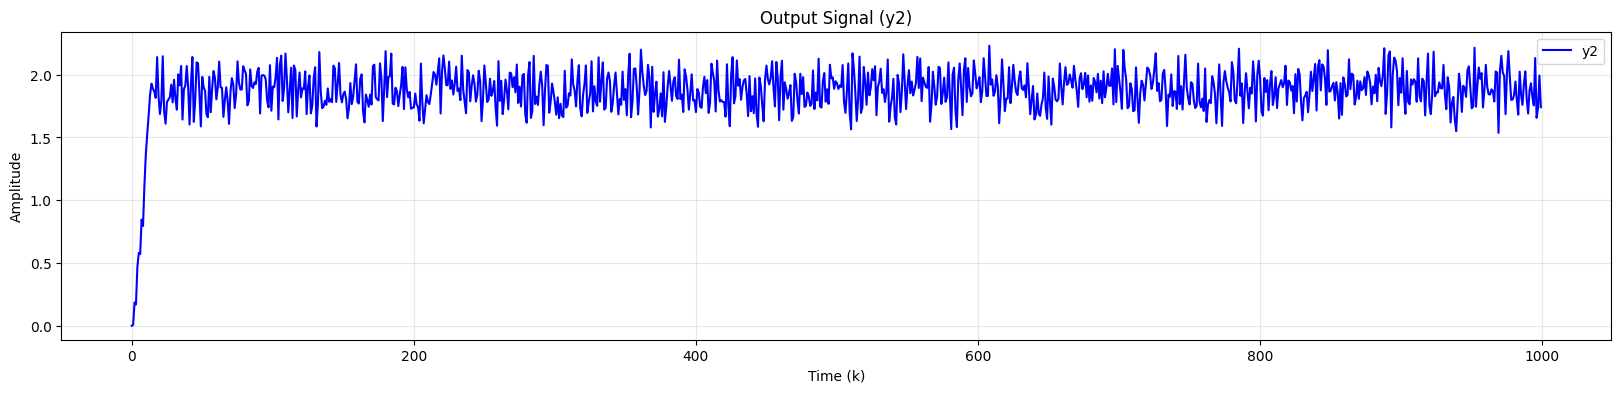

In [8]:
narx1_data = np.random.uniform(-1,1,N_narx1) # Generate N_narx1 random values uniformly distributed between -1 and 1

narx1_u = narx1_data.reshape(-1, 1) # Reshape 
narx1_u[0] = 0.0  # condition u(0) = 0 

narx1_y = NARX1(narx1_u, sigma) # Generate the output data using the NARX1 function

narx1_u_tr , narx1_u_ts = narx1_u[:split1], narx1_u[split1:] # We split the input data into training and testing sets
narx1_y_tr, narx1_y_ts = narx1_y[:split1], narx1_y[split1:]  # We split the output data into training and testing sets

plot_1(narx1_u, title="Input Signal (u)", label="u")
plot_1(narx1_y[:,0], title="Output Signal (y1)", label="y1")
plot_1(narx1_y[:,1], title="Output Signal (y2)", label="y2")

### NARX2: System with Two Inputs and Two Outputs
$$y_1(k+1) = \frac{y_1(k)\,y_1(k-1)\,y_1(k-2)\,(y_1(k-2)-1)\,u_2(k-1) + u_2(k)}{1 + y_2(k-1)^2 + y_2(k-2)^2} + w_1$$

$$y_2(k+1) = \frac{y_2(k)\,y_2(k-1)\,y_2(k-2)\,(y_2(k-2)-1)\,u_1(k-1) + u_1(k)}{1 + y_1(k-1)^2 + y_1(k-2)^2} + w_2$$

During simulation, the outputs are constrained to the interval [-5, 5] to prevent numerical instability when the denominator approaches small values.

In [9]:
def NARX2 (u1, u2, sigma = 0.01): ## two inputs = u1 and u2, two oputs = y1 and y2
    
    ## Starting variables 
    N = len(u1)
    w1 = np.random.normal(0, sigma, N)
    w2 = np.random.normal(0, sigma, N)
    y1,y2 = np.zeros(N) , np.zeros(N)

    ## NARX2 has a tendency to explode... there is something that can control this explosition 
    # np.clip function that can be used to limit the values of y1 and y2 to a certain range. 
    CLIP = 5.0 # This is a conservative clip to keep the simulation bounded. It can be adjusted based on the expected range of the outputs.

    def yy(arr, idx):
        return arr[idx] if idx >= 0 else 0.0

    def uu(arr, idx):
        return arr[idx] if idx >= 0 else 0.0

    for k in range(N - 1):
        y1_0, y1_1, y1_2 = yy(y1, k), yy(y1, k - 1), yy(y1, k - 2)
        y2_0, y2_1, y2_2 = yy(y2, k), yy(y2, k - 1), yy(y2, k - 2)

        num1 = y1_0 * y1_1 * y1_2 * (y1_2 - 1) * uu(u2, k - 1) + uu(u2, k)
        num2 = y2_0 * y2_1 * y2_2 * (y2_2 - 1) * uu(u1, k - 1) + uu(u1, k)

        den1 = 1.0 + y2_1 ** 2 + y2_2 ** 2
        den2 = 1.0 + y1_1 ** 2 + y1_2 ** 2

        y1[k + 1] = np.clip(num1 / den1 + w1[k + 1], -CLIP, CLIP)
        y2[k + 1] = np.clip(num2 / den2 + w2[k + 1], -CLIP, CLIP)
       

    return y1,y2
    # Return of this function
    # is a tuple of two 1D arrays (y1, y2) each of shape (N,)

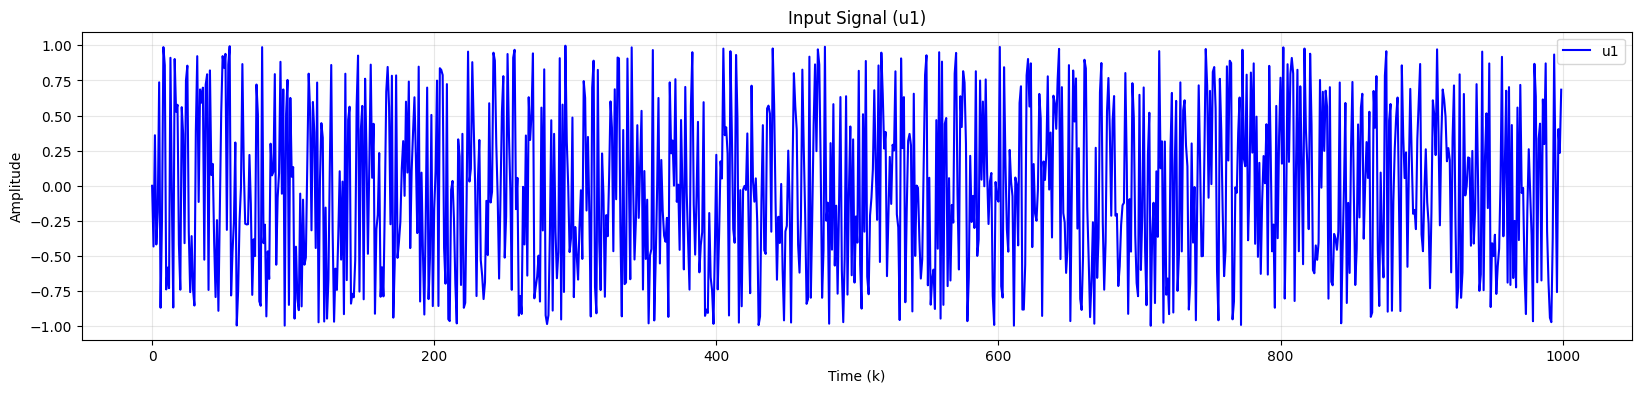

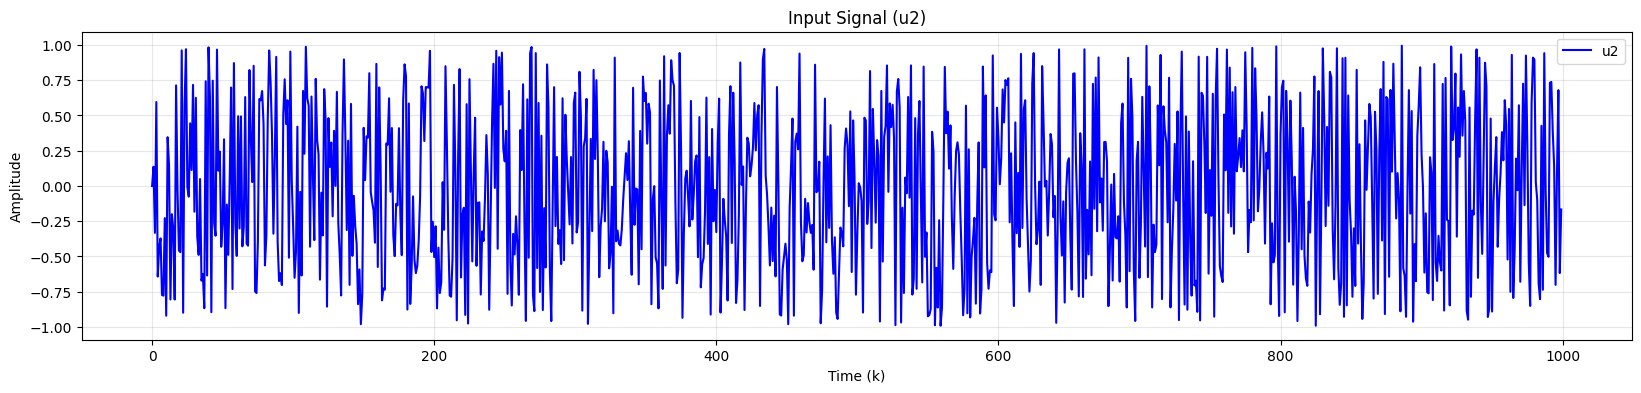

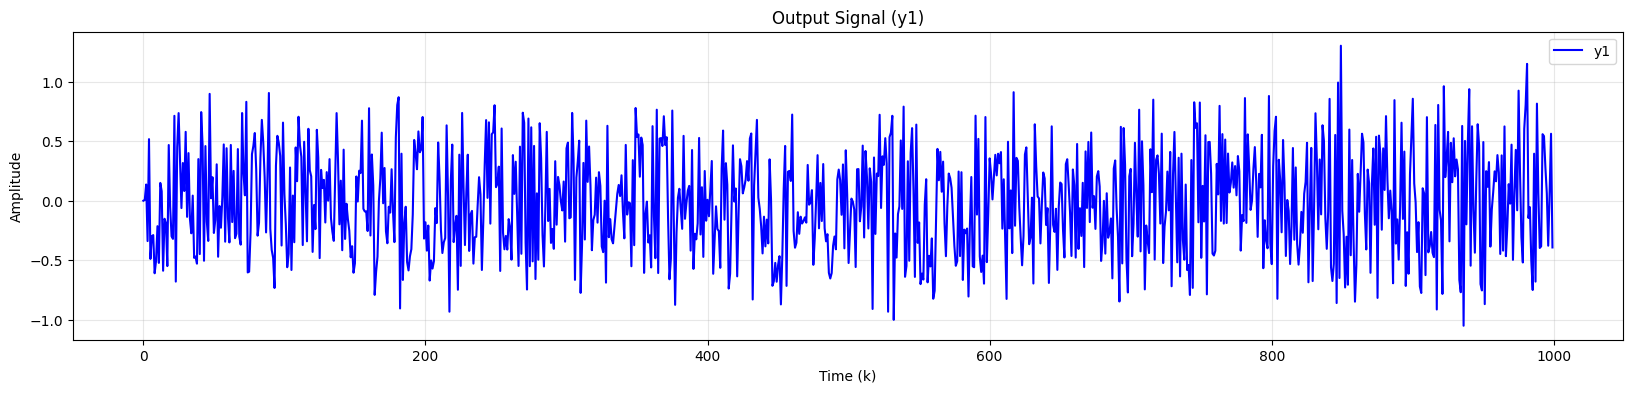

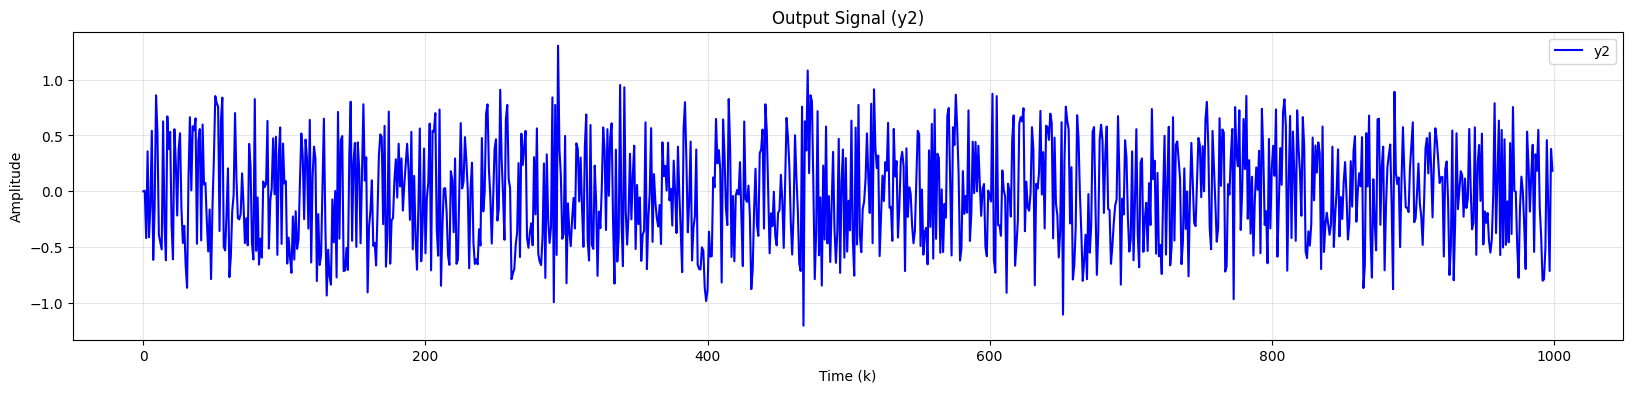

In [10]:
narx2_u1_data = np.random.uniform(-1.0, 1.0, N_narx2) # Generate N_narx2 random values uniformly distributed between -1 and 1 for u1
narx2_u2_data = np.random.uniform(-1.0, 1.0, N_narx2) # Generate N_narx2 random values uniformly distributed between -1 and 1 for u2
narx2_u1_data[0] = 0.0 # condition u1(0) = 0
narx2_u2_data[0] = 0.0 # condition u2(0) = 0
narx2_U = np.column_stack([narx2_u1_data, narx2_u2_data])   # shape (N, 2)
y1 ,y2 = NARX2(narx2_U[:,0], narx2_U[:,1], sigma)
narx2_Y = np.column_stack([y1, y2])                          # shape (N, 2)

narx2_U_tr, narx2_U_ts = narx2_U[:split2], narx2_U[split2:] # We split the input data into training and testing sets
narx2_y_tr, narx2_y_ts = narx2_Y[:split2], narx2_Y[split2:] # We split the output data into training and testing sets

plot_1(narx2_U[:, 0], title="Input Signal (u1)", label="u1")
plot_1(narx2_U[:, 1], title="Input Signal (u2)", label="u2")
plot_1(narx2_Y[:, 0], title="Output Signal (y1)", label="y1")
plot_1(narx2_Y[:, 1], title="Output Signal (y2)", label="y2")

## Task 2. Machine Learning Strategy

The primary challenge in this project was to develop a solution that addresses the NARX (Nonlinear AutoRegressive with eXogenous inputs) characteristics of the problem, as well as the complexity introduced by a long-term forecast horizon exceeding 1000 points. This extended horizon necessitates careful management of error accumulation.

To address these challenges, the team decomposed the problem into two sub-problems and developed targeted solutions for each.

**The Multiple-Input Multiple-Output (MIMO) aspect of the problem**
Two primary modeling options were considered:

1. Developing **two independent models**, with each model dedicated to predicting a single output channel.
2. Implementing a direct **multiple-output approach**, in which a single model simultaneously predicts both output channels.

The second option was selected because the outputs are dynamically coupled; constructing independent models would neglect the cross-channel dependencies that are intrinsic to the system's evolution.

### The challenge of 1000-step long-horizon forecasting
For long-horizon prediction, four distinct strategies were evaluated:

1. **Direct one-step (recursive)**
    This approach outputs $$\hat{y}(k+1)$$, predicting one step at a time and requiring 1000 recursive iterations. Notably, error accumulates at each step. Additionally, this method necessitates separate models for $y_1$ and $y_2$, which is inconsistent with the previously selected MIMO strategy. Therefore, this approach was discarded.
    
2. **Direct multi-output**
    This strategy outputs $$\hat{y}(k+h)$$ for a fixed $h$, resulting in $H$ independent models, one for each forecast horizon. While this approach eliminates drift, it incurs an $H$-fold increase in training cost and prevents structural sharing across horizons. Furthermore, each $h$-cut loses signal due to the dependency in the underlying time series, as each segment discards the dynamics between consecutive horizons. Although this method may be viable for smaller horizons, it is impractical for $H=1000$. Consequently, this approach was discarded.
    
3. **MIMO (recursive, vector output)**
    This method outputs $$[\hat{y}_1(k+1),\hat{y}_2(k+1)]$$ from a shared lag regressor and requires 1000 recursive steps. Although it exhibits the same drift behavior as the direct one-step approach, both channels benefit from shared information via the common feature vector. Despite the high rollout cost, the cost-benefit trade-off was deemed acceptable for the structure of this project.
    
4. **MISMO (block of $s$ steps)**
    This approach outputs $$[\hat{y}(k+1),…,\hat{y}(k+s)]$$ using $$U(k+1:k+s)$$ as input features. The rollout cost is determined by $s$, resulting in $1000/s$ blocks. Drift reduction is also governed by $s$, with the trade-off that each block must predict $s$ steps simultaneously. The implementation follows the MISMO decomposition proposed by Ben Taieb et al. [1], adapted for the NARX context. The feature vector is extended with the known future inputs $U(k+1:k+s)$ provided by the project, and the output block is reshaped to $(s,2)$ to accommodate the two coupled output channels.
    

**Decision: Evaluate both MIMO and MISMO strategies**
Both strategies were implemented and compared. The direct one-step approach (equivalent to the $s=1$ case of MISMO) and the direct multi-output approach (which disregards shared dynamics between consecutive horizons and is computationally infeasible for $H=1000$) were discarded.

- **Rationale for MIMO: Both** outputs are predicted from the same lagged feature vector using two Ridge regression heads, with predictions recursively fed back one step at a time. This approach is straightforward, computationally efficient, and provides a clear assessment of the impact of recursive drift in this context.

- **Rationale for MISMO: The project provides the complete** test input sequence $U_{ts}$ in advance, allowing future inputs $U(k+1),…,U(k+s)$ to be incorporated as features. MISMO leverages this by predicting a block of $s$ steps simultaneously, thereby reducing the number of recursive transitions from $1000$ to $1000/s$. This approach is expected to mitigate long-horizon error accumulation.

- **Both strategies were pursued to empirically compare their performance.** 
Each strategy presents distinct trade-offs: MIMO involves lower-dimensional targets and more training iterations, whereas MISMO employs higher-dimensional targets but requires fewer iterations. The value of this trade-off is ultimately an empirical question and depends on the characteristics of the target system. The objective is to determine which approach is more effective for this specific problem.

Both strategies are evaluated on the two pilot systems (NARX1 and NARX2) prior to application on the unknown system.

#### MIMO Strategy: Recursive Vector OutputMIMO Stategy. Recursive Vector Output

This section outlines the principal functions required for the MIMO strategy.
These include the function to construct the feature matrix and target matrix for the MIMO NARX model.
Additionally, a function is provided to train the MIMO NARX model using Ridge regression with cross-validation to select the optimal regularization parameter alpha.
A function for performing recursive multi-step prediction using the trained MIMO NARX model is also included.


In [ ]:
def build_mimo_features(u, y, d, na, nb):
    # This function builds the feature matrix X and target matrix T for the MIMO NARX model.
        # u: Input data array of shape (N, n_in)
        # y: Output data array of shape (N, n_out)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # nb: Number of input lags to include (total lags = nb)

    u = np.asarray(u, dtype=float)
    y = np.asarray(y, dtype=float)

    horizon = max(d + na, nb)
    rows = []
    targets = []

    for k in range(horizon, len(y) - 1): 
        feats = []
        # Building features for the current time step k ------ 
        for lag in range(d, d + na + 1):
            feats.extend(y[k - lag].tolist())

        # Building features for the input lags -------
        for lag in range(0, nb + 1):
            feats.extend(u[k - lag].tolist())
    
        rows.append(feats)
        
        # Building targets for the next time step k+1 ------
        targets.append(y[k + 1])

    if not rows:
        return np.empty((0, 0)), np.empty((0, y.shape[1]))

    return np.asarray(rows), np.asarray(targets)
    # The return of this function is:
    # X: A 2D array of shape (N_samples, n_features) containing the features for each time step k
    # T: A 2D array of shape (N_samples, n_out) containing the target outputs for time step k+1

In [12]:
def train_mimo(X_train, Y_train, alpha=1.0):
    # This function trains two separate Ridge regression models for the two output variables in a MIMO NARX setup.
        # X_train: A 2D array of shape (N_samples, n_features)
        # Y_train: A 2D array of shape (N_samples, 2) containing the target outputs for each time step k
        # alpha: Regularization strength for Ridge regression

    model_y1 = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model_y2 = make_pipeline(StandardScaler(), Ridge(alpha=alpha))

    model_y1.fit(X_train, Y_train[:, 0])
    model_y2.fit(X_train, Y_train[:, 1])
    
    return model_y1, model_y2
    # The return of this function is:
    # model_y1: A trained Ridge regression model for predicting the first output variable (y1)
    # model_y2: A trained Ridge regression model for predicting the second output variable (y2)

In [13]:
def recursive_rollout_mimo(U, model_y1, model_y2, d, na, nb, y_prefix=None):
    # This function performs a recursive rollout to predict the output sequence Y_hat based on the input sequence U and the trained models for y1 and y2.
        # U: Input data array of shape (N, n_in)
        # model_y1: Trained regression model for predicting y1
        # model_y2: Trained regression model for predicting y2
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # nb: Number of input lags to include (total lags = nb)
        # y_prefix: Optional array of shape (prefix_len, n_out) containing known output values for the initial time steps (if available)

    U = np.asarray(U, dtype=float)
    n_steps, n_inputs = U.shape
    Y_hat = np.zeros((n_steps, 2), dtype=float)

    start = 0
    if y_prefix is not None and len(y_prefix) > 0: # If there ir a y_prefix we used to initialize the first few values of Y_hat with the known output values
        prefix_len = min(len(y_prefix), n_steps)
        Y_hat[:prefix_len] = y_prefix[:prefix_len]
        start = prefix_len

    for k in range(start, n_steps):
        feats = []

        for lag in range(d, d + na + 1): 
            idx = (k - 1) - lag
            feats.extend(Y_hat[idx].tolist() if idx >= 0 else [0.0, 0.0])

        for lag in range(0, nb + 1):
            idx = (k - 1) - lag
            feats.extend(U[idx].tolist() if idx >= 0 else [0.0] * n_inputs)

        xk = np.asarray(feats, dtype=float).reshape(1, -1)
        Y_hat[k, 0] = model_y1.predict(xk)[0] # We predict y1 for the current time step k using model_y1 and the feature vector xk
        Y_hat[k, 1] = model_y2.predict(xk)[0] # We predict y2 for the current time step k using model_y2 and the feature vector xk

    return Y_hat
    # The return of this function is:
    # Y_hat: A 2D array of shape (N_ts, n_out) containing the predicted output values for the test input data.

In [14]:
def build_masks(n_samples, horizon, val_ratio=0.30):
    # This function builds boolean masks for training and validation sets based on the total number of samples, 
    # the horizon (minimum lag), and the validation ratio.
        # n_samples: Total number of samples in the dataset
        # horizon: The minimum lag (d + na or nb) that determines the valid time steps for training and validation
        # val_ratio: The proportion of the dataset to be used for validation
        
    split_idx  = int(n_samples * (1.0 - val_ratio))
    target_idx = np.arange(horizon + 1, n_samples)
    train_mask = target_idx < split_idx
    val_mask   = ~train_mask
    return split_idx, target_idx, train_mask, val_mask
    # This function returns:
    # split_idx: The index at which the data is split into training and validation sets
    # target_idx: An array of indices corresponding to the valid time steps for training and validation
    # train_mask: A boolean array where True indicates the indices used for training
    # val_mask: A boolean array where True indicates the indices used for validation

#### MISMO Strategy: Block Prediction of `s` Steps
To apply this strategy, two vectors are required:

1.**The Feature Vector** 
During the training phase, and for any base index `k`, the following applies:
$$X(k) = [Y(k-d-na),...,Y(k-d)]\;||\;[U(k+1),...,U(k+s)]$$

Here, the first segment represents the output lag history (an $n_a+1$ dimensional vector), while the second segment corresponds to the future input (an $s$ dimensional vector).

2.**Target vector**
This vector contains the next `s` output values.
$$T(k) = [Y(k+1), Y(k+2),...,Y(k+s)]$$

Implementation of this strategy requires three functions.
1. build_mismo_features: pairs the feature and target rows.
2. train_mismo: fits a model using the scikit-learn library.
3. mismo_rollout: manages the sequential block predictions to generate the complete prediction vector, denoted as $\hat{y}$.

In [15]:
def build_mismo_features(U, Y, d, na, s, show=False):
    # This function builds the feature matrix X and target matrix T for the MISMO NARX model.
        # U: Input data array of shape (N, n_in)
        # Y: Output data array of shape (N, n_out)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # s: Number of future steps to predict (target horizon)
        # show: Boolean flag to display the feature building process
    U, Y = np.asarray(U, float), np.asarray(Y, float)
    N, n_in= U.shape
    
    X_rows, T_rows = [], []
    
    for k in range(d + na, N - s):
        ## Building the features ---------
        if(show):
            print(f"\n--Building features for row {k}--")
        feat = [] 
        for lag in range(d, d + na + 1): # loop from d to d+na (inclusive) to get the lags for the output features
            feat.extend(Y[k - lag])
            if(show):
                print(f"    - Adding Y(k-{lag}) to features: {Y[k - lag]}")

        for h in range(1, s + 1): # loop from 1 to s (inclusive) to get the future steps for the input features
            feat.extend(U[k + h])
            if(show):
                print(f"    - Adding U(k+{h}) to features: {U[k + h]}")
        X_rows.append(feat)
        if(show):
            print(f"  Built features for row {k}: {feat}")
        tgt = []

        ## Building the target ---------
        for h in range(1, s + 1): # loop from 1 to s (inclusive) to get the future steps for the target outputs
            tgt.extend(Y[k + h])
            if(show):
                print(f"    - Adding Y(k+{h}) to target: {Y[k + h]}")
        T_rows.append(tgt)

    return np.array(X_rows), np.array(T_rows)
    # The return of this function is:
    # X: A 2D array of shape (N_samples, n_features) containing the features for each time step k
    # T: A 2D array of shape (N_samples, n_out * s) containing the target outputs for time steps k+1 to k+s

In [16]:
def train_mismo(U_tr, Y_tr, d, na, s, model = None,show=False):
    # This function trains a MISMO NARX model using the provided training data and parameters.
        # U_tr: Training input data array of shape (N_tr, n_in)
        # Y_tr: Training output data array of shape (N_tr, n_out)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # s: Number of future steps to predict (target horizon)
        # model: Optional regression model to use (default is RidgeCV with specified alphas)
    if show:
         print(f"\n - Training MISMO with d={d}, na={na}, s={s}...")
         print("   Building features...")

    X, T = build_mismo_features(U_tr, Y_tr, d, na, s, show=show) # Build the feature matrix X and the target matrix T

    if model is None:
        model = RidgeCV(alphas=ALPHAS) 

    pipeline = make_pipeline(StandardScaler(), model) # Create a pipeline that standardizes the features and then applies the regression model
    pipeline.fit(X, T)

    return pipeline
    # The return of this functions is:
    # A trained regression model (pipeline) that can be used to make predictions on new data.

In [17]:
def mismo_rollout(model, U_test, d, na, s, y_prefix=None):
    # This function performs a rollout using the trained MISMO NARX model to predict future outputs based on the test input data.
        # model: Trained regression model (pipeline) to use for predictions
        # U_test: Test input data array of shape (N_ts, n_in)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # s: Number of future steps to predict (target horizon)
        # y_prefix: Optional array of initial output values to seed the rollout
    Nts = len(U_test) 
    n_in = U_test.shape[1] # Number of input features NARX1= 1 NARX2= 2 
    Y_hat = np.zeros((Nts, 2)) # y hat array

    buf_len = d + na + 1
    buf = np.zeros((buf_len, 2))
    
    if y_prefix is not None: # If a prefix of output values is provided, we use it to initialize the buffer for the rollout
        take = min(buf_len, len(y_prefix))
        buf[-take:] = y_prefix[-take:]

    k = 0
    while k < Nts: # We predict the block of future outputs in steps of size s until we have predicted for all test samples
        block = min(s, Nts - k)

        feat = []
        for lag in range(d, d + na + 1): # loop from d to d+na (inclusive) to get the lags for the output features
            feat.extend(buf[buf_len - 1 - lag]) # We take the lagged output features from the buffer

        for h in range(1, s + 1): # loop from 1 to s (inclusive) to get the future steps for the input features
            ui = k + h - 1
            feat.extend(U_test[ui] if ui < Nts else np.zeros(n_in))

        pred_flat = model.predict(np.array(feat, float).reshape(1, -1))[0] 
        pred_block = pred_flat.reshape(s, 2) 

        Y_hat[k:k + block] = pred_block[:block]

        for step in range(block): # After predicting the block of future outputs, we need to update the buffer with the new predictions for the next iteration
            buf = np.roll(buf, -1, axis=0)
            buf[-1] = Y_hat[k + step]

        k += block

    return Y_hat
    # The return of this function is:
    # Y_hat: A 2D array of shape (N_ts, n_out) containing the predicted output values for the test input data.

### Parameter Selection
finding $d$, $n_a$ and $n_b$ or $s$
The MIMO and MISMO models contain three structural hyperparameters, which are selected in a two-stage process:

1. Cross-correlation analysis for $d$
The input-output cross-correlation $r_{uy}( au)$ is computed at lags $ au = 0, ..., maxLag$, and the initial peaks are identified. For systems with a delay $d$, the strongest correlation between $u(k- au)$ and $y(k)$ is expected at $ au = d$. A set of $d$ candidates (top three) is retained for further analysis.

2. Grid search over ($d$, $n_a$, $n_b$ or $s$)
We iterate over ' d ' using the candidates from the previous step. $n_a$ over $[0,...,10]$ and $s$ over $[1,5,10,20,50,100,200]$ For each combination, we trina the model on the training set and evaluate it using **rollout NMSE** on the held-out validation set.

#### Estimation of $d$ using cross-correlation
For each input $u_j$, the cross-correlation between $u_j$ and each output $y_i$ is calculated over lags $0, ..., maxLags$. The results are averaged across all input-output pairs, and the lags corresponding to maximum correlation values are identified. The candidate set is formed by taking the union of the $N$ highest peaks from all pairs, subject to a maximum limit of $max_d$.

In [18]:
def cross_correlation(y, u, max_lag=40):
    # This function computes the cross-correlation between the output signal y and the input signal u for a range of lags from -max_lag to max_lag.
        # y: Output data array of shape (N, n_out)
        # u: Input data array of shape (N, n_in)
        # max_lag: Maximum lag to consider for the cross-correlation

    y_c = y - y.mean()
    u_c = u - u.mean()

    full_corr = np.correlate(y_c, u_c, mode='full') # Compute the full cross-correlation between the centered output and input signals
    N = len(y)
    lags = np.arange(-(N - 1), N)

    norm = np.sqrt(np.sum(y_c**2) * np.sum(u_c**2)) # Compute the normalization factor based on the energy of the centered signals
    full_corr = full_corr / (norm + 1e-12)

    mask = (lags >= -max_lag) & (lags <= max_lag)
    return lags[mask], full_corr[mask]
    # The return of this function is two arrays: 
    # the first contains the lags from -max_lag to max_lag
    # the second contains the corresponding normalized cross-correlation values for those lags.

In [19]:
def estimate_d_candidates(Utr,Ytr,max_lag=40,max_d=10):
    # This functions estimates candidate values for the minimum lag d in the NARX model 
    # by analyzing the cross-correlation between the input and output signals in the training data.
        # Utr: Training input data array of shape (N_tr, n_in)
        # Ytr: Training output data array of shape (N_tr, n_out)
        # max_lag: Maximum lag to consider for the cross-correlation analysis
        # max_d: Maximum candidate value for d to consider based on the cross-correlation peaks

    nu , ny = Utr.shape[1], Ytr.shape[1]
    peak_lags = {}
    
    for i in range(nu): # for each input variable 
        for j in range(ny): # for each output variable
            lags, corr = cross_correlation(Ytr[:, j], Utr[:, i], max_lag=max_lag)
            pos_mask = lags >= 0
            peak_pos = int(lags[pos_mask][np.argmax(np.abs(corr[pos_mask]))]) 
            peak_lags[(i, j)] = peak_pos

    print('\nPositive-lag peaks per (input, output) pair:')
    for (i, j), lag in peak_lags.items(): # Print the identified peak lag for each input-output pair
        print(f'  u{i+1} -> y{j+1}: peak at lag {lag}')

    peak_values = np.array(list(peak_lags.values()),dtype=int)
    d_min = int(np.min(peak_values))
    d_med = int(np.median(peak_values))

    baseline = set(range(0, max_d)) # A baseline set of candidate d values from 0 to 5
    around_med = set(range(max(0, d_med - 2), d_med + 4)) #
    around_min = set(range(max(0, d_min - 1), d_min + 3))

    d_candidates = sorted(d for d in (baseline | around_med | around_min) if 0 <= d <= max_d)
    print(f'\nCCF min peak: {d_min}, median peak: {d_med}')
    print(f'\nWill test d in {d_candidates} during grid search')

    return d_candidates, peak_lags
    # The return of this function is:
    # d_candidates: A sorted list of candidate values for the minimum lag d to consider in the NARX model based on the cross-correlation analysis
    # peak_lags: A dictionary containing the identified peak lags for each input-output pair from the cross-correlation analysis.

##### Results

In [ ]:
print("\n - Estimating d candidates for NARX1 -")
d1, peaks1 = estimate_d_candidates(narx1_u_tr, narx1_y_tr, max_lag=40,max_d=8)

print("\n - Estimating d candidates for NARX2 -")
d2, peaks2 = estimate_d_candidates(narx2_U_tr, narx2_y_tr, max_lag=40,max_d=8)


_______ Estimating d candidates for NARX1...

Positive-lag peaks per (input, output) pair:
  u1 -> y1: peak at lag 2
  u1 -> y2: peak at lag 1

CCF min peak: 1, median peak: 1

Will test d in [0, 1, 2, 3, 4, 5, 6, 7] during grid search

_______ Estimating d candidates for NARX2...

Positive-lag peaks per (input, output) pair:
  u1 -> y1: peak at lag 2
  u1 -> y2: peak at lag 1
  u2 -> y1: peak at lag 1
  u2 -> y2: peak at lag 0

CCF min peak: 0, median peak: 1

Will test d in [0, 1, 2, 3, 4, 5, 6, 7] during grid search


#### Grid Search Across (d, n_a, n_b, or s)

This section employs two grid-search functions corresponding to the two strategies. For the MIMO strategy, the optimal values of d, n_a, and n_b are identified, while for the MISMO strategy, the optimal values of d, n_a, and s are determined. Each parameter combination is used to train a RidgeCV-based MISMO or MIMO model on validation partitions, and the model is then evaluated on those partitions by recording the NMSE. The combination yielding the lowest validation NMSE is selected. It should be noted that the analysis involves |d| × |na| × |nb| combinations for MIMO and |d| × |na| × |s| combinations for MISMO, which may require considerable computational time.
Each result is stored in best_n1 and best_n2 and subsequently reused throughout the notebook.

In [21]:
## MIMO grid NARX1 
MIMO_grid1 = {    
    'd':  d1,         
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'nb': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
}

# MIMO grid NARX2
MIMO_grid2 = {
    'd':  d2,         
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'nb': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
}

# MISMO grid NARX1
grid1_MISMO = {
    'd': d1,
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    's':  [1, 5, 10, 20, 50, 100, 200, 500,1000]
}

# MISMO grid NARX2
grid2_MISMO = {
    'd': d2,
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    's':  [1, 5, 10, 20, 50, 100, 200, 500,1000]
}

In [22]:
def grid_search_mimo(U, Y, grid, val_ratio=0.30, alpha=1.0):
    # This function performs a grid search over the specified hyperparameters for the MIMO NARX model and evaluates the performance on a validation set.
        # U: Input data array of shape (N, n_in)
        # Y: Output data array of shape (N, n_out)
        # grid: A dictionary specifying the hyperparameter values to search over (keys should be 'd', 'na', 'nb')
        # val_ratio: Proportion of the data to use for validation (default is 0.30)
        # alpha: Regularization strength for Ridge regression (default is 1.0)
        
    rows = []

    for params in ParameterGrid(grid):
        d  = int(params['d'])
        na = int(params['na'])
        nb = int(params['nb'])

        X, Y_next = build_mimo_features(U, Y, d=d, na=na, nb=nb)
        if X.size == 0:
            continue

        horizon = max(d + na, nb)
        split_idx, _, train_mask, val_mask = build_masks(len(Y), horizon, val_ratio)

        if train_mask.sum() < 30 or val_mask.sum() < 30:
            continue

        # Train on train portion only
        model_y1, model_y2 = train_mimo(X[train_mask], Y_next[train_mask], alpha)

        Y_val_pred_os = np.column_stack([
            model_y1.predict(X[val_mask]),
            model_y2.predict(X[val_mask]),
        ])
        nmse_os = float(nmse(Y_next[val_mask], Y_val_pred_os))
        rmse_os = float(rmse(Y_next[val_mask], Y_val_pred_os))

        
        Y_roll = recursive_rollout_mimo(
            U, model_y1, model_y2,
            d=d, na=na, nb=nb,
            y_prefix=None,
        )
        Y_val_roll  = Y_roll[split_idx:]
        Y_val_true  = Y[split_idx:]
        nmse_roll = float(nmse(Y_val_true, Y_val_roll))
        rmse_roll = float(rmse(Y_val_true, Y_val_roll))

        rows.append({
            'd': d, 'na': na, 'nb': nb,
            'n_features': int(X.shape[1]),
            'n_train':    int(train_mask.sum()),
            'n_val':      int(val_mask.sum()),
            'nmse_os':    nmse_os,
            'rmse_os':    rmse_os,
            'nmse_roll':  nmse_roll,
            'rmse_roll':  rmse_roll,
        })

    if not rows:
        return {}, pd.DataFrame()

    # Sort by rollout NMSE (the metric the project actually scores on)
    df = pd.DataFrame(rows).sort_values(['nmse_roll', 'nmse_os']).reset_index(drop=True)

    print(f"\n___ Grid (d, na, nb) — sorted by rollout NMSE ___")
    print(df.to_string(index=False))

    best_row = df.iloc[0]
    best_params = {
        'd':  int(best_row['d']),
        'na': int(best_row['na']),
        'nb': int(best_row['nb']),
    }

    print(f"\nBest combination: d={best_params['d']}, "
          f"na={best_params['na']}, nb={best_params['nb']}\n"
          f"  rollout NMSE  = {best_row['nmse_roll']:.4f}\n"
          f"  one-step NMSE = {best_row['nmse_os']:.4f}\n"
          f"  drift ratio   = {best_row['nmse_roll'] / max(best_row['nmse_os'], 1e-12):.1f}x")

    return best_params, df
    # This function returns:
    # best_params: A dictionary containing the best combination of hyperparameters (d, na, nb) based on the validation performance
    # df: A DataFrame containing the results of the grid search for all combinations of hyperparameters, sorted by validation performance.

In [23]:
def grid_search_mismo(U_tr, Y_tr, grid, val_ratio=0.30, label=""):
    # This function performs a grid search over the specified hyperparameters for the MISMO NARX model 
    # and evaluates the performance on the test set.
        # U_tr: Training input data array of shape (N, n_in)
        # Y_tr: Training output data array of shape (N, n_out)
        # U_ts: Test input data array of shape (N, n_in)
        # Y_ts: Test output data array of shape (N, n_out)
        # grid: A dictionary specifying the hyperparameter values to search over (keys should be 'd', 'na', 's')
        # y_prefix: Optional prefix for the output variable names
        # label: Optional label for the grid search (default is "")

    U_tr = np.asarray(U_tr, dtype=float)
    Y_tr = np.asarray(Y_tr, dtype=float)
    N = len(U_tr)
    split = int(N * (1.0 - val_ratio))

    U_sub_tr, U_sub_val = U_tr[:split], U_tr[split:]
    Y_sub_tr, Y_sub_val = Y_tr[:split], Y_tr[split:]

    rows = []

    for params in ParameterGrid(grid):
        d = int(params['d'])
        na = int(params['na'])
        s = int(params['s'])

        if len(U_sub_val) < s or len(U_sub_tr) <= d + na + s:
                    continue
        
        mod = train_mismo(U_sub_tr, Y_sub_tr, d, na, s)  # We train the MISMO model with the current combination of hyperparameters (d, na, s) using the training data (U_sub_tr, Y_sub_tr)
        yhat = mismo_rollout(mod, U_sub_val, d, na, s, y_prefix=None) # We generate predictions for the validation set (U_sub_val) using the trained MISMO model and the current hyperparameters (d, na, s)

        rows.append({
            'd': d,
            'na': na,
            's': s,
            'nmse': nmse(Y_sub_val, yhat),
            'rmse': rmse(Y_sub_val, yhat)
        })
    
    if not rows:
        return {}, pd.DataFrame()
    
    # We create a DataFrame with the results of the grid search and sort it by nmse and rmse to identify the best combination of hyperparameters
    df = pd.DataFrame(rows).sort_values(['nmse','rmse']).reset_index(drop=True)
    
    print(f"\n___ Grid (d, na, s) __ {label} ___")
    print(df.to_string(index=False))

    best_row = df.iloc[0]
    best_params = {
        'd':  int(best_row['d']),
        'na': int(best_row['na']),
        's':  int(best_row['s']),
    }
    print(f"\nBest Combination: d={best_params['d']}, "
          f"na={best_params['na']}, s={best_params['s']}  "
          f"(nmse={best_row['nmse']})")

    return best_params, df
    # This function returns:
    # best_params: A dictionary containing the best combination of hyperparameters (d, na, s) based on the test performance
    # df: A DataFrame containing the results of the grid search for all combinations of hyperparameters, sorted by test performance.

##### Results MIMO

In [24]:
print("Best Parameters for NARX1 MIMO:")
best_n1_mimo, df_n1_mimo = grid_search_mimo(narx1_u, narx1_y, MIMO_grid1)

Best Parameters for NARX1 MIMO:



___ Grid (d, na, nb) — sorted by rollout NMSE ___
 d  na  nb  n_features  n_train  n_val  nmse_os  rmse_os    nmse_roll    rmse_roll
 1   2   6          13      693    300 0.013210 0.017584 1.995003e-02 2.160940e-02
 0   2   6          13      693    300 0.014552 0.018456 1.998869e-02 2.163033e-02
 0   3   6          15      693    300 0.014030 0.018122 2.000383e-02 2.163852e-02
 0   2   8          15      691    300 0.013287 0.017635 2.007683e-02 2.167796e-02
 1   2   5          12      694    300 0.013205 0.017581 2.011782e-02 2.170008e-02
 0   2   5          12      694    300 0.014606 0.018490 2.012650e-02 2.170476e-02
 1   1   8          13      691    300 0.013089 0.017504 2.012905e-02 2.170614e-02
 0   2   9          16      690    300 0.012543 0.017135 2.014801e-02 2.171636e-02
 1   1   9          14      690    300 0.013032 0.017466 2.019585e-02 2.174212e-02
 0   2   7          14      692    300 0.014304 0.018298 2.023565e-02 2.176354e-02
 1   3   3          12      695    3

In [25]:
print("Best Parameters for NARX2 MIMO:")
best_n2_mimo, df_n2_mimo = grid_search_mimo(narx2_U, narx2_Y, MIMO_grid2)

Best Parameters for NARX2 MIMO:

___ Grid (d, na, nb) — sorted by rollout NMSE ___
 d  na  nb  n_features  n_train  n_val  nmse_os  rmse_os  nmse_roll  rmse_roll
 1   0   0           4      698    300 0.062588 0.113925   0.063021   0.114319
 1   1   0           6      697    300 0.062596 0.113933   0.063182   0.114465
 1   2   0           8      696    300 0.062826 0.114142   0.063399   0.114662
 1   4   0          12      694    300 0.062932 0.114238   0.063403   0.114665
 1   3   0          10      695    300 0.062898 0.114207   0.063420   0.114680
 1   0   1           6      698    300 0.063206 0.114487   0.063654   0.114891
 0   2   3          14      696    300 0.062894 0.114204   0.063664   0.114901
 0   1   1           8      698    300 0.063547 0.114795   0.063679   0.114914
 0   0   2           8      697    300 0.064020 0.115222   0.063688   0.114923
 1   1   3          12      696    300 0.062544 0.113886   0.063695   0.114929
 5   0   2           8      694    300 0.063749 

##### Results MISMO

In [26]:
## This code take some time to run, be patient.
print("Best Parameters for NARX1 MISMO:")
best_n1_mismo, df_n1_mismo = grid_search_mismo(narx1_u_tr, narx1_y_tr,grid1_MISMO, label="NARX1")

Best Parameters for NARX1 MISMO:

___ Grid (d, na, s) __ NARX1 ___
 d  na   s          nmse      rmse
 7   3 100      0.055608  0.034438
 7   2 100      0.055640  0.034448
 3   8 100      0.056554  0.034730
 3   7 100      0.056567  0.034734
 7   4 100      0.058488  0.035319
 3   9 100      0.060697  0.035980
 7   5 100      0.061273  0.036150
 3   6 100      0.064797  0.037175
 7   8 100      0.064904  0.037206
 7   6 100      0.064939  0.037215
 7   1 100      0.064979  0.037227
 4   6 100      0.065539  0.037387
 5   5 100      0.066122  0.037553
 3   8  50      0.066304  0.037605
 7   7 100      0.066319  0.037609
 7   9 100      0.066645  0.037701
 6   3 100      0.066798  0.037745
 5   4 100      0.066920  0.037779
 3  10 100      0.067880  0.038049
 4   7 100      0.068071  0.038102
 3   7  50      0.068097  0.038110
 5   6 100      0.070199  0.038693
 7  10 100      0.070385  0.038745
 6   4 100      0.070757  0.038847
 3   9  50      0.070768  0.038850
 6   2 100      0.07289

In [27]:
## This code take some time to run, be patient.
print("Best Parameters for NARX2 MISMO:")
best_n2_mismo, df_n2_mismo = grid_search_mismo(narx2_U_tr, narx2_y_tr,grid2_MISMO, label="NARX2")

Best Parameters for NARX2 MISMO:

___ Grid (d, na, s) __ NARX2 ___
 d  na   s     nmse     rmse
 1   5  20 0.092806 0.132932
 0   1  50 0.093412 0.133366
 0   6  20 0.093448 0.133391
 1   4  20 0.093626 0.133518
 3   3  20 0.093726 0.133590
 1   3  20 0.093775 0.133625
 2   4  20 0.094176 0.133910
 0   5  20 0.094236 0.133952
 0   0  50 0.094249 0.133962
 0   4  20 0.094271 0.133978
 3   0  20 0.094291 0.133992
 3   2  20 0.094382 0.134056
 5   0  20 0.094414 0.134079
 1   2  20 0.094507 0.134145
 3   1  20 0.094559 0.134182
 5   1  20 0.094670 0.134260
 2   3  20 0.094864 0.134398
 1   0  50 0.094880 0.134410
 4   2  20 0.094887 0.134414
 2   2  20 0.094986 0.134484
 6   0  20 0.095025 0.134512
 1   0  20 0.095077 0.134549
 0   3  20 0.095125 0.134583
 4   1  20 0.095670 0.134968
 4   0  20 0.095674 0.134971
 2   1  20 0.095801 0.135060
 1   1  20 0.095803 0.135062
 0   2  50 0.096128 0.135291
 2   0  20 0.096137 0.135297
 0   1  20 0.096376 0.135465
 0   2  20 0.096411 0.135490
 0   

### End-to-end test on Pilots
Once the parameters for both strategies have been selected, we train the models on the training sets and evaluate them on the test sets. This is the final check before moving on to the model comparison; here, we would make an initial assessment of the effectiveness of the previous strategies.

#### MIMO Results
##### NARX 1


NARX 1 | MIMO | One-step ahead validation NMSE: 0.0132, RMSE: 0.0176


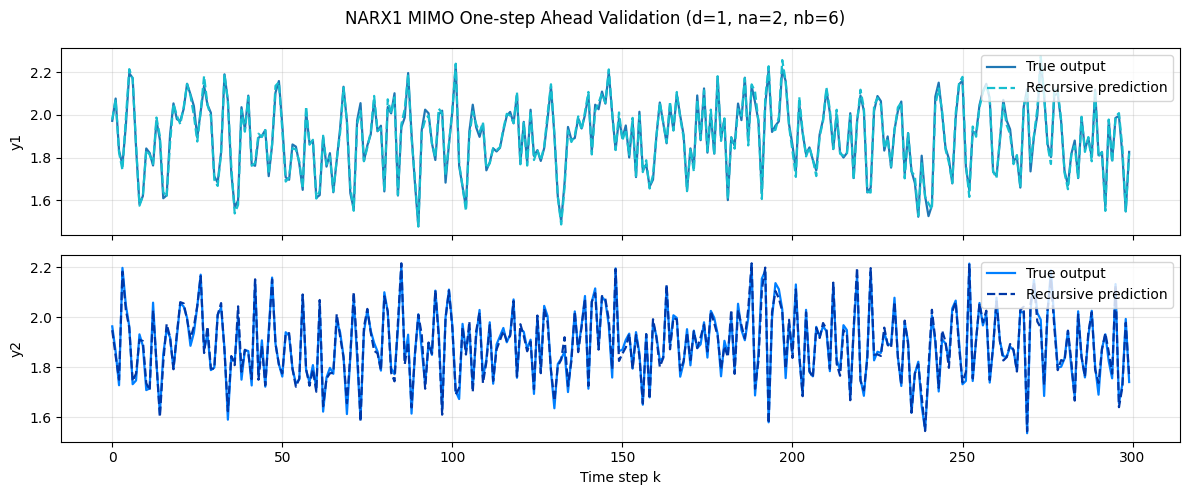

In [ ]:
horizon_narx1 = max(best_n1_mimo['d'] + best_n1_mimo['na'], best_n1_mimo['nb']) 
# We calculate the horizon for NARX1 based on the best hyperparameters found in the grid search for the MIMO model. 
#The horizon is determined by the maximum of (d + na) and nb, which represents the maximum lag used in the features for the MIMO model. 

X_narx1_tr, Y_narx1_tr = build_mimo_features(narx1_u_tr, narx1_y_tr,d=best_n1_mimo['d'], na=best_n1_mimo['na'], nb=best_n1_mimo['nb'])
model_y1, model_y2 = train_mimo(X_narx1_tr, Y_narx1_tr, alpha=1.0)


X_narx1_full, Y_narx1_full_tgt = build_mimo_features(narx1_u, narx1_y, d=best_n1_mimo['d'], na=best_n1_mimo['na'], nb=best_n1_mimo['nb'])
target_k_plus_1    = np.arange(horizon_narx1 + 1, len(narx1_y))
val_mask           = target_k_plus_1 >= split1

Y_val_one_step = np.column_stack([
    model_y1.predict(X_narx1_full[val_mask]),
    model_y2.predict(X_narx1_full[val_mask]),
])
Y_val_true_os = Y_narx1_full_tgt[val_mask] 

nmse_os = nmse(Y_val_true_os, Y_val_one_step)
rmse_os = rmse(Y_val_true_os, Y_val_one_step)
print(f"\nNARX 1 | MIMO | One-step ahead validation NMSE: {nmse_os:.4f}, RMSE: {rmse_os:.4f}")
plot_comparison(Y_val_true_os, Y_val_one_step, title=f"NARX1 MIMO One-step Ahead Validation (d={best_n1_mimo['d']}, na={best_n1_mimo['na']}, nb={best_n1_mimo['nb']})")


NARX 1 | MIMO | Recursive validation NMSE: 0.0190, RMSE: 0.0211


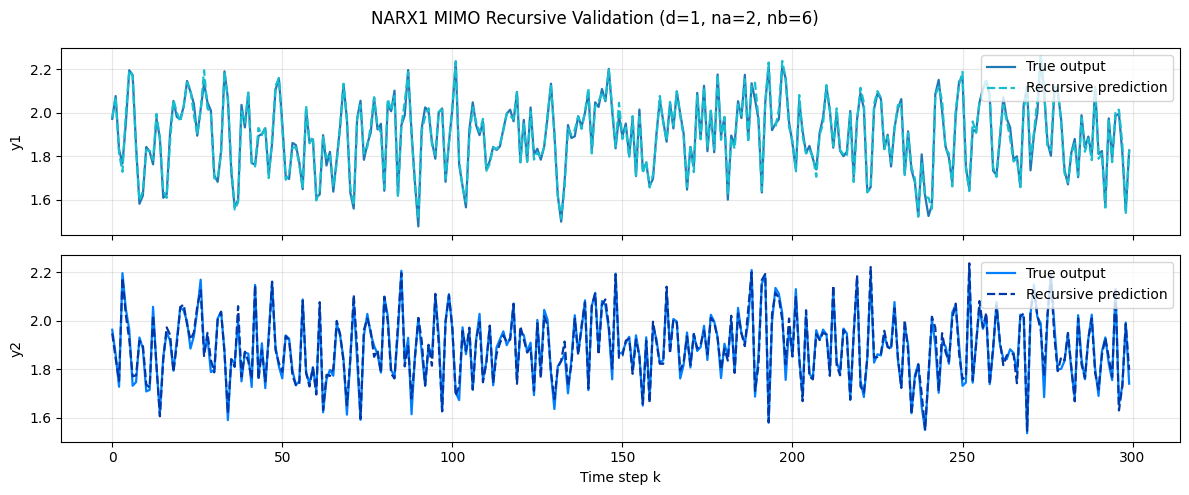

In [ ]:
# Then we perform a recursive rollout using the trained MIMO model to predict the output sequence for the entire dataset 
# and evaluate the performance on the validation set.

Y_roll = recursive_rollout_mimo(narx1_u, model_y1, model_y2,
                                d=best_n1_mimo['d'], na=best_n1_mimo['na'], nb=best_n1_mimo['nb'],
                                y_prefix=narx1_y_tr)

Y_val_rec     = Y_roll[split1:]
Y_val_true_rec = narx1_y[split1:]

nmse_rec = nmse(Y_val_true_rec, Y_val_rec)
rmse_rec = rmse(Y_val_true_rec, Y_val_rec)

print(f"\nNARX 1 | MIMO | Recursive validation NMSE: {nmse_rec:.4f}, RMSE: {rmse_rec:.4f}")
plot_comparison(Y_val_true_rec, Y_val_rec, title=f"NARX1 MIMO Recursive Validation (d={best_n1_mimo['d']}, na={best_n1_mimo['na']}, nb={best_n1_mimo['nb']})")

In [ ]:
# Finally, we create a summary table comparing the one-step ahead and recursive rollout validation metrics for NARX1 using the MIMO model, 
# and we also calculate the ratio of the recursive NMSE to the one-step NMSE to assess the drift in performance when using the model recursively.
metrics_table = pd.DataFrame([
    {'strategy': 'one_step_teacher_forcing', 'NMSE': nmse_os,  'RMSE': rmse_os},
    {'strategy': 'recursive_rollout',        'NMSE': nmse_rec, 'RMSE': rmse_rec},
])
print('\nValidation metrics on the held-out 30% of NARX1:')
print(metrics_table.to_string(index=False))
print(f'\nRecursive vs one-step NMSE ratio: {nmse_rec / max(nmse_os, 1e-12):.2f}')


Validation metrics on the held-out 30% of NARX1:
                strategy     NMSE     RMSE
one_step_teacher_forcing 0.013210 0.017584
       recursive_rollout 0.018963 0.021068

Recursive vs one-step NMSE ratio: 1.44


##### NARX 2
This follows the same methodology as the previous step.


NARX 2 | MIMO | One-step ahead validation NMSE: 0.0626, RMSE: 0.1139


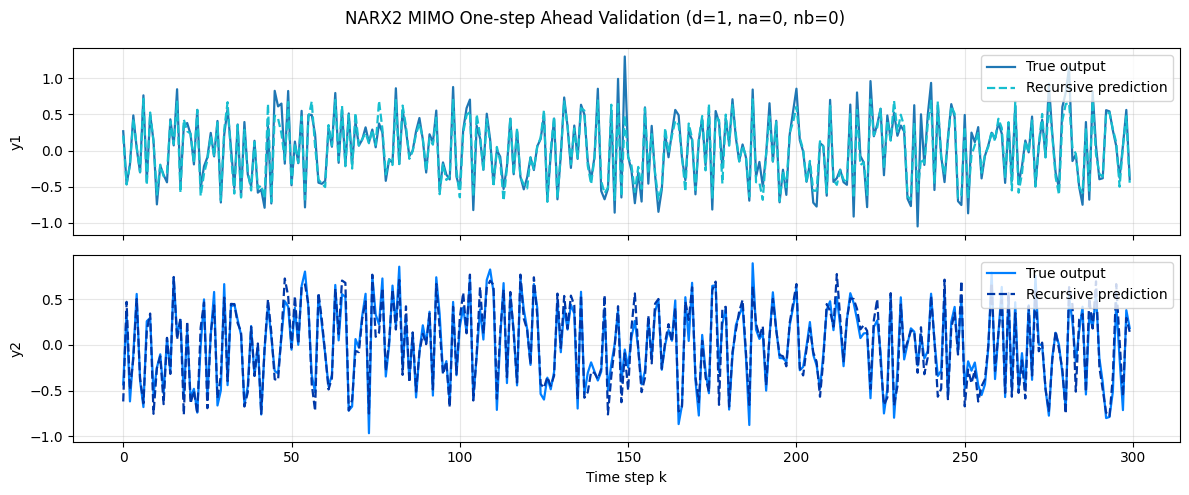

In [ ]:
horizon_narx2 = max(best_n2_mimo['d'] + best_n2_mimo['na'], best_n2_mimo['nb'])
X_n2_tr, Y_n2_tr = build_mimo_features(narx2_U_tr, narx2_y_tr,d=best_n2_mimo['d'], na=best_n2_mimo['na'], nb=best_n2_mimo['nb'])
model_y1, model_y2 = train_mimo(X_n2_tr, Y_n2_tr, alpha=1.0)

X_n2_full, Y_n2_full_tgt = build_mimo_features(narx2_U, narx2_Y, d=best_n2_mimo['d'], na=best_n2_mimo['na'], nb=best_n2_mimo['nb'])
target_k_plus_1    = np.arange(horizon_narx2 + 1, len(narx2_Y))
val_mask           = target_k_plus_1 >= split1

Y_val_one_step = np.column_stack([
    model_y1.predict(X_n2_full[val_mask]),
    model_y2.predict(X_n2_full[val_mask]),
])
Y_val_true_os = Y_n2_full_tgt[val_mask]

nmse_os_narx2 = nmse(Y_val_true_os, Y_val_one_step)
rmse_os_narx2 = rmse(Y_val_true_os, Y_val_one_step)
print(f"\nNARX 2 | MIMO | One-step ahead validation NMSE: {nmse_os_narx2:.4f}, RMSE: {rmse_os_narx2:.4f}")
plot_comparison(Y_val_true_os, Y_val_one_step, title=f"NARX2 MIMO One-step Ahead Validation (d={best_n2_mimo['d']}, na={best_n2_mimo['na']}, nb={best_n2_mimo['nb']})")


NARX 2 | MIMO | Recursive validation NMSE: 0.0630, RMSE: 0.1143


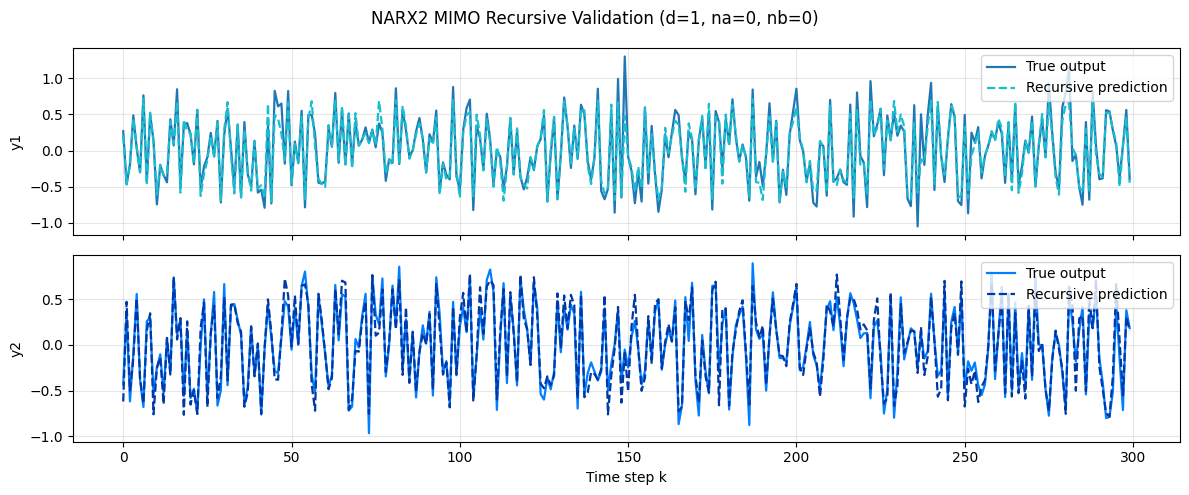

In [32]:
Y_roll = recursive_rollout_mimo(narx2_U, model_y1, model_y2,
                                d=best_n2_mimo['d'], na=best_n2_mimo['na'], nb=best_n2_mimo['nb'],
                                y_prefix=narx2_y_tr)
Y_val_rec     = Y_roll[split1:]
Y_val_true_rec = narx2_Y[split1:]

nmse_rec = nmse(Y_val_true_rec, Y_val_rec)
rmse_rec = rmse(Y_val_true_rec, Y_val_rec)

print(f"\nNARX 2 | MIMO | Recursive validation NMSE: {nmse_rec:.4f}, RMSE: {rmse_rec:.4f}")
plot_comparison(Y_val_true_rec, Y_val_rec, title=f"NARX2 MIMO Recursive Validation (d={best_n2_mimo['d']}, na={best_n2_mimo['na']}, nb={best_n2_mimo['nb']})")

In [33]:
metrics_table = pd.DataFrame([
    {'strategy': 'one_step_teacher_forcing', 'NMSE': nmse_os,  'RMSE': rmse_os},
    {'strategy': 'recursive_rollout',        'NMSE': nmse_rec, 'RMSE': rmse_rec},
])
print('\nValidation metrics on the held-out 30% of NARX1:')
print(metrics_table.to_string(index=False))
print(f'\nRecursive vs one-step NMSE ratio: {nmse_rec / max(nmse_os, 1e-12):.2f}')


Validation metrics on the held-out 30% of NARX1:
                strategy     NMSE     RMSE
one_step_teacher_forcing 0.013210 0.017584
       recursive_rollout 0.063017 0.114315

Recursive vs one-step NMSE ratio: 4.77


The recursive NMSE is higher than the single-step NMSE in both NARX pilots, as expected when feedback is applied to the predictions; as the statement indicates, an error-accumulation pattern is observed. Given that this is a test with 300 values and a 1,000-step rollout starting from zero initial conditions, this effect could be more pronounced. 

#### MISMO Results

NARX 1 | MISMO (s=100) NMSE=0.04957 RMSE=0.03406


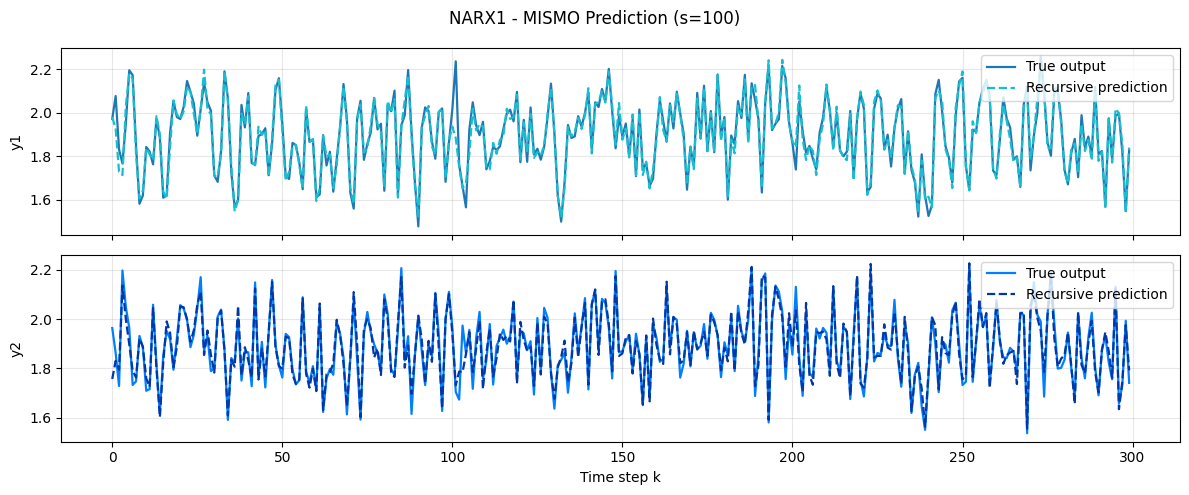

In [34]:
# We train the model with out train data and the best hyperparameters found 
narx1_modelMISMO = train_mismo(narx1_u_tr, narx1_y_tr, best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'])
# We generate the predictions 
narx1_yhat = mismo_rollout(narx1_modelMISMO , narx1_u_ts, best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'], y_prefix=narx1_y_tr)

# This test is based on 70% training data and 30% test data. 
print(f"NARX 1 | MISMO (s={best_n1_mismo['s']}) NMSE={nmse(narx1_y_ts,narx1_yhat):.5f}" f" RMSE={rmse(narx1_y_ts,narx1_yhat):.5f}")
plot_comparison(narx1_y_ts, narx1_yhat, title=f"NARX1 - MISMO Prediction (s={best_n1_mismo['s']})")

NARX 2 | MISMO (s=20) NMSE=0.13072 RMSE=0.16465


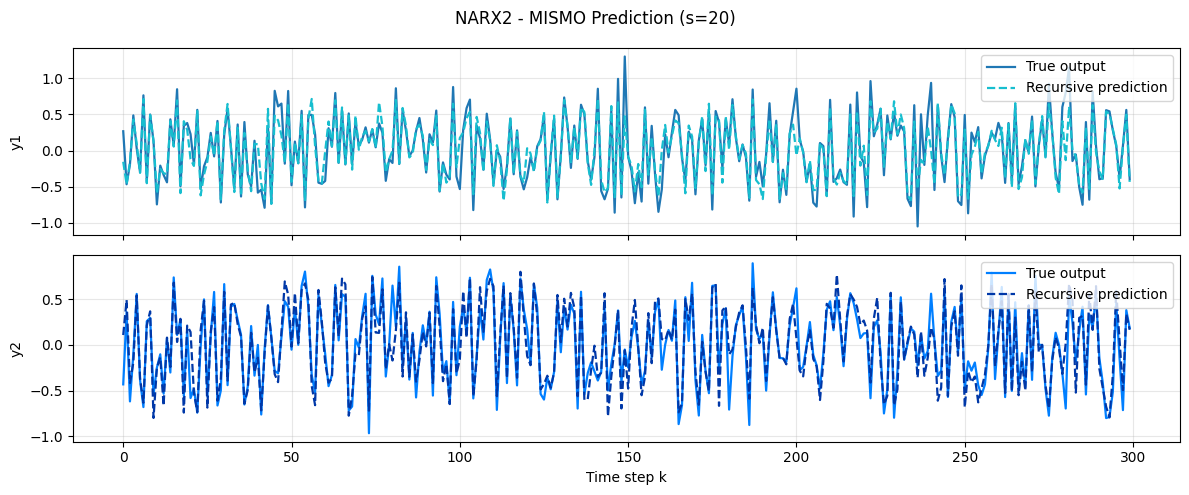

In [35]:
# We train the model with out train data and the best hyperparameters found 
narx2_modelMISMO = train_mismo(narx2_U_tr, narx2_y_tr, best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'])
# We generate the predictions 
narx2_yhat = mismo_rollout(narx2_modelMISMO , narx2_U_ts, best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'], y_prefix=narx2_y_tr)

# This test is based on 70% training data and 30% test data. 
print(f"NARX 2 | MISMO (s={best_n2_mismo['s']}) NMSE={nmse(narx2_y_ts,narx2_yhat):.5f}" f" RMSE={rmse(narx2_y_ts,narx2_yhat):.5f}")
plot_comparison(narx2_y_ts, narx2_yhat, title=f"NARX2 - MISMO Prediction (s={best_n2_mismo['s']})")

## Task 3: Baseline Approach
### MIMO
#### Step 1: Dataframe
Constructing an appropriate dataframe.
Before training non-deep learning models and constructing a scikit-learn pipeline, we must establish an effective data management strategy. The following analysis is based on data generated from the NARX1 simulation, which can be readily extended to data from the NARX2 simulation and the unknown NARX model. To maintain organization, we utilize pandas dataframes. We first create a dataframe from the NARX1 simulation data, employing the data simulation methodology implemented for NARX1. In this step, we aim to obtain:

$$
u_1^{tr}(k),\ u_2^{tr}(k),\ y_1^{tr}(k),\ y_2^{tr}(k) \quad k=1, \dots, N_{tr},
$$

where $N_{tr} = 1000$ corresponds to the size of the training set. Note: Although $u_2(k)$ does not exist for NARX1, we will create a corresponding column filled with zeros to facilitate future methodological extensions.ents.

Subsequently, we construct a dataframe that includes all relevant variables.

In [ ]:
df_narx1 = pd.DataFrame(np.column_stack([narx1_u, narx1_y]), columns=['u1', 'y1', 'y2'])
df_narx1

,u1,y1,y2
0,0.000000,0.000000,0.000000
1,0.937081,-0.004827,0.006866
2,0.738389,0.015423,0.184791
3,0.061711,0.465922,0.169319
4,-0.534543,0.476193,0.468092
...,...,...,...
995,-0.788671,1.986204,2.132248
996,-0.895219,1.995698,1.656086
997,0.164201,1.815982,1.732078
998,-0.861751,1.547685,1.993068


In [37]:
df_narx2 = pd.DataFrame(np.column_stack([narx2_U, narx2_Y]), columns=['u1', 'u2', 'y1', 'y2'])
df_narx2

,u1,u2,y1,y2
0,0.000000,0.000000,0.000000,0.000000
1,-0.432441,0.136205,0.007165,0.004656
2,0.359833,-0.332603,0.135886,-0.419805
3,-0.417661,0.595368,-0.338634,0.358020
4,-0.187984,-0.642446,0.516510,-0.411502
...,...,...,...,...
995,0.107385,-0.701481,0.063033,0.458564
996,-0.757068,0.084161,-0.377481,-0.149618
997,0.403467,0.679819,0.069264,-0.714272
998,0.234074,-0.617597,0.561695,0.379580


#### Step 2: Target and Feature Extraction
Extraction of Target and Feature Vectors to prepare the data from the aforementioned dataframe for training, for each row $k$, the target vector $y(k)$ and the feature vector $X(k)$ are extracted according to the previously determined optimal parameters $n_a, n_b$ and $d$. 

**1. The target vector $y(k)$**

The target vector represents the ground-truth values for the subsequent time step:

$$
y[k] = \left( y_1(k+1), \ y_2(k+1) \right)
$$

This vector is obtained from the original dataframe by shifting the output columns forward by one time step.

`Note` : Shifting the output columns by one results in the last row of $y$ containing NaN values, which must be discarded as it is not suitable for model training.

In [38]:
#target_narx1 = df_narx1[['y1', 'y2']].shift(-1).rename(columns={'y1': 'y1(k+1)','y2': 'y2(k+1)'})
#target_narx1 = target_narx1.iloc[:-1].reset_index(drop=True)
target_narx1 = (
    df_narx1[['y1', 'y2']]
    .shift(-1)
    .rename(columns={'y1': 'y1(k+1)', 'y2': 'y2(k+1)'})
    .iloc[:-1]
    .reset_index(drop=True)
)

target_narx2 = (
    df_narx2[['y1', 'y2']]
    .shift(-1)
    .rename(columns={'y1': 'y1(k+1)', 'y2': 'y2(k+1)'})
    .iloc[:-1]
    .reset_index(drop=True)
)

print('target_narx1 shape:', target_narx1.shape)
print('target_narx2 shape:', target_narx2.shape)

target_narx1 shape: (999, 2)
target_narx2 shape: (999, 2)


**2.Features Vector**
The feature vector $X(k)$ is constructed from lagged observations of both inputs and outputs. In `pandas`, these lagged features are generated by shifting the original columns downward. For example, $y_1(k-4)$ corresponds to the values of $y_1(k)$ from four rows below. The objective is to obtain a feature vector defined as follows:

$$
X[k] = \left( y_1(k-d), \dots, y_1(k-d-n_a), \ y_2(k-d), \dots, y_2(k-d-n_a), \ u_1(k), \dots, u_1(k-n_b), \ u_2(k), \dots, u_2(k-n_b) \right).
$$

Before constructing the feature matrix and vectors by shifting the original dataframe, it is necessary to discard the last row of the data, consistent with the removal of the last row from the outputs dataframe (row with index $1000$). For example, the values of $u_1(1000)$ and $u_2(1000)$ will not be utilized for model training under this approach.

To generate the features dataframe, all relevant columns must be shifted according to the optimal values of $n_a$, $n_b$, and $d$ identified previously. This ensures that each row with index $k$ contains the necessary features for predicting $y_1(k+1)$ and $y_2(k+1)$. A function, `create_lagged_features`, can be implemented to accept the original dataframe and these parameters as arguments, returning a dataframe with all required features for computing $y_1(k+1)$ and $y_2(k+1)$ at row $k$.

`Note`: Shifting the dataframe in this manner results in initial NaN values in the first few rows of the returned dataframe. For instance, if $d = 5$, then at row $k = 3$, the value $y_1(k-d) = y_1(3-5) = y_1(-2)$ is undefined and thus NaN. To address this issue and in accordance with project requirements, all initial NaN values in the dataframe will be replaced with zeros.

In [ ]:
def create_lagged_features(df, d, na, nb):
    # This function creates lagged features for the NARX model based on the input 
    # DataFrame and the specified lags for outputs and inputs.
    # df: Input DataFrame containing the original time series data with columns for inputs and outputs
    # d: Minimum lag for output features
    # na: Number of output lags to include (total lags = d + na
    # nb: Number of input lags to include (total lags = nb)
    
    data = df.copy()
    output_channels = [c for c in ('y1', 'y2') if c in data.columns]
    input_channels  = [c for c in ('u1', 'u2') if c in data.columns]
    
    # Lagged outputs: starting from delay d
    y_cols , u_cols = [], []

    for lag in range(d, d + na + 1):
        for ch in output_channels:
            col = f'{ch}(k)' if lag == 0 else f'{ch}(k-{lag})'
            data[col] = data[ch] if lag == 0 else data[ch].shift(lag)
            y_cols.append(col)

    for lag in range(0, nb + 1):
        for ch in input_channels:
            col = f'{ch}(k)' if lag == 0 else f'{ch}(k-{lag})'
            data[col] = data[ch] if lag == 0 else data[ch].shift(lag)
            u_cols.append(col)

    feat_df = data[y_cols + u_cols].fillna(0.0)
    # Reorder and handle NaNs from the shifts
    return feat_df.iloc[:-1].reset_index(drop=True)
    # This function returns a DataFrame containing the lagged features for the NARX model, 
    # where the columns are named according to the original variable and the lag (e.g., 'y1(k-1)', 'u2(k-2)'). The features are created based on the specified lags for outputs and inputs, and any NaN values resulting from the shifts are filled with 0.0. 
    # The last row is dropped to align with the target variable which is shifted by -1.    

In [40]:
d1  = best_n1_mimo['d']
na1 = best_n1_mimo['na']
nb1 = best_n1_mimo['nb']

print(f'NARX1 best params → d={d1}, na={na1}, nb={nb1}')
X_narx1 = create_lagged_features(df_narx1, d1, na1, nb1)
print(f'X_narx1 shape: {X_narx1.shape}  |  target_narx1 shape: {target_narx1.shape}')
assert len(X_narx1) == len(target_narx1), 'Shape mismatch after drop!'
X_narx1.head()

NARX1 best params → d=1, na=2, nb=6
X_narx1 shape: (999, 13)  |  target_narx1 shape: (999, 2)


,y1(k-1),y2(k-1),y1(k-2),y2(k-2),y1(k-3),y2(k-3),u1(k),u1(k-1),u1(k-2),u1(k-3),u1(k-4),u1(k-5),u1(k-6)
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.937081,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,-0.004827,0.006866,0.000000,0.000000,0.000000,0.000000,0.738389,0.937081,0.000000,0.000000,0.0,0.0,0.0
3,0.015423,0.184791,-0.004827,0.006866,0.000000,0.000000,0.061711,0.738389,0.937081,0.000000,0.0,0.0,0.0
4,0.465922,0.169319,0.015423,0.184791,-0.004827,0.006866,-0.534543,0.061711,0.738389,0.937081,0.0,0.0,0.0


In [41]:
d2  = best_n2_mimo['d']
na2 = best_n2_mimo['na']
nb2 = best_n2_mimo['nb']

print(f'NARX2 best params → d={d2}, na={na2}, nb={nb2}')
X_narx2 = create_lagged_features(df_narx2, d2, na2, nb2)
print(f'X_narx2 shape: {X_narx2.shape}  |  target_narx2 shape: {target_narx2.shape}')
assert len(X_narx2) == len(target_narx2), 'Shape mismatch after drop!'
X_narx2.head()

NARX2 best params → d=1, na=0, nb=0
X_narx2 shape: (999, 4)  |  target_narx2 shape: (999, 2)


,y1(k-1),y2(k-1),u1(k),u2(k)
0,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,-0.432441,0.136205
2,0.007165,0.004656,0.359833,-0.332603
3,0.135886,-0.419805,-0.417661,0.595368
4,-0.338634,0.358020,-0.187984,-0.642446


#### Step 3: Training and evaluation of non-deep learning models

The objective in model training is to identify optimal mapping functions that minimize specific evaluation metrics, such as normalized mean squared error (NMSE) or root mean squared error (RMSE).

Specifically, the feature vector $X(k)$ is defined, and the aim is to estimate functions $\hat{f}_1$ and $\hat{f}_2$ such that :

$$\hat{y}_1(k+1) = \hat{f}_1\left( X(k) \right), \quad \hat{y}_2(k+1) = \hat{f}_2\left( X(k) \right)$$

The goal is to ensure that these predictions closely approximate the ground-truth values $y_1(k+1)$ and $y_2(k+1)$ from the training data, as measured by the selected metrics.

When training scikit-learn models using the `fit` function and obtaining predictions with `predict`, the process is performed in a one-step-ahead manner. Predictions are based on the previous ground-truth values.

However, this approach does not align with the requirements of the project. The model must generate the next prediction by using its own previous predictions as input. In the test set context, ground-truth reference values are unavailable, unlike in the training or validation sets.

Therefore, a `multiple_steps_ahead` function is first defined to enable the model to use its own previous predictions as input.

In [ ]:
def multiple_steps_ahead(model, X_test, d, na):
    # This function performs multiple steps ahead prediction using the trained MIMO NARX model by iteratively updating the lagged features with the model's own predictions.
        # model: Trained regression model (pipeline) to use for predictions
        # X_test: Test feature DataFrame containing the lagged features for the test set
        # d: Minimum lag for output features used in the model
        # na: Number of output lags included in the model (total lags = d + na)
    n_steps = len(X_test)
    preds = np.zeros((n_steps, 2))
    
    # Work on a copy so we don't wreck the original dataframe
    X_sim = X_test.copy()
    idx = X_test.index

    for k in range(n_steps):
        # Update the lagged features with our own previous predictions
        # We only care about lags that fall within our current simulation window
        for lag in range(d, d + na + 1):
            prev_k = k - lag
            
            if prev_k >= 0:
                # Directly update the simulation matrix for the current row
                y1_col = 'y1(k)' if lag == 0 else f'y1(k-{lag})'
                y2_col = 'y2(k)' if lag == 0 else f'y2(k-{lag})'
                X_sim.at[idx[k], y1_col] = preds[prev_k, 0]
                X_sim.at[idx[k], y2_col] = preds[prev_k, 1]

        # Predict using the updated row
        row = X_sim.loc[[idx[k]]]
        preds[k] = model.predict(row)[0]

    return preds
    # This function returns a 2D array of shape (n_steps, n_out) containing the predicted output values 
    # for each step in the test set, where the predictions are generated iteratively by feeding the model's
    #  own previous predictions back into the lagged features.

After identifying our target and feature vectors and defining the utility function, we proceed to the training and evaluation phases.

##### Time-Series Cross Validation 

Our system is inherently time-dependent. Therefore, standard k-fold cross-validation is inappropriate because it would require predicting past values using future data. Instead, we use the TimeSeriesSplit method from sklearn.model_selection. This validation approach ensures that the training set always precedes the validation set, preserving the causal integrity of the time series and preventing data leakage. With this method, the training data is split into folds, each containing a training set and a validation set. The training set grows over time, while the validation set remains the same size. TimeSeriesSplit also facilitates obtaining the indices for the training and validation sets in the original data, as demonstrated in the cell below.

##### Candidate Models

We evaluate three distinct non-deep-learning models to identify the most suitable approach for our system:

1. **Linear Regression (OLS)** : It will serve as our baseline, assuming a linear relationship between the lagged features and the outputs.
2. **K-Nearest Neighbors (KNN)**: This model predicts outputs based on the similarity between the current feature vector and past training examples.
3. **Random Forest** : Use of multiple decision trees to capture non-linear interactions between features and outputs.

##### Evaluation Strategy
For each fold of the time series cross-validation, each model will be evaluated by computing the RMSE and NMSE metrics on the validation part of the fold using two methods :

-  **One-Step-Ahead (OSA)**: As explained above, predictions are made using lagged ground-truth values. It will measure the model’s immediate predictive accuracy.
- **Multiple-Steps-Ahead (MSA)**: This method measures how well the model performs when its own previous predictions are used as ground-truth.

Given all these considerations, it is now time to finally train, evaluate, and compare our models.

In [ ]:
models = {
    "OLS": LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "RF": RandomForestRegressor(n_estimators=100, random_state=42)
}

In [ ]:
def training_noDP_models(feature, target, d, na, nb,models):
    # This function trains multiple regression models (OLS, KNN, RF)
    #  using time series cross-validation and evaluates their performance on one-step ahead (OSA)
    #  and multiple steps ahead (MSA) predictions.
    # feature: DataFrame containing the lagged features for training
    # target: DataFrame containing the target output values for training
    # d: Minimum lag for output features used in the model
    # na: Number of output lags included in the model (total lags = d
    # nb: Number of input lags included in the model (total lags = nb)
    # models: A dictionary of regression models to train and evaluate

    tscv = TimeSeriesSplit(n_splits=5)
    results = {name: {'osa': [], 'msa': []} for name in models}

    for fold, (train_idx, val_idx) in enumerate(tscv.split(feature), 1):

        X_tr  = feature.iloc[train_idx]
        X_val = feature.iloc[val_idx]
        y_tr  = target.iloc[train_idx]
        y_val = target.iloc[val_idx]
        y_val_np = y_val.values

        print(f"Fold {fold} (Train: {len(X_tr)} | Val: {len(X_val)})")

        for name, mdl in models.items():
            mdl.fit(X_tr, y_tr)

            # OSA
            pred_osa = mdl.predict(X_val)
            r_osa = (rmse(y_val_np, pred_osa), nmse(y_val_np, pred_osa))
            results[name]['osa'].append(r_osa)

            # MSA
            pred_msa = multiple_steps_ahead(mdl, X_val, d, na)
            r_msa = (rmse(y_val_np, pred_msa), nmse(y_val_np, pred_msa))
            results[name]['msa'].append(r_msa)

            print(f"{name:5} | OSA RMSE: {r_osa[0]:.4f} | MSA RMSE: {r_msa[0]:.4f}")
      
    print("\nSummary Results")
    for name, data in results.items():
        for mode in ['osa', 'msa']:
            arr = np.array(data[mode]) 
            mu = arr.mean(axis=0)
            sd = arr.std(axis=0)
            print(f"{name} {mode.upper()}: RMSE {mu[0]:.4f} (±{sd[0]:.3f}), NMSE {mu[1]:.4f} (±{sd[1]:.3f})")
    
    return results
    # This function returns a dictionary containing the OSA and MSA performance metrics (RMSE and NMSE)
    #  for each model across all folds of the time series cross-validation. 
    # The results are printed in a summary format showing the mean and standard deviation of the metrics 
    # for each model and prediction mode.

In [ ]:
print('NARX1 – baseline model cross-validation\n')

results_narx1 = training_noDP_models(
    X_narx1, target_narx1, d1, na1, nb1, models
)

-------------------------------------------------------
NARX1 – baseline model cross-validation

Fold 1 (Train: 169 | Val: 166)
OLS   | OSA RMSE: 0.0226 | MSA RMSE: 900.7227
KNN   | OSA RMSE: 0.0653 | MSA RMSE: 0.0685
RF    | OSA RMSE: 0.0669 | MSA RMSE: 0.0850
Fold 2 (Train: 335 | Val: 166)
OLS   | OSA RMSE: 0.0188 | MSA RMSE: 62.9470
KNN   | OSA RMSE: 0.0654 | MSA RMSE: 0.0648
RF    | OSA RMSE: 0.0562 | MSA RMSE: 0.0946
Fold 3 (Train: 501 | Val: 166)
OLS   | OSA RMSE: 0.0191 | MSA RMSE: 5.1392
KNN   | OSA RMSE: 0.0563 | MSA RMSE: 0.0545
RF    | OSA RMSE: 0.0473 | MSA RMSE: 0.0980
Fold 4 (Train: 667 | Val: 166)
OLS   | OSA RMSE: 0.0187 | MSA RMSE: 2.2373
KNN   | OSA RMSE: 0.0586 | MSA RMSE: 0.0595
RF    | OSA RMSE: 0.0478 | MSA RMSE: 0.0931
Fold 5 (Train: 833 | Val: 166)
OLS   | OSA RMSE: 0.0198 | MSA RMSE: 0.7636
KNN   | OSA RMSE: 0.0546 | MSA RMSE: 0.0556
RF    | OSA RMSE: 0.0471 | MSA RMSE: 0.1001

Summary Results
OLS OSA: RMSE 0.0198 (±0.001), NMSE 0.0171 (±0.002)
OLS MSA: RMSE 19

In [ ]:
print('NARX2 – baseline model cross-validation\n')
results_narx2 = training_noDP_models(
    X_narx2, target_narx2, d2, na2, nb2, models
)

-------------------------------------------------------
NARX2 – baseline model cross-validation

Fold 1 (Train: 169 | Val: 166)
OLS   | OSA RMSE: 0.1052 | MSA RMSE: 0.1093
KNN   | OSA RMSE: 0.1428 | MSA RMSE: 0.1509
RF    | OSA RMSE: 0.1234 | MSA RMSE: 0.1247
Fold 2 (Train: 335 | Val: 166)
OLS   | OSA RMSE: 0.1237 | MSA RMSE: 0.1291
KNN   | OSA RMSE: 0.1353 | MSA RMSE: 0.1569
RF    | OSA RMSE: 0.1358 | MSA RMSE: 0.1394
Fold 3 (Train: 501 | Val: 166)
OLS   | OSA RMSE: 0.1084 | MSA RMSE: 0.1120
KNN   | OSA RMSE: 0.1228 | MSA RMSE: 0.1357
RF    | OSA RMSE: 0.1135 | MSA RMSE: 0.1181
Fold 4 (Train: 667 | Val: 166)
OLS   | OSA RMSE: 0.0907 | MSA RMSE: 0.0915
KNN   | OSA RMSE: 0.0990 | MSA RMSE: 0.1205
RF    | OSA RMSE: 0.0973 | MSA RMSE: 0.1035
Fold 5 (Train: 833 | Val: 166)
OLS   | OSA RMSE: 0.1277 | MSA RMSE: 0.1345
KNN   | OSA RMSE: 0.1366 | MSA RMSE: 0.1536
RF    | OSA RMSE: 0.1356 | MSA RMSE: 0.1441

Summary Results
OLS OSA: RMSE 0.1111 (±0.013), NMSE 0.0630 (±0.014)
OLS MSA: RMSE 0.115

#### Step 4: Optimization Strategy
The previous analysis provided an initial overview of the situation. To ensure a comprehensive evaluation of the candidate models, a grid search with cross-validation is performed using the GridSearchCV class from sklearn.model_selection. This process iterates through a predefined set of hyperparameters and selects the combination that minimizes both the root mean squared error (RMSE) and normalized mean squared error (NMSE) across the time series folds.

-  For the **Random Forest model**, the number of trees in the forest (n_estimators), the maximum depth of the trees (max_depth), and the minimum number of samples required at a leaf node (min_samples_leaf) are tuned. Adjusting these hyperparameters helps balance underfitting and overfitting.

-  For the **K-nearest neighbors (KNN) model**, the number of neighbors (n_neighbors) is optimized. A smaller value of $k$ increases sensitivity to noise, whereas a larger value may result in an overly smooth model that fails to capture rapid system dynamics.

In [47]:
# Custom score: balancing NMSE and RMSE to keep errors tight
def mean_score(y, y_hat):
    return (rmse(y, y_hat) + nmse(y, y_hat)) / 2

In [ ]:
def test_models(feature, target,  tscv = TimeSeriesSplit(n_splits=5)):
    # This function performs a grid search to find the best hyperparameters for Random Forest and K-Nearest Neighbors regression models using time series cross-validation and a custom scoring function that balances RMSE and NMSE.
        # feature: DataFrame containing the lagged features for training
        # target: DataFrame containing the target output values for training
        # tscv: TimeSeriesSplit object for cross-validation (default is 5 splits
        
    scorer = make_scorer(mean_score, greater_is_better=False)

    # Testing RF and KNN to see which handles the time-series drift better
    grids = {
        'rf': GridSearchCV(
            MultiOutputRegressor(RandomForestRegressor(random_state=42)),
            param_grid={
                'estimator__n_estimators': [50, 100, 300, 500],
                'estimator__max_depth': [None, 5, 10, 20],
                'estimator__min_samples_leaf': [1, 2, 5],
            },
            cv=tscv, scoring=scorer, verbose=1
        ),
        'knn': GridSearchCV(
            MultiOutputRegressor(KNeighborsRegressor()),
            param_grid={'estimator__n_neighbors': [3, 5, 10, 20]},
            cv=tscv, scoring=scorer
        )
    }

    for name, grid in grids.items():
        grid.fit(np.array(feature), np.array(target))
        print(f"{name.upper()} -> Best: {grid.best_params_} | Score: {-grid.best_score_:.4f}")

    best_rf, best_knn = grids['rf'].best_estimator_, grids['knn'].best_estimator_

    return best_rf, best_knn
    # This function returns the best Random Forest and K-Nearest Neighbors regression models based on 
    # the custom scoring function that balances RMSE and NMSE, as determined by the grid search with 
    # time series cross-validation. 
    # The best hyperparameters for each model are printed along with their corresponding scores.

In [49]:
n1_best_rf, n1_best_knn = test_models(X_narx1, target_narx1)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
RF -> Best: {'estimator__max_depth': None, 'estimator__min_samples_leaf': 2, 'estimator__n_estimators': 500} | Score: 0.0413
KNN -> Best: {'estimator__n_neighbors': 5} | Score: 0.1088


In [50]:
n2_best_rf, n2_best_knn = test_models(X_narx2, target_narx2)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
RF -> Best: {'estimator__max_depth': 10, 'estimator__min_samples_leaf': 2, 'estimator__n_estimators': 300} | Score: 0.0830
KNN -> Best: {'estimator__n_neighbors': 5} | Score: 0.1050


### MISMO

In [ ]:

models = {
    'OLS':   LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'KNN':   KNeighborsRegressor(n_neighbors=5),
    'RF':    MultiOutputRegressor(
                RandomForestRegressor(n_estimators=20, max_depth=12,
                                      min_samples_leaf=2,
                                      random_state=42, n_jobs=-1),
                n_jobs=1),
}

In [52]:
def score_models(models, U_tr, Y_tr, U_ts, Y_ts, d, na, s, y_prefix=None):

    results = []
    yhats = {}

    for name, model in models.items():
        trained = train_mismo(U_tr, Y_tr, d, na, s, model)
        yhat = mismo_rollout(trained,U_ts,d,na,s, y_prefix=y_prefix)

        results.append({
            'model': name,
            'nmse': nmse(Y_ts, yhat),
            'rmse': rmse(Y_ts, yhat)
        })
        yhats[name] = yhat

    return pd.DataFrame(results).sort_values('nmse').reset_index(drop=True), yhats

In [53]:
## Get models for NARX1
results_df_narx1, yhats_narx1 = score_models(models, narx1_u_tr, narx1_y_tr, narx1_u_ts, narx1_y_ts, best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'], y_prefix=narx1_y_tr)
print(results_df_narx1)

   model      nmse      rmse
0  Ridge  0.049998  0.034209
1    OLS  0.050228  0.034288
2     RF  0.157599  0.060736
3    KNN  0.796148  0.136511


In [54]:
### Get models for NARX2
results_df_narx2, yhats_narx2 = score_models(models, narx2_U_tr, narx2_y_tr, narx2_U_ts, narx2_y_ts, best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'], y_prefix=narx2_y_tr)
print(results_df_narx2)

   model      nmse      rmse
0     RF  0.119841  0.157644
1  Ridge  0.130972  0.164803
2    OLS  0.131026  0.164837
3    KNN  0.659921  0.369932


## Task 4. Deep Learning Approach 
### MISMO

In [55]:
%pip install torch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from copy import deepcopy

TORCH_SEED = 8
torch.manual_seed(TORCH_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Pytorch {torch.__version__} - Device: {device}")

Note: you may need to restart the kernel to use updated packages.
Pytorch 2.11.0+cpu - Device: cpu


In [56]:
class MismoMLP(nn.Module):
    """MLP that maps a flat MISMO feature vector to a 2*s output vector."""
    def __init__(self, in_dim, out_dim, hidden_sizes=(256, 128, 64), dropout=0.1):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class MismoLSTM(nn.Module):
    """
    Sequential LSTM for MISMO with two-branch design.

    Encoder reads Y-history as a length-(na+1) sequence over R^2, producing a
    hidden state that summarizes the system's recent dynamics. Future inputs
    are concatenated with this state before the linear head.
    """
    def __init__(self, na, s, n_in_u, hidden_size=128, dropout=0.1):
        super().__init__()
        self.na = na
        self.s = s
        self.n_in_u = n_in_u
        self.hidden_size = hidden_size

        self.encoder = nn.LSTM(input_size=2, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size + n_in_u * s, 2 * s)

    def forward(self, x):
        # x layout: [Y_lags (flat, 2*(na+1)), U_future (flat, n_in_u*s)]
        batch = x.shape[0]
        y_part_len = 2 * (self.na + 1)
        y_flat = x[:, :y_part_len]
        u_flat = x[:, y_part_len:]
        # reshape Y lags into (batch, na+1, 2) — temporal sequence
        y_seq = y_flat.view(batch, self.na + 1, 2)
        _, (h_n, _) = self.encoder(y_seq)
        h_last = h_n[-1]
        merged = torch.cat([self.dropout(h_last), u_flat], dim=1)
        return self.head(merged)

In [57]:
from sklearn.base import BaseEstimator, RegressorMixin

class TorchMismoRegressor(BaseEstimator, RegressorMixin):
    """
    Sklearn-compatible torch wrapper for MISMO models. Internal scaling +
    early stopping. Use train_mismo_torch() instead of train_mismo() for
    the deep variants.
    """
    def __init__(self, arch='mlp', na=None, s=None, n_in_u=None,
                 hidden_sizes=(256, 128, 64), lstm_hidden=128, dropout=0.1,
                 lr=1e-3, weight_decay=1e-4, batch_size=32,
                 max_epochs=500, patience=40, val_ratio=0.2,
                 random_state=42, verbose=False):
        self.arch = arch
        self.na = na
        self.s = s
        self.n_in_u = n_in_u
        self.hidden_sizes = hidden_sizes
        self.lstm_hidden = lstm_hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_ratio = val_ratio
        self.random_state = random_state
        self.verbose = verbose

    def _build_model(self, in_dim, out_dim):
        if self.arch == 'mlp':
            return MismoMLP(in_dim, out_dim, self.hidden_sizes, self.dropout)
        elif self.arch == 'lstm':
            if self.na is None or self.s is None or self.n_in_u is None:
                raise ValueError("LSTM arch requires na, s, n_in_u to be set.")
            return MismoLSTM(self.na, self.s, self.n_in_u, self.lstm_hidden, self.dropout)
        else:
            raise ValueError(f"Unknown arch: {self.arch}")

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        # Internal scaling fit on training portion only (no leakage)
        self.scaler_x_ = StandardScaler()
        self.scaler_y_ = StandardScaler()

        split = max(2, int(X.shape[0] * (1.0 - self.val_ratio)))
        split = min(split, X.shape[0] - 2)

        Xtr_raw, Xval_raw = X[:split], X[split:]
        ytr_raw, yval_raw = y[:split], y[split:]
        self.scaler_x_.fit(Xtr_raw)
        self.scaler_y_.fit(ytr_raw)
        Xtr = self.scaler_x_.transform(Xtr_raw).astype(np.float32)
        Xval = self.scaler_x_.transform(Xval_raw).astype(np.float32)
        ytr = self.scaler_y_.transform(ytr_raw).astype(np.float32)
        yval = self.scaler_y_.transform(yval_raw).astype(np.float32)

        in_dim, out_dim = Xtr.shape[1], ytr.shape[1]
        self.model_ = self._build_model(in_dim, out_dim).to(device)

        tr_ds = TensorDataset(torch.tensor(Xtr), torch.tensor(ytr))
        val_ds = TensorDataset(torch.tensor(Xval), torch.tensor(yval))
        tr_dl = DataLoader(tr_ds, batch_size=self.batch_size, shuffle=True)
        val_dl = DataLoader(val_ds, batch_size=self.batch_size, shuffle=False)

        opt = torch.optim.Adam(self.model_.parameters(), lr=self.lr,
                               weight_decay=self.weight_decay)
        loss_fn = nn.MSELoss()

        best_state, best_val, bad = None, np.inf, 0
        history = []
        for epoch in range(1, self.max_epochs + 1):
            self.model_.train()
            tr_loss = 0.0
            for xb, yb in tr_dl:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad()
                pred = self.model_(xb)
                loss = loss_fn(pred, yb)
                loss.backward()
                nn.utils.clip_grad_norm_(self.model_.parameters(), 1.0)
                opt.step()
                tr_loss += loss.item() * len(xb)
            tr_loss /= len(tr_ds)

            self.model_.eval()
            with torch.no_grad():
                val_loss = sum(
                    loss_fn(self.model_(xb.to(device)), yb.to(device)).item() * len(xb)
                    for xb, yb in val_dl
                ) / len(val_ds)
            history.append((tr_loss, val_loss))

            if self.verbose and (epoch == 1 or epoch % 50 == 0):
                print(f"  epoch={epoch:4d}  tr_mse={tr_loss:.6f}  val_mse={val_loss:.6f}")

            if val_loss < best_val - 1e-8:
                best_val, best_state, bad = val_loss, deepcopy(self.model_.state_dict()), 0
            else:
                bad += 1
                if bad >= self.patience:
                    if self.verbose:
                        print(f"  early stop @ epoch {epoch}, best val_mse={best_val:.6f}")
                    break

        if best_state is not None:
            self.model_.load_state_dict(best_state)
        self.best_val_mse_ = float(best_val)
        self.history_ = history
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        Xs = self.scaler_x_.transform(X).astype(np.float32)
        self.model_.eval()
        with torch.no_grad():
            yp = self.model_(torch.tensor(Xs).to(device)).cpu().numpy()
        return self.scaler_y_.inverse_transform(yp).astype(float)


def train_mismo_torch(U_tr, Y_tr, d, na, s, arch='mlp', **kw):
    """
    Variant of train_mismo() for torch models. Returns an object with .predict()
    that mismo_rollout() can call directly.
    """
    X, T = build_mismo_features(U_tr, Y_tr, d, na, s)
    n_in_u = U_tr.shape[1]
    model = TorchMismoRegressor(arch=arch, na=na, s=s, n_in_u=n_in_u, **kw)
    model.fit(X, T)
    return model

#### Training and Evaluating on NARX1

Training MISMO MLP on NARX1...
  epoch=   1  tr_mse=1.002696  val_mse=0.982132
  epoch=  50  tr_mse=0.514255  val_mse=0.537847
  epoch= 100  tr_mse=0.455909  val_mse=0.500640
  epoch= 150  tr_mse=0.433058  val_mse=0.491874
  epoch= 200  tr_mse=0.429525  val_mse=0.491628
  early stop @ epoch 230, best val_mse=0.486461

NARX1 | MISMO MLP  | NMSE=0.53192  RMSE=0.11158

Training MISMO LSTM on NARX1...
  epoch=   1  tr_mse=1.112563  val_mse=1.044282
  epoch=  50  tr_mse=0.104985  val_mse=0.170694
  epoch= 100  tr_mse=0.037578  val_mse=0.060525
  epoch= 150  tr_mse=0.034349  val_mse=0.053559
  epoch= 200  tr_mse=0.034468  val_mse=0.053352
  early stop @ epoch 214, best val_mse=0.053178

NARX1 | MISMO LSTM | NMSE=0.06004  RMSE=0.03749


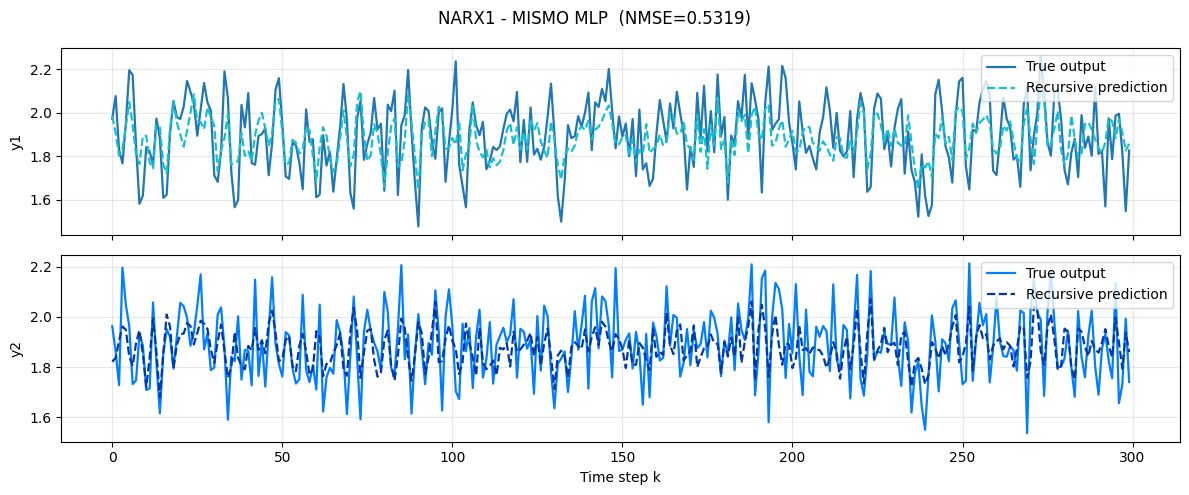

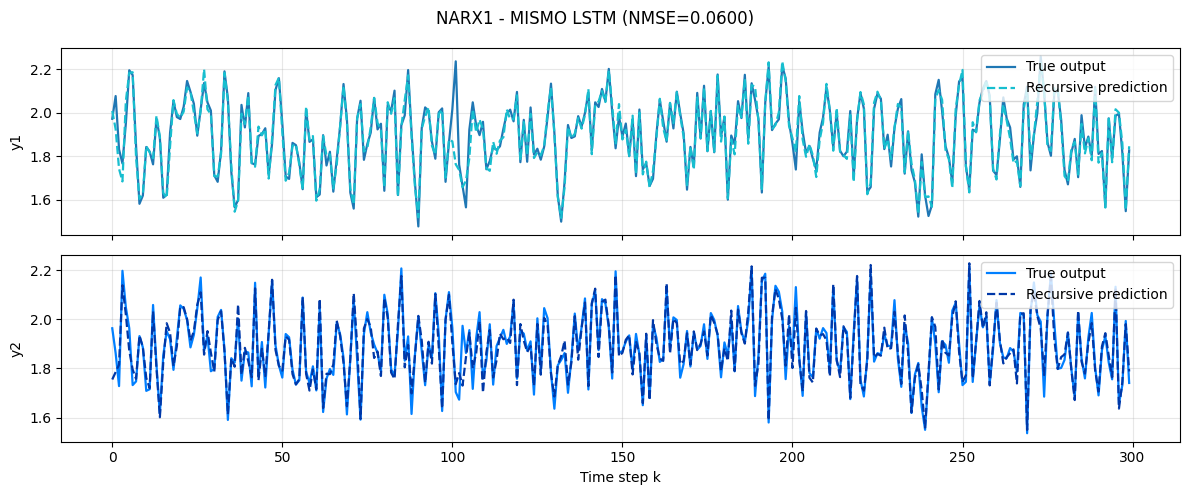

In [58]:
print("Training MISMO MLP on NARX1...")
narx1_mlp = train_mismo_torch(narx1_u_tr, narx1_y_tr,
                              d=best_n1_mismo['d'], na=best_n1_mismo['na'], s=best_n1_mismo['s'],
                              arch='mlp',
                              hidden_sizes=(256, 128, 64),
                              dropout=0.1,
                              max_epochs=500,
                              patience=40,
                              verbose=True)
narx1_mlp_yhat = mismo_rollout(narx1_mlp, narx1_u_ts,
                               best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'],
                               y_prefix=narx1_y_tr)
mlp1_nmse = nmse(narx1_y_ts, narx1_mlp_yhat)
mlp1_rmse = rmse(narx1_y_ts, narx1_mlp_yhat)
print(f"\nNARX1 | MISMO MLP  | NMSE={mlp1_nmse:.5f}  RMSE={mlp1_rmse:.5f}")

# Train LSTM on NARX1
print("\nTraining MISMO LSTM on NARX1...")
narx1_lstm = train_mismo_torch(narx1_u_tr, narx1_y_tr,
                               d=best_n1_mismo['d'], na=best_n1_mismo['na'], s=best_n1_mismo['s'],
                               arch='lstm',
                               lstm_hidden=128,
                               dropout=0.1,
                               max_epochs=500,
                               patience=40,
                               verbose=True)
narx1_lstm_yhat = mismo_rollout(narx1_lstm, narx1_u_ts,
                                best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'],
                                y_prefix=narx1_y_tr)
lstm1_nmse = nmse(narx1_y_ts, narx1_lstm_yhat)
lstm1_rmse = rmse(narx1_y_ts, narx1_lstm_yhat)
print(f"\nNARX1 | MISMO LSTM | NMSE={lstm1_nmse:.5f}  RMSE={lstm1_rmse:.5f}")

# Visual comparison
plot_comparison(narx1_y_ts, narx1_mlp_yhat,  title=f"NARX1 - MISMO MLP  (NMSE={mlp1_nmse:.4f})")
plot_comparison(narx1_y_ts, narx1_lstm_yhat, title=f"NARX1 - MISMO LSTM (NMSE={lstm1_nmse:.4f})")

#### Training and Evaluating on NARX2

Training MISMO MLP on NARX2...
  epoch=   1  tr_mse=0.996209  val_mse=0.942523
  epoch=  50  tr_mse=0.313696  val_mse=0.281573
  early stop @ epoch 94, best val_mse=0.275307

NARX2 | MISMO MLP  | NMSE=0.28424  RMSE=0.24278

Training MISMO LSTM on NARX2...
  epoch=   1  tr_mse=1.035884  val_mse=0.983316
  epoch=  50  tr_mse=0.192924  val_mse=0.222281
  epoch= 100  tr_mse=0.099970  val_mse=0.113685
  epoch= 150  tr_mse=0.095777  val_mse=0.109918
  early stop @ epoch 168, best val_mse=0.109703

NARX2 | MISMO LSTM | NMSE=0.12989  RMSE=0.16412


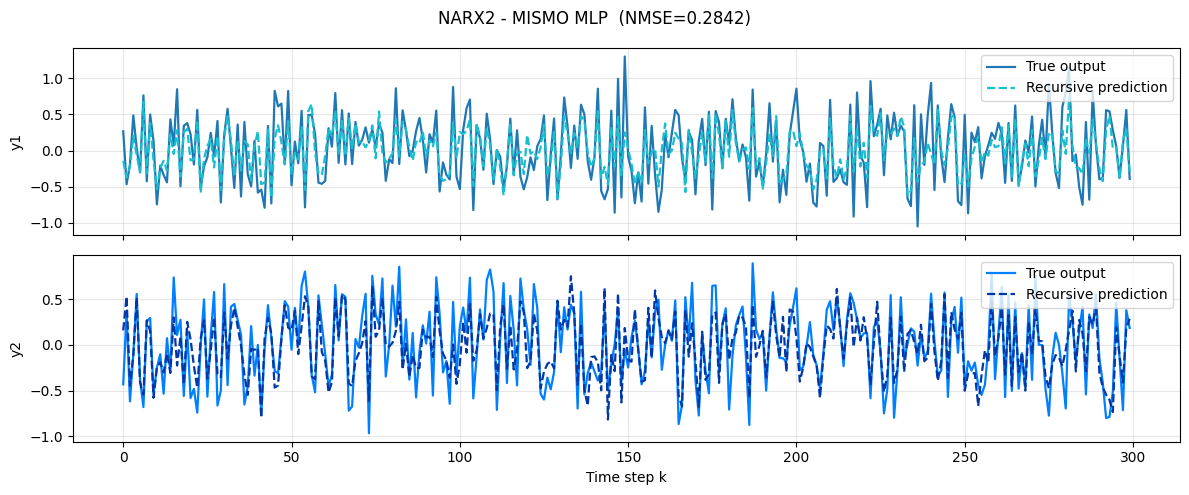

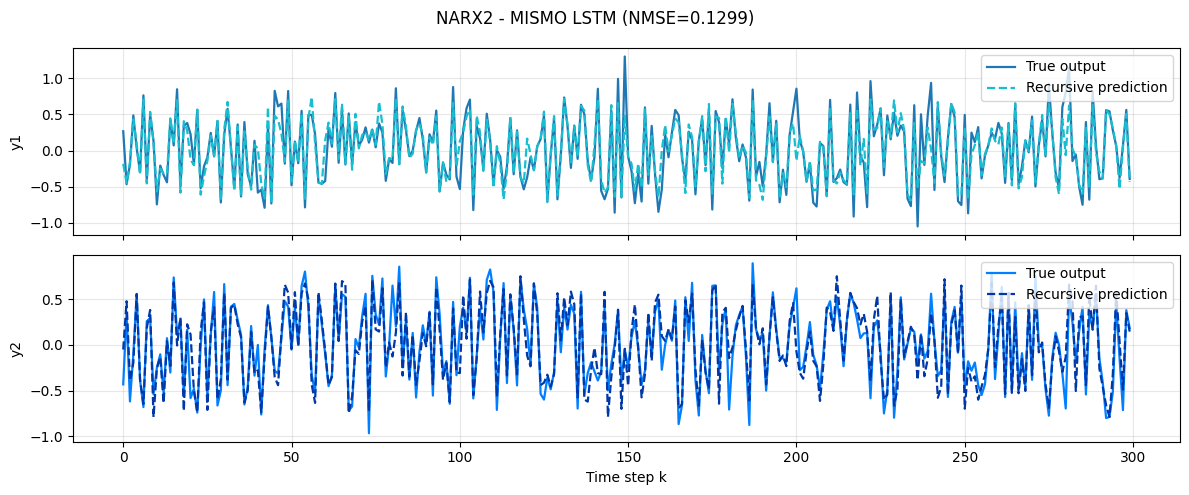

In [59]:
print("Training MISMO MLP on NARX2...")
narx2_mlp = train_mismo_torch(narx2_U_tr, narx2_y_tr,
                              d=best_n2_mismo['d'], na=best_n2_mismo['na'], s=best_n2_mismo['s'],
                              arch='mlp',
                              hidden_sizes=(256, 128, 64),
                              dropout=0.1,
                              max_epochs=500,
                              patience=40,
                              verbose=True)
narx2_mlp_yhat = mismo_rollout(narx2_mlp, narx2_U_ts,
                               best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'],
                               y_prefix=narx2_y_tr)
mlp2_nmse = nmse(narx2_y_ts, narx2_mlp_yhat)
mlp2_rmse = rmse(narx2_y_ts, narx2_mlp_yhat)
print(f"\nNARX2 | MISMO MLP  | NMSE={mlp2_nmse:.5f}  RMSE={mlp2_rmse:.5f}")

# Train LSTM on NARX2
print("\nTraining MISMO LSTM on NARX2...")
narx2_lstm = train_mismo_torch(narx2_U_tr, narx2_y_tr,
                               d=best_n2_mismo['d'], na=best_n2_mismo['na'], s=best_n2_mismo['s'],
                               arch='lstm',
                               lstm_hidden=128,
                               dropout=0.1,
                               max_epochs=500,
                               patience=40,
                               verbose=True)
narx2_lstm_yhat = mismo_rollout(narx2_lstm, narx2_U_ts,
                                best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'],
                                y_prefix=narx2_y_tr)
lstm2_nmse = nmse(narx2_y_ts, narx2_lstm_yhat)
lstm2_rmse = rmse(narx2_y_ts, narx2_lstm_yhat)
print(f"\nNARX2 | MISMO LSTM | NMSE={lstm2_nmse:.5f}  RMSE={lstm2_rmse:.5f}")

# Visual comparison
plot_comparison(narx2_y_ts, narx2_mlp_yhat,  title=f"NARX2 - MISMO MLP  (NMSE={mlp2_nmse:.4f})")
plot_comparison(narx2_y_ts, narx2_lstm_yhat, title=f"NARX2 - MISMO LSTM (NMSE={lstm2_nmse:.4f})")

#### Classical vs Deep Learning

In [60]:
# Aggregate all results into a single DataFrame for both pilots
def _ridge_nmse(u_tr, y_tr, u_ts, y_ts, d, na, s):
    mod = train_mismo(u_tr, y_tr, d, na, s)
    yhat = mismo_rollout(mod, u_ts, d, na, s, y_prefix=y_tr)
    return nmse(y_ts, yhat), rmse(y_ts, yhat)

ridge1_nmse, ridge1_rmse = _ridge_nmse(narx1_u_tr, narx1_y_tr, narx1_u_ts, narx1_y_ts,
                                       best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'])
ridge2_nmse, ridge2_rmse = _ridge_nmse(narx2_U_tr, narx2_y_tr, narx2_U_ts, narx2_y_ts,
                                       best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'])

comparison = pd.DataFrame([
    {'pilot': 'NARX1', 'model': 'RidgeCV',    'NMSE': ridge1_nmse, 'RMSE': ridge1_rmse},
    {'pilot': 'NARX1', 'model': 'MISMO MLP',  'NMSE': mlp1_nmse,   'RMSE': mlp1_rmse},
    {'pilot': 'NARX1', 'model': 'MISMO LSTM', 'NMSE': lstm1_nmse,  'RMSE': lstm1_rmse},
    {'pilot': 'NARX2', 'model': 'RidgeCV',    'NMSE': ridge2_nmse, 'RMSE': ridge2_rmse},
    {'pilot': 'NARX2', 'model': 'MISMO MLP',  'NMSE': mlp2_nmse,   'RMSE': mlp2_rmse},
    {'pilot': 'NARX2', 'model': 'MISMO LSTM', 'NMSE': lstm2_nmse,  'RMSE': lstm2_rmse},
])

print("Classical vs Deep Learning comparison:")
print(comparison.to_string(index=False))

Classical vs Deep Learning comparison:
pilot      model     NMSE     RMSE
NARX1    RidgeCV 0.049567 0.034062
NARX1  MISMO MLP 0.531915 0.111581
NARX1 MISMO LSTM 0.060040 0.037488
NARX2    RidgeCV 0.130723 0.164646
NARX2  MISMO MLP 0.284240 0.242783
NARX2 MISMO LSTM 0.129892 0.164122


#### Step 1: Integration into a scikit-learn pipeline

Given everything we have developed in the above cells, we now want to integrate all of this logic inside a scikit-learn pipeline in order to automatize the logic and be able to apply it to various data sources. 

##### Data transformation (MISMO)
The pipeline uses a custom `MismoTransformer` that automates both structural parameter selection and block-feature construction for the MISMO strategy.

During training, `pipeline.fit(X, y)` first estimates the best `(d, n_a, s)` on a chronological split, then builds MISMO feature blocks and aligned block targets.

During prediction, `pipeline.predict(X_test)` performs block rollout using known future inputs and previously predicted outputs, which enables stable long-horizon forecasting.

Leading missing values created by lag construction are handled with `SimpleImputer` in the pipeline.

In [61]:
class ParameterSelector:
    def __init__(self, u_train: np.ndarray, y_train: np.ndarray, val_ratio: float = 0.30, random_state: int = 42) -> None:
        self.u_train = np.asarray(u_train, dtype=float)
        self.y_train = np.asarray(y_train, dtype=float)
        self.val_ratio = float(val_ratio)
        self.random_state = int(random_state)

        if self.u_train.ndim != 2 or self.y_train.ndim != 2:
            raise ValueError('u_train and y_train must be 2D arrays.')
        if self.u_train.shape[0] != self.y_train.shape[0]:
            raise ValueError('u_train and y_train must have the same number of rows.')
        if self.y_train.shape[1] != 2:
            raise ValueError('ParameterSelector expects exactly 2 output channels.')
        if not (0.0 < self.val_ratio < 1.0):
            raise ValueError('val_ratio must be in (0, 1).')

    @staticmethod
    def cross_correlation(y: np.ndarray, u: np.ndarray, max_lag: int = 40) -> Tuple[np.ndarray, np.ndarray]:
        return cross_correlation(y=y, u=u, max_lag=max_lag)

    def estimate_delay_candidates(
        self,
        max_lag: int = 40,
        max_d: int = 10,
        baseline_stop: int = 4,
        around_median_radius: int = 2,
        around_min_radius: int = 1,
    ) -> Tuple[List[int], Dict[Tuple[int, int], int]]:
        nu, ny = self.u_train.shape[1], self.y_train.shape[1]
        peak_lags: Dict[Tuple[int, int], int] = {}

        for i in range(nu):
            for j in range(ny):
                lags, corr = self.cross_correlation(self.y_train[:, j], self.u_train[:, i], max_lag=max_lag)
                pos_mask = lags >= 0
                if np.any(pos_mask):
                    peak = int(lags[pos_mask][np.argmax(np.abs(corr[pos_mask]))])
                else:
                    peak = 0
                peak_lags[(i, j)] = peak

        values = np.array(list(peak_lags.values()), dtype=int)
        d_min = int(values.min()) if values.size else 0
        d_med = int(np.median(values)) if values.size else 0

        baseline = set(range(0, max(1, baseline_stop + 1)))
        around_med = set(range(max(0, d_med - around_median_radius), d_med + around_median_radius + 2))
        around_min = set(range(max(0, d_min - around_min_radius), d_min + around_min_radius + 2))
        d_candidates = sorted(d for d in (baseline | around_med | around_min) if 0 <= d <= max_d)

        if not d_candidates:
            d_candidates = [0, 1, 2]

        return d_candidates, peak_lags

    def _make_single_output_model(self, model_name: str, model_params: Optional[Dict[str, Any]] = None):
        params = dict(model_params or {})
        name = model_name.lower()

        if name == 'ridge':
            alpha = float(params.get('alpha', 1.0))
            return make_pipeline(StandardScaler(), Ridge(alpha=alpha))

        if name == 'knn':
            n_neighbors = int(params.get('n_neighbors', 7))
            return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=n_neighbors))

        if name in ('rf', 'random_forest', 'randomforest'):
            rf_params = {
                'n_estimators': int(params.get('n_estimators', 300)),
                'max_depth': params.get('max_depth', None),
                'min_samples_leaf': int(params.get('min_samples_leaf', 1)),
                'random_state': self.random_state,
            }
            return RandomForestRegressor(**rf_params)

        raise ValueError(f"Unsupported model_name '{model_name}'.")

    def fit_two_output_models(
        self,
        x_train: np.ndarray,
        y_train: np.ndarray,
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
    ):
        model_y1 = self._make_single_output_model(model_name, model_params)
        model_y2 = self._make_single_output_model(model_name, model_params)
        model_y1.fit(x_train, y_train[:, 0])
        model_y2.fit(x_train, y_train[:, 1])
        return model_y1, model_y2

    def recursive_rollout(
        self,
        u: np.ndarray,
        model_y1,
        model_y2,
        d: int,
        na: int,
        nb: int,
        y_prefix: Optional[np.ndarray] = None,
    ) -> np.ndarray:
        return recursive_rollout_mimo(
            U=u,
            model_y1=model_y1,
            model_y2=model_y2,
            d=d,
            na=na,
            nb=nb,
            y_prefix=y_prefix,
        )

    def evaluate_config(
        self,
        d: int,
        na: int,
        nb: int,
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
        min_samples: int = 30,
    ) -> Optional[Dict[str, Any]]:
        X, Y_next = build_mimo_features(self.u_train, self.y_train, d=d, na=na, nb=nb)
        if X.size == 0:
            return None

        horizon = max(d + na, nb)
        split_idx, _, train_mask, val_mask = build_masks(len(self.y_train), horizon, self.val_ratio)

        if train_mask.sum() < min_samples or val_mask.sum() < min_samples:
            return None

        model_y1, model_y2 = self.fit_two_output_models(
            X[train_mask], Y_next[train_mask], model_name=model_name, model_params=model_params
        )

        Y_val_pred = np.column_stack([
            model_y1.predict(X[val_mask]),
            model_y2.predict(X[val_mask]),
        ])

        Y_roll = self.recursive_rollout(
            self.u_train, model_y1, model_y2, d=d, na=na, nb=nb, y_prefix=self.y_train[:split_idx]
        )
        Y_val_rec = Y_roll[split_idx:]

        return {
            'd': int(d),
            'na': int(na),
            'nb': int(nb),
            'model_name': str(model_name),
            'model_params': dict(model_params or {}),
            'split_idx': int(split_idx),
            'n_features': int(X.shape[1]),
            'n_train': int(train_mask.sum()),
            'n_val': int(val_mask.sum()),
            'one_step_nmse': float(nmse(Y_next[val_mask], Y_val_pred)),
            'one_step_rmse': float(rmse(Y_next[val_mask], Y_val_pred)),
            'recursive_nmse': float(nmse(self.y_train[split_idx:], Y_val_rec)),
            'recursive_rmse': float(rmse(self.y_train[split_idx:], Y_val_rec)),
        }

    @staticmethod
    def _sort_cols(objective: str) -> List[str]:
        options = {
            'one_step_nmse': ['one_step_nmse', 'recursive_nmse', 'n_features'],
            'recursive_nmse': ['recursive_nmse', 'one_step_nmse', 'n_features'],
        }
        if objective not in options:
            raise ValueError("objective must be either 'one_step_nmse' or 'recursive_nmse'.")
        return options[objective]

    def search(
        self,
        order_grid: Dict[str, Iterable[int]],
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
        objective: str = 'recursive_nmse',
        min_samples: int = 30,
    ) -> pd.DataFrame:
        rows: List[Dict[str, Any]] = []
        for cfg in ParameterGrid(order_grid):
            row = self.evaluate_config(
                d=int(cfg['d']),
                na=int(cfg['na']),
                nb=int(cfg['nb']),
                model_name=model_name,
                model_params=model_params,
                min_samples=min_samples,
            )
            if row is not None:
                rows.append(row)

        if not rows:
            return pd.DataFrame()

        sort_cols = self._sort_cols(objective)
        return pd.DataFrame(rows).sort_values(sort_cols).reset_index(drop=True)

    def search_with_model_spaces(
        self,
        order_grid: Dict[str, Iterable[int]],
        model_spaces: Dict[str, List[Dict[str, Any]]],
        objective: str = 'recursive_nmse',
        min_samples: int = 30,
        verbose: bool = False,
        progress_every: int = 25,
        max_evals: Optional[int] = None,
        time_budget_seconds: Optional[float] = None,
        early_stop_nmse: Optional[float] = None,
    ) -> pd.DataFrame:
        sort_cols = self._sort_cols(objective)
        objective_col = sort_cols[0]
        grid = list(ParameterGrid(order_grid))

        rows: List[Dict[str, Any]] = []
        eval_count = 0
        t0 = time.perf_counter()
        stop = False

        for model_name, param_list in model_spaces.items():
            for params in (param_list or [{}]):
                for cfg in grid:
                    if max_evals is not None and eval_count >= int(max_evals):
                        stop = True
                        break
                    if time_budget_seconds is not None and (time.perf_counter() - t0) >= float(time_budget_seconds):
                        stop = True
                        break

                    row = self.evaluate_config(
                        d=int(cfg['d']),
                        na=int(cfg['na']),
                        nb=int(cfg['nb']),
                        model_name=model_name,
                        model_params=params,
                        min_samples=min_samples,
                    )
                    eval_count += 1

                    if row is not None:
                        rows.append(row)
                        if early_stop_nmse is not None and float(row[objective_col]) <= float(early_stop_nmse):
                            stop = True
                            break

                    if verbose and (eval_count == 1 or eval_count % max(1, int(progress_every)) == 0):
                        best_so_far = min((r[objective_col] for r in rows), default=np.inf)
                        elapsed_min = (time.perf_counter() - t0) / 60.0
                        print(f"[search] evals={eval_count} elapsed={elapsed_min:.1f}m best_{objective_col}={best_so_far:.4f}")

                if stop:
                    break
            if stop:
                break

        if not rows:
            return pd.DataFrame()

        return pd.DataFrame(rows).sort_values(sort_cols).reset_index(drop=True)

    @staticmethod
    def best_config(results: pd.DataFrame) -> Dict[str, Any]:
        if results.empty:
            raise ValueError('results is empty; cannot extract best configuration.')
        row = results.iloc[0]
        params = row.get('model_params', {})
        return {
            'd': int(row['d']),
            'na': int(row['na']),
            'nb': int(row['nb']),
            'model_name': str(row.get('model_name', 'ridge')),
            'model_params': dict(params) if isinstance(params, dict) else {},
        }

    def fit_full_models(
        self,
        d: int,
        na: int,
        nb: int,
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
    ):
        X_all, Y_next = build_mimo_features(self.u_train, self.y_train, d=d, na=na, nb=nb)
        if X_all.size == 0:
            raise ValueError('No samples available for full training with the selected orders.')
        model_y1, model_y2 = self.fit_two_output_models(
            X_all, Y_next, model_name=model_name, model_params=model_params
        )
        return model_y1, model_y2, {'n_samples': int(X_all.shape[0]), 'n_features': int(X_all.shape[1])}

In [62]:
class LaggedTransformer(BaseEstimator, TransformerMixin):
    """
    Custom transformer for converting a raw NARX DataFrame into lagged features.
    """
    
    def __init__(
        self,
        n_a=None,
        n_b=None,
        d=None,
        order_grid: Optional[Dict[str, Iterable[int]]] = None,
        selection_model: str = 'ridge',
        selection_model_params: Optional[Dict[str, Any]] = None,
        selection_objective: str = 'recursive_nmse',
        val_ratio: float = 0.30,
        random_state: int = 42,
        min_samples: int = 30,
        max_lag: int = 40,
        max_d: int = 10,
    ):
        self.n_a = n_a
        self.n_b = n_b
        self.d = d
        self.order_grid = order_grid
        self.selection_model = selection_model
        self.selection_model_params = selection_model_params
        self.selection_objective = selection_objective
        self.val_ratio = val_ratio
        self.random_state = random_state
        self.min_samples = min_samples
        self.max_lag = max_lag
        self.max_d = max_d

    def fit(self, X, y):
        # Only called during the training phase
        if self.n_a is None or self.n_b is None or self.d is None:
            self.n_a, self.n_b, self.d = self._find_best_parameters(X, y)
        else:
            self.n_a = int(self.n_a)
            self.n_b = int(self.n_b)
            self.d = int(self.d)
        return self
   
    def transform(self, data: pd.DataFrame):
        # Called during both the training and test phases
        # This is the same logic as the create_lagged_features function

        X = data.copy()

        # During multiple-steps-ahead predicitons for the test set, y columns don't exist yet -> Initalized with zeros
        if 'y1(k)' not in X.columns:
            X['y1(k)'] = 0.0
        if 'y2(k)' not in X.columns:
            X['y2(k)'] = 0.0

        # For outputs lags, we need delay from d to d + n_a
        y1_lags, y2_lags = [], []

        for i in range(self.d, self.d + self.n_a + 1):
            y1_col = 'y1(k)' if i == 0 else f'y1(k-{i})'
            y2_col = 'y2(k)' if i == 0 else f'y2(k-{i})'

            if i >= 0:
                X[y1_col] = X['y1(k)'].shift(i)
                X[y2_col] = X['y2(k)'].shift(i)

            y1_lags.append(y1_col)
            y2_lags.append(y2_col)

        # For inputs lags, we need the current time step k, then k-1 up to k-n_b
        u1_lags, u2_lags = ['u1(k)'], ['u2(k)']

        for i in range(1, self.n_b + 1):
            u1_col, u2_col = f'u1(k-{i})', f'u2(k-{i})'

            X[u1_col] = X['u1(k)'].shift(i)
            X[u2_col] = X['u2(k)'].shift(i)

            u1_lags.append(u1_col)
            u2_lags.append(u2_col)

        # Small modifictaiton to have a proper order 
        final_column_order = y1_lags + y2_lags + u1_lags + u2_lags
        return X[final_column_order]
    
    def _find_best_parameters(self, data, y):
        X_df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
        if 'u1(k)' not in X_df.columns or 'u2(k)' not in X_df.columns:
            raise ValueError("Expected input columns 'u1(k)' and 'u2(k)' in X.")
        u_train = X_df[['u1(k)', 'u2(k)']].to_numpy(dtype=float)

        if y is None:
            if 'y1(k)' not in X_df.columns or 'y2(k)' not in X_df.columns:
                raise ValueError("y is None and X does not contain 'y1(k)'/'y2(k)'.")
            y_train = X_df[['y1(k)', 'y2(k)']].to_numpy(dtype=float)
        else:
            y_train = np.asarray(y, dtype=float)
            if y_train.ndim == 1:
                y_train = y_train.reshape(-1, 1)

        selector = ParameterSelector(
            u_train=u_train,
            y_train=y_train,
            val_ratio=self.val_ratio,
            random_state=self.random_state,
        )

        if self.order_grid is None:
            d_candidates, _ = selector.estimate_delay_candidates(
                max_lag=self.max_lag,
                max_d=self.max_d,
            )
            order_grid = {
                'd': d_candidates,
                'na': list(range(1, 9)),
                'nb': list(range(1, 7)),
            }
        else:
            order_grid = self.order_grid

        results = selector.search(
            order_grid,
            model_name=self.selection_model,
            model_params=self.selection_model_params,
            objective=self.selection_objective,
            min_samples=self.min_samples,
        )
        if results.empty:
            raise RuntimeError('Parameter selection returned no valid configuration.')

        best = selector.best_config(results)
        self.best_orders_ = best
        self.selection_results_ = results
        return int(best['na']), int(best['nb']), int(best['d'])

##### Selection of the best model (classical + deep learning)

After MISMO feature construction, the same pipeline evaluates candidate regressors and selects the best one.

The `ModelSelector` compares classical models and deep models on the same validation fold using direct NMSE on MISMO block targets.

When `pipeline.fit(...)` is called, the transformer selects `(d, n_a, s)`, features are built, and the selector keeps the best model.

When `pipeline.predict(...)` is called, predictions are generated through MISMO rollout with the selected model.

In [63]:
def _rollout_score(model, X_val_df, y_val_np, d, na, max_explosion=1e3):
    """
    Multi-step (rollout) NMSE for a candidate model.
    Treats *X_val_df* as RAW (un-scaled) features so we can write predicted
    outputs back into the lag columns directly. Each candidate model is
    expected to embed its own StandardScaler if it needs one.
    """
    n_steps = len(X_val_df)
    preds = np.zeros((n_steps, 2))
    X_sim = X_val_df.copy()
    idx = X_val_df.index

    for k in range(n_steps):
        for lag in range(d, d + na + 1):
            prev_k = k - lag
            if prev_k >= 0:
                y1_col = 'y1(k)' if lag == 0 else f'y1(k-{lag})'
                y2_col = 'y2(k)' if lag == 0 else f'y2(k-{lag})'
                if y1_col in X_sim.columns:
                    X_sim.at[idx[k], y1_col] = preds[prev_k, 0]
                if y2_col in X_sim.columns:
                    X_sim.at[idx[k], y2_col] = preds[prev_k, 1]

        row = X_sim.loc[[idx[k]]]
        try:
            preds[k] = np.asarray(model.predict(row)).reshape(-1)[:2]
        except Exception:
            return np.inf, True

        if not np.all(np.isfinite(preds[k])) or np.max(np.abs(preds[k])) > max_explosion:
            return np.inf, True

    score = nmse(y_val_np, preds)
    diverged = (not np.isfinite(score)) or score > 5.0
    return score, diverged

In [64]:
class ModelSelector(BaseEstimator, RegressorMixin):
    """
    Selects the best NARX model by ROLLOUT (multi-step) NMSE on the last
    TimeSeriesSplit fold — the metric that actually matches the project.

    Each candidate embeds its own StandardScaler so the input X may stay
    in raw units (necessary for the rollout to write predictions back into
    lag columns).
    """

    def __init__(
        self,
        deep_candidates: Optional[List[Dict[str, Any]]] = None,
        d: Optional[int] = None,
        na: Optional[int] = None,
        random_state: int = 42,
        verbose: bool = True,
    ):
        self.deep_candidates = deep_candidates
        self.d = d
        self.na = na
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        d  = self.d  if self.d  is not None else 0
        na = self.na if self.na is not None else 0

        # Reconstruct column names so rollout can find lag columns
        y1_cols = ['y1(k)' if i == 0 else f'y1(k-{i})' for i in range(d, d + na + 1)]
        y2_cols = ['y2(k)' if i == 0 else f'y2(k-{i})' for i in range(d, d + na + 1)]
        n_y = len(y1_cols) + len(y2_cols)
        n_u = X.shape[1] - n_y
        u_cols = [f'u_feat{i}' for i in range(n_u)]
        all_cols = y1_cols + y2_cols + u_cols

        X_arr = np.asarray(X)
        X_df  = pd.DataFrame(X_arr, columns=all_cols)
        y_np  = np.asarray(y)
        if y_np.ndim == 1:
            y_np = y_np.reshape(-1, 1)

        tscv = TimeSeriesSplit(n_splits=5)
        last_train_idx, last_val_idx = list(tscv.split(X_df))[-1]
        X_tr_df = X_df.iloc[last_train_idx].reset_index(drop=True)
        X_val_df = X_df.iloc[last_val_idx].reset_index(drop=True)
        y_tr_np  = y_np[last_train_idx]
        y_val_np = y_np[last_val_idx]

        candidates: List[Dict[str, Any]] = []

        def evaluate(name, builder, params, kind):
            """`builder` is a callable returning a fresh estimator instance."""
            try:
                model = builder()
                model.fit(X_tr_df, y_tr_np)
                score, diverged = _rollout_score(model, X_val_df, y_val_np, d=d, na=na)
            except Exception as exc:
                model, score, diverged = None, np.inf, True
                if self.verbose:
                    print(f'  {name:<25s} FAILED: {type(exc).__name__}: {str(exc)[:80]}')
                    return
            if self.verbose:
                tag = '  DIVERGED' if diverged else ''
                print(f'  {name:<25s} rollout NMSE = {score:.4f}{tag}')
            candidates.append({
                'name': name, 'score': float(score),
                'builder': builder, 'model': model,
                'params': params, 'kind': kind,
                'diverged': diverged,
            })

        # ---- Linear models (Ridge with light regularisation) ----
        if self.verbose: print('\nLinear / Ridge candidates...')
        evaluate('Linear Regression',
                 lambda: make_pipeline(StandardScaler(), LinearRegression()),
                 {}, 'classical')
        for alpha in [0.1, 1.0, 10.0, 100.0]:
            evaluate(f'Ridge(α={alpha})',
                     lambda a=alpha: make_pipeline(StandardScaler(), Ridge(alpha=a)),
                     {'alpha': alpha}, 'classical')

        # ---- KNN ----
        if self.verbose: print('\nKNN candidates...')
        for k_n in [3, 5, 10, 20]:
            evaluate(f'KNN(k={k_n})',
                     lambda kn=k_n: make_pipeline(StandardScaler(),
                                                  KNeighborsRegressor(n_neighbors=kn)),
                     {'n_neighbors': k_n}, 'classical')

        # ---- Random Forest (conservative grid: deep RFs tend to diverge) ----
        if self.verbose: print('\nRandom Forest candidates (conservative grid)...')
        for n_est in [100, 300]:
            for max_d in [5, 10, None]:
                for msl in [2, 5]:
                    evaluate(
                        f'RF(n={n_est}, depth={max_d}, msl={msl})',
                        lambda ne=n_est, md=max_d, ml=msl: RandomForestRegressor(
                            n_estimators=ne, max_depth=md, min_samples_leaf=ml,
                            random_state=self.random_state, n_jobs=-1,
                        ),
                        {'n_estimators': n_est, 'max_depth': max_d,
                         'min_samples_leaf': msl},
                        'classical'
                    )

        # ---- Deep models (TorchNARXRegressor handles its own scaling) ----
        if _TORCH_AVAILABLE:
            if self.verbose: print('\nDeep model candidates...')
            deep_spaces = self.deep_candidates or [
                {'name': 'Deep MLP small',
                 'params': {'arch': 'mlp', 'hidden_sizes': (64, 32),
                            'max_epochs': 200, 'patience': 20, 'dropout': 0.10}},
                {'name': 'Deep MLP large',
                 'params': {'arch': 'mlp', 'hidden_sizes': (256, 128, 64),
                            'max_epochs': 300, 'patience': 25, 'dropout': 0.15}},
            ]
            for spec in deep_spaces:
                params = dict(spec.get('params') or {})
                params.setdefault('random_state', self.random_state)
                evaluate(spec.get('name', 'Deep Model'),
                         lambda p=params: TorchNARXRegressor(**p),
                         params, 'deep')
        else:
            if self.verbose: print('\nDeep models skipped: PyTorch not available.')

        # ---- Pick best by lowest rollout NMSE; prefer non-diverged ----
        if not candidates:
            raise RuntimeError('No candidate models were evaluated.')

        non_diverged = [c for c in candidates if not c['diverged']]
        pool = non_diverged if non_diverged else candidates
        best = min(pool, key=lambda c: c['score'])

        # Refit the winner on ALL training data
        try:
            final_model = best['builder']()
            final_model.fit(X_df, y_np)
            best['model'] = final_model
        except Exception as exc:
            if self.verbose:
                print(f'⚠ refit on full data failed for {best["name"]}: {exc}')

        self.best_name_   = best['name']
        self.best_params_ = best.get('params', {})
        self.best_score_  = float(best['score'])
        self.best_model_  = best['model']
        self.candidates_  = candidates

        if self.verbose:
            print('\n── Selection Summary (sorted by rollout NMSE) ──')
            for c in sorted(candidates, key=lambda x: x['score']):
                tag = '  DIVERGED' if c['diverged'] else ''
                print(f"  {c['name']:<25s}  NMSE={c['score']:.4f}{tag}")
            print(f'\n>>> Best: {self.best_name_}  '
                  f'(rollout NMSE = {self.best_score_:.4f})')

        return self

    def predict(self, X):
        return self.best_model_.predict(X)


#### Step 2. Definition of the pipeline

The pipeline is MISMO-only and keeps a simple structure:

1. `MismoTransformer` to select `(d, n_a, s)` and build block features.
2. `SimpleImputer` to fill any leading missing values.
3. `ModelSelector` to choose the best regressor for MISMO block targets.

This ensures one consistent training and prediction path entirely based on MISMO.

Pipeline behavior summary:

##### Training phase: `pipeline.fit(X_train, y_train)`

1. The best MISMO structural parameters `(d, n_a, s)` are selected.
2. MISMO block features and aligned block targets are built.
3. Missing values are imputed with zeros.
4. Candidate models are evaluated and the best one is selected.

##### Test phase: `pipeline.predict(X_test)`

1. The selected MISMO structure is reused.
2. Predictions are produced with block rollout until the full horizon is covered.
3. Outputs are returned as full-horizon arrays for `y_1` and `y_2`.

#### Step 3. MISMO pipeline checks

Now that the MISMO pipeline is defined, we can verify data formatting and run end-to-end checks before deployment on the real dataset.

##### Data formatting for the MISMO pipeline

The helper below converts raw arrays into the expected dataframe format and is reused for training and inference.

In [67]:
def make_pipeline_df(U, Y):
    """
    Convert raw numpy arrays (U: (N, n_u), Y: (N, 2)) into the DataFrame format
    expected by the MISMO pipeline: columns u1(k), u2(k), y1(k), y2(k).
    """
    U2 = np.asarray(U)
    Y2 = np.asarray(Y)
    if U2.ndim == 1:
        U2 = U2.reshape(-1, 1)
    if U2.shape[1] == 1:
        U2 = np.column_stack([U2, np.zeros(len(U2))])
    return pd.DataFrame(
        np.column_stack([U2, Y2]),
        columns=['u1(k)', 'u2(k)', 'y1(k)', 'y2(k)']
    )

In [68]:
df_pipe_narx1 = make_pipeline_df(narx1_u_tr, narx1_y_tr)
X_pipe_narx1 = df_pipe_narx1.copy()

In [69]:
df_pipe_narx2 = make_pipeline_df(narx2_U_tr, narx2_y_tr)
X_pipe_narx2 = df_pipe_narx2.copy()

In [70]:
print('NARX1 pilot pipeline now uses MISMO in the deployment section below.')

NARX1 pilot pipeline now uses MISMO in the deployment section below.


In [71]:
print('NARX2 pilot pipeline now uses MISMO in the deployment section below.')

NARX2 pilot pipeline now uses MISMO in the deployment section below.


##### Multiple-Steps-Ahead Prediction with MISMO

Once the MISMO pipeline is trained, full-horizon predictions are produced with a block rollout strategy.

At each anchor time step, the model predicts a block of `s` future outputs in one shot and then reuses those predictions to continue the rollout until the full horizon is covered.

This behavior is implemented in the `pipeline.predict(...)` method returned by `make_mismo_pipeline(...)`, which internally calls `mismo_rollout(...)`.

In [72]:
def multiple_steps_ahead_pipeline(pipeline, U_test, y_init=None, clip_threshold=None):
    """MISMO full-horizon prediction wrapper."""
    preds = pipeline.predict(U_test, y_init=y_init)
    if clip_threshold is not None:
        preds = np.clip(preds, -clip_threshold, clip_threshold)
    return preds

The capabilities of linear and tree-based models have been thoroughly established.
A key question is whether a neural network can address the remaining performance gap.
This investigation retains the established NARX structure,
maintaining the lag-based features while replacing the final regression step with a more expressive model.

The lag features effectively encode the relevant historical information of the system.
A neural network applied to these features is expected to capture nonlinear interaction terms
that ordinary least squares (OLS) regression may overlook and to generalize more effectively than a random forest.

Four neural network architectures are evaluated:

- **Residual MLP**: This architecture serves as the new default. Skip connections facilitate efficient gradient flow.
through deep networks, while Gaussian Error Linear Unit (GELU) activations replace Rectified Linear Unit (ReLU) for smoother regression.
Layer normalization ensures each residual block remains well-conditioned. This architecture demonstrates consistently strong performance of tabular-style lag vectors.s.
- **Temporal Convolutional Network (TCN)**: Dilated causal convolutions reshape the
lag vector into a short sequence and construct an exponentially expanding receptive field.
This architecture avoids sequential bottlenecks, trains efficiently, and is particularly effective when the ordering of lag features is important.
-  **Plain MLP** : the originaPlain MLP: The original version is retained as a reference baseline.is time. The recurrent state can model longer-range lag
dependencies, although this comes at the cost of slower training.

All four models incorporate two key enhancements of input noise injection (input_noise parameter): During recursive prediction, the
model uses its own predictions as subsequent inputs, resulting in a test-time input distribution
that differs slightly from the training distribution because the predicted output values contain some error. Adding
a small amount of Gaussian noise to the training inputs mitigates this discrepancy and consistently reduces normalized mean squared error (NMSE)
on extended prediction sequences. This approach effectively trains the model to manage its own prediction errors.

Ensemble over random seeds (n_seeds parameter): The same architecture is trained
multiple times with different seeds, and the predictions are averaged. Each model sees exactly
, resulting in no additional data cost and providing variance reduction at no extra expense.

Inputs and outputs are scaled using statistics derived exclusively from the training split to prevent information leakage from future observations. The data is divided chronologically, with 70% allocated for training and 30% for validation, preserving the temporal sequence of the signal. Optimization is performed using AdamW with gradient clipping at max_norm = 1.0 to ensure stable updates. A CosineAnnealingWarmRestarts schedule periodically resets the learning rate, enabling the model to escape sharp local minima that may occur with standard annealing. Validation mean squared error (MSE) is monitored at each epoch, and the best checkpoint is restored upon early stopping, ensuring that the final model reflects the lowest generalization error observed during training.

In [73]:
from copy import deepcopy
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler

In [74]:
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    _TORCH_AVAILABLE = True
except Exception as exc:
    _TORCH_AVAILABLE = False
    _TORCH_IMPORT_ERROR = exc

In [75]:
d  = best_n1_mimo['d']   # 1
na = best_n1_mimo['na']  # 6
nb = best_n1_mimo['nb']  # 3

X_narx1, y_narx1 = build_mimo_features(narx1_u_tr, narx1_y_tr, d=d, na=na, nb=nb)

print(f"d={d}, na={na}, nb={nb}")
print(f"X_narx1 shape: {X_narx1.shape}") 

expected = (na + 1) * 2 + (nb + 1) * narx1_u_tr.shape[1]
assert X_narx1.shape[1] == expected, f"Shape mismatch: {X_narx1.shape[1]} vs {expected}"


X_np = np.asarray(X_narx1, dtype=np.float32)
y_np = np.asarray(y_narx1, dtype=np.float32)

split_idx_dl = int(0.70 * len(X_np))
split_idx_dl = max(32, min(split_idx_dl, len(X_np) - 32))

X_train_np, X_val_np = X_np[:split_idx_dl], X_np[split_idx_dl:]
y_train_np, y_val_np = y_np[:split_idx_dl], y_np[split_idx_dl:]

x_mean = X_train_np.mean(axis=0)
x_std = X_train_np.std(axis=0)
x_std = np.where(np.abs(x_std) < 1e-12, 1.0, x_std)

X_train_sc = (X_train_np - x_mean) / x_std
X_val_sc = (X_val_np - x_mean) / x_std

d=1, na=2, nb=6
X_narx1 shape: (693, 13)


In [76]:
from copy import deepcopy
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, TensorDataset
    _TORCH_AVAILABLE = True
except Exception as exc:
    _TORCH_AVAILABLE = False
    _TORCH_IMPORT_ERROR = exc


if _TORCH_AVAILABLE:

    # Architecture 1: Residual MLP
    # we use skip connections so gradients flow cleanly through deep networks
    class _ResidualBlock(nn.Module):
        def __init__(self, dim, dropout=0.1):
            # we use two linear layers, a layernorm, and dropout to form one residual block
            super().__init__()
            self.fc1  = nn.Linear(dim, dim * 2)
            self.fc2  = nn.Linear(dim * 2, dim)
            self.norm = nn.LayerNorm(dim)
            self.drop = nn.Dropout(dropout)

        def forward(self, x):
            # we expand through fc1, apply gelu and dropout, compress back with fc2, then add the residual and normalize
            h = self.drop(F.gelu(self.fc1(x)))
            return self.norm(x + self.fc2(h))

    class _ResidualMLP(nn.Module):
        def __init__(self, in_dim, out_dim, hidden_dim=256, n_blocks=4, dropout=0.1):
            # we project inputs to hidden_dim, stack the residual blocks, then attach an output head
            super().__init__()
            self.proj   = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.GELU())
            self.blocks = nn.Sequential(*[_ResidualBlock(hidden_dim, dropout) for _ in range(n_blocks)])
            self.head   = nn.Linear(hidden_dim, out_dim)
            # we use a small gain so the network starts close to zero and improves from there
            nn.init.xavier_uniform_(self.head.weight, gain=0.1)
            nn.init.zeros_(self.head.bias)

        def forward(self, x):
            # we project, pass through all blocks in order, then map to the output dimension
            return self.head(self.blocks(self.proj(x)))

    # Architecture 2: Temporal Convolutional Network
    # we use dilated causal convolutions so the receptive field grows without a sequential bottleneck
    class _TCNBlock(nn.Module):
        def __init__(self, n_ch, kernel_size=3, dilation=1, dropout=0.1):
            # we use causal padding so the convolution never looks into future time steps
            super().__init__()
            pad = (kernel_size - 1) * dilation
            self.net = nn.Sequential(
                nn.ConstantPad1d((pad, 0), 0),
                nn.Conv1d(n_ch, n_ch, kernel_size, dilation=dilation),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.ConstantPad1d((pad, 0), 0),
                nn.Conv1d(n_ch, n_ch, kernel_size, dilation=dilation),
                nn.GELU(),
                nn.Dropout(dropout),
            )
            self.norm = nn.GroupNorm(1, n_ch)

        def forward(self, x):
            # we apply the conv stack and add the input back, then normalize across channels
            return self.norm(x + self.net(x))

    class _TCN(nn.Module):
        def __init__(self, in_dim, out_dim, n_channels=128, n_levels=4, kernel_size=3, dropout=0.1):
            # we double the dilation at each level so the receptive field grows exponentially with depth
            super().__init__()
            self.proj   = nn.Linear(in_dim, n_channels)
            self.blocks = nn.ModuleList([
                _TCNBlock(n_channels, kernel_size, dilation=2**i, dropout=dropout)
                for i in range(n_levels)
            ])
            self.head = nn.Linear(n_channels, out_dim)

        def forward(self, x):
            # we transpose to channel-first for conv, pass through each dilated block, and take the last time position
            h = self.proj(x).transpose(1, 2)
            for block in self.blocks:
                h = block(h)
            return self.head(h[:, :, -1])  

    # Architecture 3: Plain deep MLP (reference)
    # we keep this as a simpler baseline to see how much skip connections and normalization actually help
    class _DeepMLP(nn.Module):
        def __init__(self, in_dim, out_dim, hidden_sizes=(256, 128, 64), dropout=0.1):
            # we stack linear layers with gelu activations and dropout between each one
            super().__init__()
            layers, prev = [], in_dim
            for h in hidden_sizes:
                layers += [nn.Linear(prev, int(h)), nn.GELU(), nn.Dropout(dropout)]
                prev = int(h)
            layers.append(nn.Linear(prev, out_dim))
            self.net = nn.Sequential(*layers)

        def forward(self, x):
            # we pass the flat input through all layers in one call
            return self.net(x)

    # Architecture 4: Multi-layer LSTM with final MLP head
    # we use the recurrent state to capture longer-range lag dependencies across the input sequence
    class _DeepLSTM(nn.Module):
        def __init__(self, in_dim, out_dim, hidden_size=128, num_layers=2, dropout=0.1):
            # we only add inter-layer dropout when we have more than one lstm layer, as pytorch requires
            super().__init__()
            self.lstm = nn.LSTM(
                input_size=in_dim, hidden_size=hidden_size,
                num_layers=num_layers, batch_first=True,
                dropout=dropout if num_layers > 1 else 0.0,
            )
            self.drop = nn.Dropout(dropout)
            self.head = nn.Linear(hidden_size, out_dim)

        def forward(self, x):
            # we take only the last time step from the lstm output, apply dropout, then map to the target size
            out, _ = self.lstm(x)
            return self.head(self.drop(out[:, -1, :]))

else:
    _ResidualMLP = _TCN = _DeepMLP = _DeepLSTM = None


class TorchNARXRegressor(BaseEstimator, RegressorMixin):
    '''Wraps any of the four neural architectures in a clean sklearn-style interface.

    We added two headline additions over the baseline version:

    input_noise: injects small Gaussian noise into training inputs. During recursive
    prediction the model feeds its own outputs back, so the input distribution at test
    time is slightly corrupted.

    n_seeds: trains the same architecture n_seeds times with different random seeds
    and averages the predictions. 
    '''

    def __init__(
        self,
        arch='residual_mlp',
        hidden_sizes=(256, 128, 64),   
        hidden_dim=256,                
        n_blocks=4,                  
        lstm_hidden=128,              
        n_lstm_layers=2,               
        tcn_channels=128,              
        tcn_levels=4,                  
        seq_len=10,
        dropout=0.1,
        lr=3e-4,
        weight_decay=1e-5,
        batch_size=32,
        max_epochs=600,
        patience=60,
        val_ratio=0.2,
        input_noise=0.05,
        n_seeds=3,
        random_state=42,
        device='auto',
        verbose=False,
    ):
        self.arch          = arch
        self.hidden_sizes  = hidden_sizes
        self.hidden_dim    = hidden_dim
        self.n_blocks      = n_blocks
        self.lstm_hidden   = lstm_hidden
        self.n_lstm_layers = n_lstm_layers
        self.tcn_channels  = tcn_channels
        self.tcn_levels    = tcn_levels
        self.seq_len       = seq_len
        self.dropout       = dropout
        self.lr            = lr
        self.weight_decay  = weight_decay
        self.batch_size    = batch_size
        self.max_epochs    = max_epochs
        self.patience      = patience
        self.val_ratio     = val_ratio
        self.input_noise   = input_noise
        self.n_seeds       = n_seeds
        self.random_state  = random_state
        self.device        = device
        self.verbose       = verbose

    def _get_device(self):
        # we use gpu if it is available, otherwise we fall back to cpu
        if self.device == 'auto':
            return torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        return torch.device(self.device)

    def _seed(self, s):
        # we fix all random seeds so each training run is fully reproducible
        np.random.seed(s)
        torch.manual_seed(s)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(s)

    def _reshape_for_seq(self, X):
        '''Reshape (B, F) to (B, seq_len, feat_per_step) for LSTM and TCN.'''
        seq_len  = max(2, int(self.seq_len))
        feat_dim = int(np.ceil(X.shape[1] / seq_len))
        pad      = seq_len * feat_dim - X.shape[1]
        Xp = np.pad(X, ((0, 0), (0, pad))) if pad > 0 else X
        return Xp.reshape(X.shape[0], seq_len, feat_dim).astype(np.float32), feat_dim

    def _build_model(self, in_dim, out_dim):
        # we pick the right architecture class based on the arch string and move it to the right device
        arch = self.arch
        if arch == 'residual_mlp':
            return _ResidualMLP(in_dim, out_dim, self.hidden_dim, self.n_blocks, self.dropout).to(self._dev)
        if arch == 'mlp':
            return _DeepMLP(in_dim, out_dim, self.hidden_sizes, self.dropout).to(self._dev)
        if arch == 'lstm':
            return _DeepLSTM(in_dim, out_dim, self.lstm_hidden, self.n_lstm_layers, self.dropout).to(self._dev)
        if arch == 'tcn':
            return _TCN(in_dim, out_dim, self.tcn_channels, self.tcn_levels, dropout=self.dropout).to(self._dev)
        raise ValueError(f"Unknown arch '{arch}'. Choose: residual_mlp, mlp, lstm, tcn.")

    def _train_one(self, X, y, seed):
        '''Train a single model with the given seed. Returns a member dict.'''
        self._seed(seed)

        X = np.asarray(X, np.float32)
        y = np.asarray(y, np.float32)
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        split = max(2, min(int(X.shape[0] * (1 - self.val_ratio)), X.shape[0] - 2))
        X_tr, X_val = X[:split], X[split:]
        y_tr, y_val = y[:split], y[split:]

        # Fit scalers on training data only — validation stats must never leak in
        sx = StandardScaler().fit(X_tr)
        sy = StandardScaler().fit(y_tr)
        X_tr  = sx.transform(X_tr).astype(np.float32)
        X_val = sx.transform(X_val).astype(np.float32)
        y_tr  = sy.transform(y_tr).astype(np.float32)
        y_val = sy.transform(y_val).astype(np.float32)

        is_seq = self.arch in ('lstm', 'tcn')
        if is_seq:
            X_tr,  feat_dim = self._reshape_for_seq(X_tr)
            X_val, _        = self._reshape_for_seq(X_val)
            in_dim = feat_dim
        else:
            feat_dim = None
            in_dim   = X_tr.shape[1]

        model = self._build_model(in_dim, y_tr.shape[1])

        def make_loader(Xa, ya, shuffle):
            ds = TensorDataset(torch.tensor(Xa, device=self._dev),
                               torch.tensor(ya, device=self._dev))
            return DataLoader(ds, batch_size=int(self.batch_size),
                              shuffle=shuffle, drop_last=False)

        tr_dl  = make_loader(X_tr,  y_tr,  True)
        val_dl = make_loader(X_val, y_val, False)

        # AdamW decouples weight decay from the adaptive LR for a cleaner regularisation
        opt = torch.optim.AdamW(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        # Warm restarts: the LR periodically resets so the model can escape sharp minima
        # that pile up during long cosine annealing runs
        sched     = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=100, T_mult=2)
        loss_fn   = nn.MSELoss()
        noise_std = float(self.input_noise)
        best_val, best_state, bad = np.inf, None, 0

        for epoch in range(1, int(self.max_epochs) + 1):
            model.train()
            for xb, yb in tr_dl:
                if noise_std > 0:
                    # simulate the small errors the model encounters when feeding
                    # its own predictions back during recursive rollout
                    xb = xb + torch.randn_like(xb) * noise_std
                opt.zero_grad()
                loss = loss_fn(model(xb), yb)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()

            model.eval()
            with torch.no_grad():
                vl = [loss_fn(model(xb), yb).item() for xb, yb in val_dl]
            val_mse = float(np.mean(vl)) if vl else np.inf
            sched.step()

            if self.verbose and (epoch == 1 or epoch % 50 == 0):
                print(f'  seed={seed}  epoch={epoch:4d}  val_mse={val_mse:.6f}')

            if val_mse < best_val - 1e-8:
                best_val   = val_mse
                best_state = deepcopy(model.state_dict())
                bad = 0
            else:
                bad += 1
                if bad >= int(self.patience):
                    if self.verbose:
                        print(f'  Early stop at epoch {epoch}  (best val_mse={best_val:.6f})')
                    break

        if best_state:
            model.load_state_dict(best_state)

        return {'model': model, 'sx': sx, 'sy': sy,
                'feat_dim': feat_dim, 'best_val': best_val}

    def fit(self, X, y):
        # we train one separate model per seed and store them all so we can average their predictions later
        if not _TORCH_AVAILABLE:
            raise ImportError(f'PyTorch not found: {_TORCH_IMPORT_ERROR}')

        self._dev = self._get_device()
        n = max(1, int(self.n_seeds))

        if self.verbose:
            print(f'Training {n} model(s) -- arch={self.arch!r}, device={self._dev}')

        self._members_ = [
            self._train_one(X, y, self.random_state + i) for i in range(n)
        ]
        self.best_val_mse_ = float(np.mean([m['best_val'] for m in self._members_]))
        return self

    def _predict_one(self, member, X):
        '''Run inference for a single ensemble member.'''
        X  = np.asarray(X, np.float32)
        Xs = member['sx'].transform(X).astype(np.float32)

        if self.arch in ('lstm', 'tcn'):
            seq_len  = max(2, int(self.seq_len))
            feat_dim = member['feat_dim'] or int(np.ceil(Xs.shape[1] / seq_len))
            pad      = seq_len * feat_dim - Xs.shape[1]
            Xp = np.pad(Xs, ((0, 0), (0, pad))) if pad > 0 else Xs
            Xs = Xp.reshape(Xs.shape[0], seq_len, feat_dim).astype(np.float32)

        model = member['model']
        model.eval()
        with torch.no_grad():
            yp = model(torch.tensor(Xs, device=self._dev)).cpu().numpy()
        return member['sy'].inverse_transform(yp).astype(float)

    def predict(self, X):
        # gathering predictions from every ensemble member and average them to reduce variance
        if not hasattr(self, '_members_'):
            raise RuntimeError('Call fit before predict.')
        preds = [self._predict_one(m, X) for m in self._members_]
        return np.mean(preds, axis=0)


#### Training the neural models

We train both architectures on the same 70 % training split used throughout and evaluate them one-step-ahead on the held-out 30 %.

In [77]:

# we align X and target to a common length (NARX construction can leave them off-by-one)
X_arr = np.asarray(X_narx1)
y_arr = np.asarray(target_narx1)
n_common = min(len(X_arr), len(y_arr))
X_arr, y_arr = X_arr[:n_common], y_arr[:n_common]

# we do a chronological 70/30 split so we train on the past and validate on the future
split_idx = int(0.70 * n_common)
X_tr_np  = X_arr[:split_idx]
X_val_np = X_arr[split_idx:]
y_tr_np  = y_arr[:split_idx]
y_val_np = y_arr[split_idx:]

# we define one configuration per architecture, all sharing the same training budget, noise level, and ensemble size
configs = [
    ('Residual MLP', TorchNARXRegressor(
        arch='residual_mlp', hidden_dim=256, n_blocks=4,
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('TCN', TorchNARXRegressor(
        arch='tcn', tcn_channels=128, tcn_levels=4, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('LSTM', TorchNARXRegressor(
        arch='lstm', lstm_hidden=128, n_lstm_layers=2, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('Plain MLP', TorchNARXRegressor(
        arch='mlp', hidden_sizes=(256, 128, 64),
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
]

# we train each model in turn, evaluate it on the validation set, and collect the results
results_dl = []
for name, model in configs:
    print(f'\n{"="*50}')
    print(f'Training: {name}')
    print(f'{"="*50}')
    model.fit(X_tr_np, y_tr_np)
    y_pred = model.predict(X_val_np)
    # we guard against any residual length mismatch (e.g. seq_len truncation in TCN/LSTM)
    m = min(len(y_val_np), len(y_pred))
    r = rmse(y_val_np[:m], y_pred[:m])
    n_ = nmse(y_val_np[:m], y_pred[:m])
    print(f'{name}: RMSE={r:.4f}  NMSE={n_:.4f}')
    results_dl.append((name, model, r, n_))

# we print results sorted by nmse so the best architecture stands out at the top
print('\n-- One-step-ahead results (sorted by NMSE) --')
for name, _, r, n_ in sorted(results_dl, key=lambda x: x[3]):
    print(f'  {name:<18} RMSE={r:.4f}  NMSE={n_:.4f}')

best_dl_name, best_dl_model, _, _ = sorted(results_dl, key=lambda x: x[3])[0]
print(f'\nBest architecture on this split: {best_dl_name}')



Training: Residual MLP
Training 3 model(s) -- arch='residual_mlp', device=cpu
  seed=42  epoch=   1  val_mse=0.122487
  seed=42  epoch=  50  val_mse=0.020949
  seed=42  epoch= 100  val_mse=0.016497
  Early stop at epoch 145  (best val_mse=0.016056)
  seed=43  epoch=   1  val_mse=0.096825
  seed=43  epoch=  50  val_mse=0.022213
  seed=43  epoch= 100  val_mse=0.016331
  Early stop at epoch 112  (best val_mse=0.015318)
  seed=44  epoch=   1  val_mse=0.119500
  seed=44  epoch=  50  val_mse=0.017387
  seed=44  epoch= 100  val_mse=0.016533
  Early stop at epoch 125  (best val_mse=0.014655)
Residual MLP: RMSE=0.0370  NMSE=0.0643

Training: TCN
Training 3 model(s) -- arch='tcn', device=cpu
  seed=42  epoch=   1  val_mse=0.346619
  seed=42  epoch=  50  val_mse=0.018437
  seed=42  epoch= 100  val_mse=0.017266
  Early stop at epoch 142  (best val_mse=0.017100)
  seed=43  epoch=   1  val_mse=0.362507
  seed=43  epoch=  50  val_mse=0.017480
  seed=43  epoch= 100  val_mse=0.017125
  Early stop at e

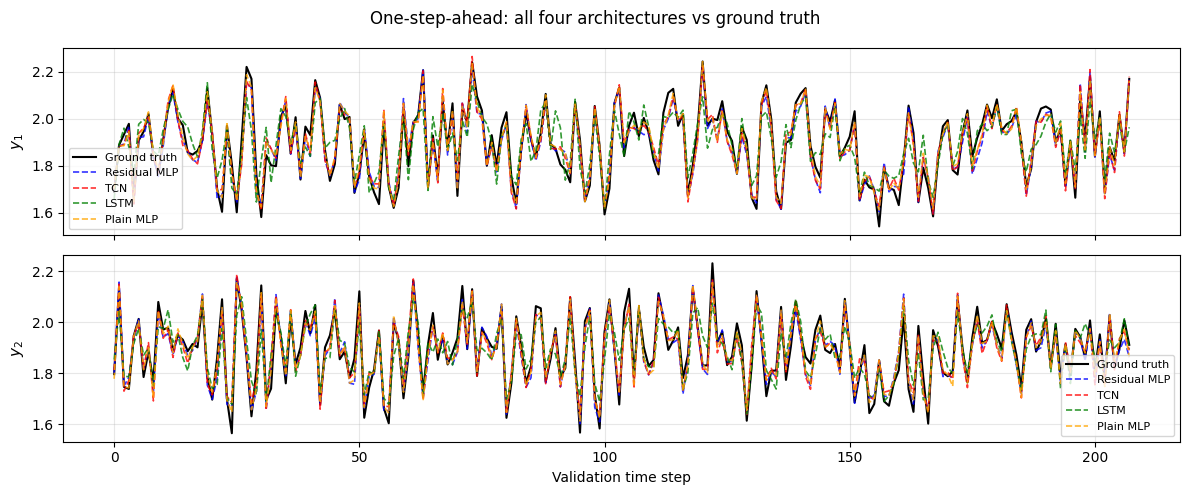


Best architecture on this split: Plain MLP


In [78]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
colors = ['blue', 'red', 'green', 'orange']

for ax, j, lbl in zip(axes, [0, 1], [r'$y_1$', r'$y_2$']):
    ax.plot(y_val_np[:, j], 'k-', lw=1.5, label='Ground truth')
    for (name, mdl, _, _), col in zip(results_dl, colors):
        ax.plot(mdl.predict(X_val_np)[:, j],
                color=col, linestyle='--', lw=1.2, alpha=0.8, label=name)
    ax.set_ylabel(lbl, fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Validation time step')
plt.suptitle('One-step-ahead: all four architectures vs ground truth', fontsize=12)
plt.tight_layout()
plt.show()

best_dl_name, best_dl_model, _, _ = sorted(results_dl, key=lambda x: x[3])[0]
print(f'\nBest architecture on this split: {best_dl_name}')

#### Deep learning candidates inside the MISMO pipeline

The MISMO pipeline evaluates both classical and deep regressors through the same model-selection step.

Candidate deep models are included in `ModelSelector`, and selection is performed with the same direct NMSE objective used for all models.

In [79]:
print('MISMO-only pipeline mode: use the deployment cells below for training and full-horizon prediction.')

MISMO-only pipeline mode: use the deployment cells below for training and full-horizon prediction.


The selected model is the one that minimizes validation error on MISMO block targets.

Because prediction is performed over long horizons, recursive effects can still accumulate during rollout. This is expected in sequence forecasting and is controlled here through block prediction with MISMO.

#### Deep learning for Narx 2
On the same note , we just apply the past benchmark of models and adding models to the pipeline for Narx 2 to get its own results .

In [80]:
#NARX2 raw DL benchmark 
split_idx2 = int(0.70 * len(X_narx2))
X_tr_np2  = np.asarray(X_narx2)[:split_idx2]
X_val_np2 = np.asarray(X_narx2)[split_idx2:]
y_tr_np2  = np.asarray(target_narx2)[:split_idx2]
y_val_np2 = np.asarray(target_narx2)[split_idx2:]

configs2 = [
    ('Residual MLP', TorchNARXRegressor(arch='residual_mlp', hidden_dim=256, n_blocks=4,
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('TCN', TorchNARXRegressor(arch='tcn', tcn_channels=128, tcn_levels=4, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('LSTM', TorchNARXRegressor(arch='lstm', lstm_hidden=128, n_lstm_layers=2, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('Plain MLP', TorchNARXRegressor(arch='mlp', hidden_sizes=(256, 128, 64),
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
]

results_dl_narx2 = []
for name, model in configs2:
    print(f'\n{"="*50}\nTraining NARX2: {name}\n{"="*50}')
    model.fit(X_tr_np2, y_tr_np2)
    y_pred = model.predict(X_val_np2)
    r, n = rmse(y_val_np2, y_pred), nmse(y_val_np2, y_pred)
    print(f'{name}: RMSE={r:.4f}  NMSE={n:.4f}')
    results_dl_narx2.append((name, model, r, n))

print('\n-- NARX2 One-step-ahead results (sorted by NMSE) --')
for name, _, r, n in sorted(results_dl_narx2, key=lambda x: x[3]):
    print(f'  {name:<18} RMSE={r:.4f}  NMSE={n:.4f}')

best_dl_name2, best_dl_model2, _, _ = sorted(results_dl_narx2, key=lambda x: x[3])[0]
print(f'\nBest architecture on NARX2: {best_dl_name2}')


Training NARX2: Residual MLP
Training 3 model(s) -- arch='residual_mlp', device=cpu
  seed=42  epoch=   1  val_mse=0.086705
  seed=42  epoch=  50  val_mse=0.045527
  Early stop at epoch 73  (best val_mse=0.041278)
  seed=43  epoch=   1  val_mse=0.084814
  seed=43  epoch=  50  val_mse=0.048024
  Early stop at epoch 85  (best val_mse=0.041794)
  seed=44  epoch=   1  val_mse=0.093116
  seed=44  epoch=  50  val_mse=0.046579
  Early stop at epoch 79  (best val_mse=0.041034)
Residual MLP: RMSE=0.1052  NMSE=0.0534

Training NARX2: TCN
Training 3 model(s) -- arch='tcn', device=cpu
  seed=42  epoch=   1  val_mse=0.491976
  seed=42  epoch=  50  val_mse=0.048560
  Early stop at epoch 85  (best val_mse=0.038373)
  seed=43  epoch=   1  val_mse=0.468356
  seed=43  epoch=  50  val_mse=0.044380
  seed=43  epoch= 100  val_mse=0.041009
  Early stop at epoch 104  (best val_mse=0.038877)
  seed=44  epoch=   1  val_mse=0.496624
  seed=44  epoch=  50  val_mse=0.043440
  seed=44  epoch= 100  val_mse=0.04154

In [81]:
print('MISMO-only pipeline mode: use the deployment cells below for training and full-horizon prediction.')

MISMO-only pipeline mode: use the deployment cells below for training and full-horizon prediction.


## Task 5. Deployment of the Methodology

The methodology developed in the previous sections is now applied to generate 1000-step-ahead predictions for an unknown NARX model.

### Step 1: Data Acquisition and Preprocessing
The initial phase of deployment involves loading the experimental data provided for the unknown NARX model. The dataset is organized into distinct training and test sets, comprising the following components:

* Utr: Training input series (u1, u2) represented as a NumPy array with shape (1000, 2).
* Ytr: Training output series (y1, y2) represented as a NumPy array with shape (1000, 2).
* Uts1: First test input series, utilized for competition leaderboard validation.
* Uts2: Second test input series, used to determine the final project ranking score.

The data are loaded from the StudentdataNARX.npz file to initiate the analysis.

In [90]:
# 1. Load data
seed = 8
np.random.seed(seed)

## dataset path
if (Path.cwd() / 'src').exists():
    PROJECT_ROOT = Path.cwd()
else:
    PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

np.set_printoptions(suppress=True, precision=4)

dataset_path = Path('StudentdataNARX.npz')
if not dataset_path.exists():
    raise FileNotFoundError(f'Dataset not found: {dataset_path}')

data = np.load(dataset_path)
required_keys = ['Utr', 'Ytr', 'Uts1', 'Uts2']
missing = [k for k in required_keys if k not in data.files]
if missing:
    raise KeyError(f'Missing arrays in dataset: {missing}')

# TRAIN DATA
Utr = np.asarray(data['Utr'], dtype=float)
Ytr = np.asarray(data['Ytr'], dtype=float)

t_u1 = Utr[:,0]
t_u2 = Utr[:,1]
t_y1 = Ytr[:,0]
t_y2 = Ytr[:,1]

# train in data frame
df = pd.DataFrame({
    'u1(k)': Utr[:,0],
    'u2(k)': Utr[:,1],
    'y1(k)': Ytr[:,0],
    'y2(k)': Ytr[:,1]
})

print(df.describe())

## TEST DATA
Uts1= np.asarray(data['Uts1'], dtype=float)
Uts2= np.asarray(data['Uts2'], dtype=float)

te_u1_i1 = Uts1[:,0]
te_u1_i2 = Uts1[:,1]
te_u2_i1 = Uts2[:,0]
te_u2_i2 = Uts2[:,1]

# 2. Add noise
var= 0.01
N = t_u1.size
sigma = np.sqrt(var)
w1 = np.random.normal(loc=0,scale=sigma,size=N)
w2 = np.random.normal(loc=0,scale=sigma,size=N)

             u1(k)        u2(k)        y1(k)        y2(k)
count  1000.000000  1000.000000  1000.000000  1000.000000
mean     -0.026809    -0.034315    -0.017720    -0.376882
std       0.614232     0.611573     0.220595     0.579711
min      -2.369137    -2.220139    -2.072976    -4.856286
25%      -0.448831    -0.465937    -0.057472    -0.619212
50%      -0.031234    -0.040207    -0.001282    -0.247463
75%       0.374932     0.379611     0.047693    -0.006372
max       1.791663     1.613999     1.950458     1.071298


#### Creation of a dataframe to train the pipeline. 

As in previous steps, the initial task in generating one-step or multi-step ahead predictions is to train the pipeline using the training data provided in the file. Therefore, we first select the relevant training data and then merge all components into a pandas DataFrame containing the following values.

$$
u_1^{tr}(k),\ u_2^{tr}(k),\ y_1^{tr}(k),\ y_2^{tr}(k) \quad k=1, \dots, N_{tr} = 1000. 
$$

As in previous steps, we will also add the initial conditions at the beginning of the DataFrame to ensure better alignment between the values and the row indices. the row index.

In [91]:
# Training data
Utr = np.asarray(data['Utr'], dtype=float)
Ytr = np.asarray(data['Ytr'], dtype=float)

df_data = pd.DataFrame({
    'u1(k)': Utr[:, 0],
    'u2(k)': Utr[:, 1],
    'y1(k)': Ytr[:, 0],
    'y2(k)': Ytr[:, 1],
})
df_data.head()

,u1(k),u2(k),y1(k),y2(k)
0,1.225856,0.043213,0.000000,0.000000
1,-0.379083,-0.411898,0.042170,0.720120
2,0.683140,-0.921644,-0.016521,-0.222306
3,0.374853,-0.572683,-0.235810,0.020866
4,0.256665,-0.760764,-0.080339,-0.352666


#### Extraction of Output Vectors and Feature Matrices
Following the creation of the dataframe containing initial conditions and training data, the next step is to extract the output vectors and the data required for the LaggedTransformer class to generate the feature matrix. This process follows the same logic as previously applied during the pipeline construction.

To obtain the output vectors, the output columns from the original dataframe are shifted by one position. The final row, which contains NaN values and is not utilized for model training, is subsequently discarded.

In [92]:
y_data = df_data[['y1(k)', 'y2(k)']].shift(-1).rename(columns={'y1(k)': 'y1(k+1)','y2(k)': 'y2(k+1)'})
y_data = y_data.iloc[:-1].reset_index(drop=True)
y_data

,y1(k+1),y2(k+1)
0,0.042170,0.720120
1,-0.016521,-0.222306
2,-0.235810,0.020866
3,-0.080339,-0.352666
4,-0.087198,-0.107057
...,...,...
994,0.054010,-0.811267
995,0.076635,-0.082176
996,-0.163845,-0.378072
997,0.017180,-0.398397


To obtain the features matrix using the pipeline transformer, the original dataframe is used with the last row removed. This row corresponds to features that would have been used to predict the final NaN values in the output vectors.

In [93]:
data_df = df_data.iloc[:-1].reset_index(drop=True)
data_df

,u1(k),u2(k),y1(k),y2(k)
0,1.225856,0.043213,0.000000,0.000000
1,-0.379083,-0.411898,0.042170,0.720120
2,0.683140,-0.921644,-0.016521,-0.222306
3,0.374853,-0.572683,-0.235810,0.020866
4,0.256665,-0.760764,-0.080339,-0.352666
...,...,...,...,...
994,-0.286226,0.104715,-0.084960,-0.198725
995,0.346771,0.532575,0.054010,-0.811267
996,-0.832074,-0.479654,0.076635,-0.082176
997,0.272503,0.511913,-0.163845,-0.378072


### Step 2: MISMO Pipeline Training Procedure

After preparing the data and targets, training proceeds using a pipeline that exclusively employs MISMO components:

1. The `MismoTransformer` selects the parameters `(d, n_a, s)` and constructs block features.

2. The `SimpleImputer` addresses leading missing values resulting from lag or block construction.

3. The `ModelSelector` evaluates candidate regressors and retains the optimal model.

The pipeline is trained by invoking the `.fit(...)` method on the training data and corresponding targets.

In [94]:
class ModelSelector(BaseEstimator, RegressorMixin):
    """Model selector for MISMO block targets (direct NMSE objective)."""

    def __init__(
        self,
        deep_candidates: Optional[List[Dict[str, Any]]] = None,
        random_state: int = 42,
        verbose: bool = True,
    ):
        self.deep_candidates = deep_candidates
        self.random_state = random_state
        self.verbose = verbose

    def _candidate_spaces(self):
        spaces = []
        spaces.append(('Linear Regression', lambda: make_pipeline(StandardScaler(), LinearRegression()), {}, 'classical'))
        for alpha in [0.1, 1.0, 10.0, 100.0]:
            spaces.append((f'Ridge(alpha={alpha})', lambda a=alpha: make_pipeline(StandardScaler(), Ridge(alpha=a)), {'alpha': alpha}, 'classical'))
        for k_n in [3, 5, 10, 20]:
            spaces.append((f'KNN(k={k_n})', lambda kn=k_n: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=kn)), {'n_neighbors': k_n}, 'classical'))
        for n_est in [100, 300]:
            for max_d in [5, 10, None]:
                for msl in [2, 5]:
                    spaces.append((
                        f'RF(n={n_est}, depth={max_d}, msl={msl})',
                        lambda ne=n_est, md=max_d, ml=msl: RandomForestRegressor(
                            n_estimators=ne,
                            max_depth=md,
                            min_samples_leaf=ml,
                            random_state=self.random_state,
                            n_jobs=-1,
                        ),
                        {'n_estimators': n_est, 'max_depth': max_d, 'min_samples_leaf': msl},
                        'classical',
                    ))

        if _TORCH_AVAILABLE:
            deep_spaces = self.deep_candidates or [
                {'name': 'Deep MLP small', 'params': {'arch': 'mlp', 'hidden_sizes': (64, 32), 'max_epochs': 200, 'patience': 20, 'dropout': 0.10}},
                {'name': 'Deep MLP large', 'params': {'arch': 'mlp', 'hidden_sizes': (256, 128, 64), 'max_epochs': 300, 'patience': 25, 'dropout': 0.15}},
            ]
            for spec in deep_spaces:
                params = dict(spec.get('params') or {})
                params.setdefault('random_state', self.random_state)
                spaces.append((spec.get('name', 'Deep Model'), lambda p=params: TorchNARXRegressor(**p), params, 'deep'))

        return spaces

    def fit(self, X, y):
        X_arr = np.asarray(X)
        y_np = np.asarray(y)
        if y_np.ndim == 1:
            y_np = y_np.reshape(-1, 1)

        tscv = TimeSeriesSplit(n_splits=5)
        tr_idx, va_idx = list(tscv.split(X_arr))[-1]
        X_tr = X_arr[tr_idx]
        X_va = X_arr[va_idx]
        y_tr = y_np[tr_idx]
        y_va = y_np[va_idx]

        candidates: List[Dict[str, Any]] = []

        for name, builder, params, kind in self._candidate_spaces():
            try:
                model = builder()
                model.fit(X_tr, y_tr)
                score, diverged = _direct_nmse_score(model, X_va, y_va)
            except Exception as exc:
                model, score, diverged = None, np.inf, True
                if self.verbose:
                    print(f"  {name:<28s} FAILED: {type(exc).__name__}: {str(exc)[:80]}")
                continue

            if self.verbose:
                tag = '  DIVERGED' if diverged else ''
                print(f"  {name:<28s} direct NMSE = {score:.4f}{tag}")

            candidates.append({
                'name': name,
                'score': float(score),
                'builder': builder,
                'model': model,
                'params': params,
                'kind': kind,
                'diverged': diverged,
            })

        if not candidates:
            raise RuntimeError('No candidate models were evaluated.')

        non_diverged = [c for c in candidates if not c['diverged']]
        pool = non_diverged if non_diverged else candidates
        best = min(pool, key=lambda c: c['score'])

        final_model = best['builder']()
        final_model.fit(X_arr, y_np)

        self.best_name_ = best['name']
        self.best_params_ = best.get('params', {})
        self.best_score_ = float(best['score'])
        self.best_model_ = final_model
        self.candidates_ = candidates

        if self.verbose:
            print(f"\n>>> Best: {self.best_name_} (direct NMSE = {self.best_score_:.4f})")

        return self

    def predict(self, X):
        return self.best_model_.predict(X)


In [95]:
class MismoParameterSelector:
    """Selects (d, na, s) for MISMO on a chronological validation split."""

    def __init__(self, u_train, y_train, val_ratio=0.30, random_state=42):
        self.u_train = np.asarray(u_train, dtype=float)
        self.y_train = np.asarray(y_train, dtype=float)
        self.val_ratio = float(val_ratio)
        self.random_state = int(random_state)

    def estimate_delay_candidates(self, max_lag=40, max_d=10):
        base_selector = ParameterSelector(self.u_train, self.y_train, val_ratio=self.val_ratio, random_state=self.random_state)
        return base_selector.estimate_delay_candidates(max_lag=max_lag, max_d=max_d)

    def search(self, order_grid, verbose=False):
        n = len(self.u_train)
        split = int(n * (1.0 - self.val_ratio))
        U_tr, U_val = self.u_train[:split], self.u_train[split:]
        Y_tr, Y_val = self.y_train[:split], self.y_train[split:]

        rows = []
        for params in ParameterGrid(order_grid):
            d = int(params['d'])
            na = int(params['na'])
            s = int(params['s'])
            if len(U_val) < s or len(U_tr) <= d + na + s:
                continue
            model = train_mismo(U_tr, Y_tr, d, na, s)
            y_hat = mismo_rollout(model, U_val, d, na, s, y_prefix=None)
            rows.append({'d': d, 'na': na, 's': s, 'nmse_val': nmse(Y_val, y_hat), 'rmse_val': rmse(Y_val, y_hat)})

        if not rows:
            return pd.DataFrame()

        df = pd.DataFrame(rows).sort_values(['nmse_val', 'rmse_val']).reset_index(drop=True)
        if verbose:
            print(df.head(10).to_string(index=False))
        return df

    @staticmethod
    def best_config(results):
        if results.empty:
            raise ValueError('results is empty; cannot extract best MISMO configuration.')
        row = results.iloc[0]
        return {'d': int(row['d']), 'na': int(row['na']), 's': int(row['s'])}


In [96]:
class MismoTransformer(BaseEstimator, TransformerMixin):
    """Builds MISMO feature blocks and auto-selects d, na, s when needed."""

    def __init__(
        self,
        d=None,
        na=None,
        s=None,
        order_grid=None,
        val_ratio=0.30,
        random_state=42,
        max_lag=40,
        max_d=10,
    ):
        self.d = d
        self.na = na
        self.s = s
        self.order_grid = order_grid
        self.val_ratio = val_ratio
        self.random_state = random_state
        self.max_lag = max_lag
        self.max_d = max_d

    def fit(self, X, y=None):
        X_df = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        u_train = X_df[['u1(k)', 'u2(k)']].to_numpy(dtype=float)

        if y is None:
            y_train = X_df[['y1(k)', 'y2(k)']].to_numpy(dtype=float)
        else:
            y_train = np.asarray(y, dtype=float)

        if self.d is None or self.na is None or self.s is None:
            selector = MismoParameterSelector(u_train, y_train, val_ratio=self.val_ratio, random_state=self.random_state)
            if self.order_grid is None:
                d_candidates, _ = selector.estimate_delay_candidates(max_lag=self.max_lag, max_d=self.max_d)
                order_grid = {'d': d_candidates, 'na': list(range(1, 9)), 's': [1, 5, 10, 20, 50, 100]}
            else:
                order_grid = self.order_grid

            results = selector.search(order_grid)
            if results.empty:
                raise RuntimeError('MISMO parameter selection returned no valid configuration.')
            best = selector.best_config(results)
            self.d_, self.na_, self.s_ = best['d'], best['na'], best['s']
            self.selection_results_ = results
        else:
            self.d_, self.na_, self.s_ = int(self.d), int(self.na), int(self.s)

        self.y_train_ = y_train
        return self

    def transform(self, X):
        X_df = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        Y = X_df[['y1(k)', 'y2(k)']].to_numpy(dtype=float)
        U = X_df[['u1(k)', 'u2(k)']].to_numpy(dtype=float)

        d, na, s = self.d_, self.na_, self.s_
        rows = []
        for k in range(d + na, len(Y) - s):
            feat = []
            for lag in range(d, d + na + 1):
                feat.extend(Y[k - lag])
            for h in range(1, s + 1):
                feat.extend(U[k + h])
            rows.append(feat)

        y1_cols = [f'y1(k-{i})' for i in range(d, d + na + 1)]
        y2_cols = [f'y2(k-{i})' for i in range(d, d + na + 1)]
        u1_cols = [f'u1(k+{h})' for h in range(1, s + 1)]
        u2_cols = [f'u2(k+{h})' for h in range(1, s + 1)]
        return pd.DataFrame(rows, columns=y1_cols + y2_cols + u1_cols + u2_cols)



In [104]:
def _direct_nmse_score(model, X_val, y_val, max_explosion=1e4):
    """Direct multi-output NMSE scorer used for MISMO block targets."""
    try:
        pred = np.asarray(model.predict(X_val), dtype=float)
    except Exception:
        return np.inf, True

    y_ref = np.asarray(y_val, dtype=float)
    if pred.ndim == 1:
        pred = pred.reshape(-1, 1)
    if y_ref.ndim == 1:
        y_ref = y_ref.reshape(-1, 1)

    if pred.shape != y_ref.shape:
        return np.inf, True
    if not np.all(np.isfinite(pred)) or np.max(np.abs(pred)) > max_explosion:
        return np.inf, True

    score = nmse(y_ref, pred)
    diverged = (not np.isfinite(score)) or score > 5.0
    return float(score), bool(diverged)

def build_mismo_targets(y_series, d, na, s):
    y_series = np.asarray(y_series, dtype=float)
    rows = []
    for k in range(d + na, len(y_series) - s):
        rows.append(y_series[k + 1:k + s + 1].reshape(-1))
    return np.asarray(rows, dtype=float)


def make_mismo_pipeline(d=None, na=None, s=None, order_grid=None, verbose=True):
    """MISMO pipeline with integrated parameter/model selection and rollout prediction."""
    transformer = MismoTransformer(d=d, na=na, s=s, order_grid=order_grid)
    pipe = Pipeline([
        ('transformer', transformer),
        ('imputer', SimpleImputer(strategy='constant', fill_value=0.0)),
        ('model', ModelSelector(verbose=verbose)),
    ])

    def fit_mismo(X, y=None):
        X_df = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        if y is None:
            y_raw = X_df[['y1(k)', 'y2(k)']].to_numpy(dtype=float)
        else:
            y_raw = np.asarray(y, dtype=float)

        trans = pipe.named_steps['transformer']
        trans.fit(X_df, y_raw)
        X_feat = trans.transform(X_df)
        y_block = build_mismo_targets(y_raw, trans.d_, trans.na_, trans.s_)

        X_imp = pipe.named_steps['imputer'].fit_transform(X_feat)
        pipe.named_steps['model'].fit(X_imp, y_block)
        return pipe

    def predict_mismo(U_test, y_init=None):
        U_np = np.asarray(U_test[['u1(k)', 'u2(k)']] if isinstance(U_test, pd.DataFrame) else U_test, dtype=float)
        trans = pipe.named_steps['transformer']
        model = pipe.named_steps['model'].best_model_
        warm = trans.y_train_ if y_init is None else np.asarray(y_init, dtype=float)
        return mismo_rollout(model, U_np, d=trans.d_, na=trans.na_, s=trans.s_, y_prefix=warm)

    pipe.fit = fit_mismo
    pipe.predict = predict_mismo
    return pipe

In [ ]:
mismo_order_grid_real = {
    'd': list(range(1, 10)),
    'na': list(range(1, 10)),
    's': [1, 5, 10, 20, 50, 100, 200],
}

X_train_mismo_real = make_pipeline_df(Utr, Ytr)
pipeline_Real = make_mismo_pipeline(order_grid=mismo_order_grid_real)

print('Fitting MISMO pipeline on real training data...')
pipeline_Real.fit(X_train_mismo_real, Ytr)

trans = pipeline_Real.named_steps['transformer']
selector = pipeline_Real.named_steps['model']
print(f'\nSelected MISMO parameters: d={trans.d_}, na={trans.na_}, s={trans.s_}')
print(f'Selected model: {selector.best_name_}  (direct NMSE on validation = {selector.best_score_:.4f})')

Fitting MISMO pipeline on real training data...


### Step 3: Evaluation of the Testing Pipeline
The trained pipeline is utilized to generate multiple-steps-ahead predictions using the test set.

Once the pipeline is trained, generating multiple-steps-ahead predictions becomes a straightforward process. As in previous steps, the test data from the two test series in the npz file must first be collected into two pandas dataframes.

#### Creation of the two test dataframes

Let us first create a dataframe from the input series Uts1 for the competition leaderboard.

In [ ]:
# Test data
Uts1= np.asarray(data['Uts1'], dtype=float)

df_test_1 = pd.DataFrame({
    'u1(k)': Uts1[:,0],
    'u2(k)': Uts1[:,1],
})

df_test_1

,u1(k),u2(k)
0,1.228846,0.065164
1,-0.399744,-0.363052
2,0.679722,-0.856440
3,0.373389,-0.486696
4,0.185844,-0.644781
...,...,...
995,0.229768,0.474823
996,-0.994510,-0.356657
997,0.201527,0.689125
998,0.626960,0.483980


In [ ]:
# Then, we can create the second test dataframe from the
# Uts2 series to be used for the project ranking. 
Uts2= np.asarray(data['Uts2'], dtype=float)

df_test_2 = pd.DataFrame({
    'u1(k)': Uts2[:,0],
    'u2(k)': Uts2[:,1],
})

df_test_2

,u1(k),u2(k)
0,0.732373,0.393403
1,-0.849970,-0.004611
2,0.341735,-0.396047
3,0.146031,0.059702
4,0.002360,-0.096030
...,...,...
995,0.293830,0.161538
996,-0.882983,-0.717140
997,0.285015,0.348283
998,0.633944,0.204728


#### Multiple-Step-Ahead Prediction with the MISMO Pipeline
With the two test dataframes and the trained MISMO pipeline, full-horizon predictions can be generated efficiently.

The function `multiple_steps_ahead_pipeline(...)` is invoked, which delegates to the MISMO rollout implemented within `pipeline.predict(...)`.

In [ ]:
y_range = float(np.max(np.abs(Ytr))) * 5.0
print(f'Using clip threshold = {y_range:.2f} (≈ 5× max|Ytr|)')

Yhat1_MISMO = multiple_steps_ahead_pipeline(pipeline_Real, df_test_1, y_init=Ytr, clip_threshold=y_range)
Yhat1 = Yhat1_MISMO
print(f'Yhat1_MISMO stats: min={Yhat1_MISMO.min():.3f}, max={Yhat1_MISMO.max():.3f}, mean={Yhat1_MISMO.mean():.3f}')
Yhat1_MISMO

Using clip threshold = 24.28 (≈ 5× max|Ytr|)


KeyError: "None of [Index(['y1(k)', 'y2(k)'], dtype='object')] are in the [columns]"

In [ ]:
Yhat2_MISMO = multiple_steps_ahead_pipeline(pipeline_Real, df_test_2, y_init=Ytr, clip_threshold=y_range)
Yhat2 = Yhat2_MISMO
print(f'Yhat2_MISMO stats: min={Yhat2_MISMO.min():.3f}, max={Yhat2_MISMO.max():.3f}, mean={Yhat2_MISMO.mean():.3f}')
Yhat2_MISMO

Yhat2 stats: min=-3.420, max=1.052, mean=-0.172


array([[ 0.1325,  0.3645],
       [ 0.0104, -0.9778],
       [-0.0603, -0.0262],
       ...,
       [ 0.0094, -0.239 ],
       [ 0.0353,  0.153 ],
       [ 0.0328, -0.3787]], shape=(1000, 2))

and now using the second one

## Task 6: Submission
As required, we save the MISMO predictions from both test sets in a submission.npz file, which contains Yhat1 and Yhat2.

In [ ]:
# We check MISMO prediction shapes and save submission arrays.
Yhat1_MISMO.shape, Yhat2_MISMO.shape
np.savez("submission.npz", Yhat1=Yhat1_MISMO, Yhat2=Yhat2_MISMO)

In [ ]:
def _load_student_data_for_mismo():
    required = ['Utr', 'Ytr', 'Uts1', 'Uts2']
    if all(name in globals() for name in required):
        return np.asarray(Utr, dtype=float), np.asarray(Ytr, dtype=float), np.asarray(Uts1, dtype=float), np.asarray(Uts2, dtype=float)

    candidates = [
        Path('Project/StudentdataNARX.npz'),
        Path('StudentdataNARX.npz'),
        Path.cwd() / 'Project' / 'StudentdataNARX.npz',
        Path.cwd().parent / 'Project' / 'StudentdataNARX.npz',
    ]
    data_path = next((p for p in candidates if p.exists()), None)
    if data_path is None:
        raise FileNotFoundError('StudentdataNARX.npz not found. Run the data-loading section first or place the file in Project/.')

    data = np.load(data_path)
    return (
        np.asarray(data['Utr'], dtype=float),
        np.asarray(data['Ytr'], dtype=float),
        np.asarray(data['Uts1'], dtype=float),
        np.asarray(data['Uts2'], dtype=float),
    )


Utr_m, Ytr_m, Uts1_m, Uts2_m = _load_student_data_for_mismo()
X_mismo_train = make_pipeline_df(Utr_m, Ytr_m)

# Keep this grid moderate to make the search practical in-notebook.
mismo_order_grid = {
    'd': list(range(1, 10)),
    'na': list(range(1, 10)),
    's': [1, 5, 10, 20, 50, 100, 200],
}

pipeline_MISMO = make_mismo_pipeline(order_grid=mismo_order_grid, verbose=True)
print('Fitting MISMO pipeline...')
pipeline_MISMO.fit(X_mismo_train, Ytr_m)

chosen = pipeline_MISMO.named_steps['transformer']
print(f"Selected MISMO parameters: d={chosen.d_}, na={chosen.na_}, s={chosen.s_}")
print(f"Selected model: {pipeline_MISMO.named_steps['model'].best_name_}")

Uts1_df = pd.DataFrame(Uts1_m, columns=['u1(k)', 'u2(k)'])
Uts2_df = pd.DataFrame(Uts2_m, columns=['u1(k)', 'u2(k)'])

Yhat1_MISMO = pipeline_MISMO.predict(Uts1_df, y_init=Ytr_m)
Yhat2_MISMO = pipeline_MISMO.predict(Uts2_df, y_init=Ytr_m)

print(f'Yhat1_MISMO shape: {Yhat1_MISMO.shape}')
print(f'Yhat2_MISMO shape: {Yhat2_MISMO.shape}')

Fitting MISMO pipeline...
  Linear Regression            direct NMSE = 0.5587
  Ridge(alpha=0.1)             direct NMSE = 0.5586
  Ridge(alpha=1.0)             direct NMSE = 0.5584
  Ridge(alpha=10.0)            direct NMSE = 0.5563
  Ridge(alpha=100.0)           direct NMSE = 0.5532
  KNN(k=3)                     direct NMSE = 0.8389
  KNN(k=5)                     direct NMSE = 0.7965
  KNN(k=10)                    direct NMSE = 0.7551
  KNN(k=20)                    direct NMSE = 0.7575
  RF(n=100, depth=5, msl=2)    direct NMSE = 0.8638
  RF(n=100, depth=5, msl=5)    direct NMSE = 0.8447
  RF(n=100, depth=10, msl=2)   direct NMSE = 0.7626
  RF(n=100, depth=10, msl=5)   direct NMSE = 0.7547
  RF(n=100, depth=None, msl=2) direct NMSE = 0.7459
  RF(n=100, depth=None, msl=5) direct NMSE = 0.7496
  RF(n=300, depth=5, msl=2)    direct NMSE = 0.8626
  RF(n=300, depth=5, msl=5)    direct NMSE = 0.8435
  RF(n=300, depth=10, msl=2)   direct NMSE = 0.7535
  RF(n=300, depth=10, msl=5)   direct 

In [ ]:
np.savez("submission.npz", Yhat1=Yhat1_MISMO, Yhat2=Yhat2_MISMO)